> **About this notebook.** This is my own end-to-end pipeline for a five-person team project: EDA, cleaning and features in Part 1 (my workstream in the team), plus an **independent modelling pipeline** in Part 2 that I built alongside the team's final model.
> The team's final model was built by **a teammate (the modelling lead)** and is *not* this one. This pipeline catches **70.1%** of next-year ST cases in its riskiest 10% on the 2020-2022 test years (108 of 154); a simple ROA ranking catches **74.0%** on the same test, so this model does **not** beat that baseline on the headline metric. Its edge is at the top 5% of the list, with yearly refits, two years ahead, and in giving reasons per firm (see section 17).
> Outputs that showed firm-level rows (raw data, the scored watch-list) are removed, because the ZxData dataset is for academic use only. The data is **not** included; put your own licensed copy of `Copy of ST_data.xlsx` in `data/` to run it. Built with help from Claude (AI); every number is pinned by a PASS/CHECK line.


# Notebook 3 · From the Excel file to the watch-list, in one run

**Project:** which normal China A-share firms will be put under ST, \*ST or PT one year (t+1) and two years (t+2) ahead.
**Input:** only `Copy of ST_data.xlsx` (no MySQL needed). **Run time:** about 25 minutes on a 4-core laptop.

This notebook joins the two halves of the project so the whole chain can be run, read and checked in one place:

| Part | What it does | Copied from |
|---|---|---|
| **Part 1 · EDA** (sections 1-9) | load the Excel file, audit and clean it, build the 14 new features, choose the sample and the time split, explore | Notebook 1b v2 (Sivadas's finished EDA), unchanged |
| **Bridge** (Part 2, section 2) | turn the EDA's cleaned table into the modelling table: training-year caps, input lists, indicator families | the same rules as Notebook 2 v2, section 2.2 |
| **Part 2 · Modelling** (sections 3-17) | baselines, five model families, the final test, fairness, top-five indicators, the t+2 model, the 2024 watch-list | Notebook 2 v2, unchanged from its section 3 |

The warehouse route (Excel → `cleaned_data.xlsx` → MySQL star schema → Notebook 2 v2) and this direct route must give the same answers. The bridge checks that value by value against v1's modelling table, and the PASS lines in Part 2 pin the key results.

Every output goes to `v2_star/outputs/end_to_end/` and `v2_star/models/end_to_end/`, so nothing from the other notebooks is overwritten.

# Part 1 · EDA on the core data (Notebook 1b v2)

## 1. Setup

### 1.1 Settings you may change

Every choice the team might want to change is in this one cell. The data file is found automatically if it sits in `pal-breakdown/data/`, in `pal-breakdown/` itself, or in the folder above it (where it is in the project folder). Otherwise set `ST_DATA_PATH` or edit `EXCEL_PATH`.

In [1]:
import os
from pathlib import Path

# This notebook lives in pal-breakdown/v2_star/notebooks/, so the project folder is two levels up
V2_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PROJECT_DIR = V2_DIR.parent

# The core data file: ST_DATA_PATH if it is set, otherwise the first of three usual places that has it
FILE_NAME = "Copy of ST_data.xlsx"
EXCEL_PATH = V2_DIR / "data" / FILE_NAME   # put your copy of the data in data/ (not included in this repo)
for place in [PROJECT_DIR / FILE_NAME, PROJECT_DIR.parent / FILE_NAME]:
    if not EXCEL_PATH.exists() and place.exists():
        EXCEL_PATH = place
if os.environ.get("ST_DATA_PATH"):
    EXCEL_PATH = Path(os.environ["ST_DATA_PATH"])

# Team decisions (the same as Notebook 1; the number on the left is the step that explains each one)
EXCLUDE_FINANCIAL = True          # 6.2  drop banks, insurers and brokers (CSRC section J)
TRAIN_YEARS = (2001, 2017)        # 6.5  feature years, exactly as planned
VALID_YEARS = (2018, 2019)        # 6.5
TEST_YEARS  = (2020, 2022)        # 6.5
OUT_OF_TIME_YEAR = 2023           # 6.5  extra check year
LATEST_YEAR = 2024                # 6.5  watch-list year
INDEP_ZERO_VALID_UNTIL = 2003     # 4.2  0% independent directors is believable up to this year
WINSOR_LIMITS = (0.01, 0.99)      # 4.5  the cap Notebook 1 applies later (shown here, not applied)

# Outputs go to their own folder, so this notebook never overwrites the other notebooks' files
OUT_DIR = V2_DIR / "outputs" / "end_to_end"
FIG_DIR = OUT_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
SAVE_CLEANED_XLSX = True          # 9   also write cleaned_data.xlsx (the file 01_staging_load.sql loads)

print("Project folder :", PROJECT_DIR.resolve().name)
print("Core data file :", EXCEL_PATH, "| found:", EXCEL_PATH.exists())

Project folder : pal-breakdown
Core data file : <project>/Copy of ST_data.xlsx | found: True


### 1.2 Libraries, helper functions and chart style

- `expect()` prints `PASS` or `CHECK` against the number this guide expects. This is how the notebook checks itself, the same idea as `sql/03_validate.sql`.
- `log_issue()` records each data-quality finding and the decision taken. The log is saved at the end as `data_quality_log.csv`, ready for the data-quality summary.
- Charts use grey for context, one blue for what matters, and a title that states the finding instead of naming the axes.

In [2]:
import time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Patch
from scipy import stats
from sklearn.metrics import roc_auc_score

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 80)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 80)

CHECKS = []        # every expect() result (saved in 9)
QUALITY_LOG = []   # every data-quality finding and the action taken (saved in 9)

def expect(label, actual, expected, tol=0.0):
    """Print PASS if a result equals the number this guide expects (within tol), otherwise CHECK."""
    actual, expected = float(actual), float(expected)
    result = "PASS" if abs(actual - expected) <= tol else "CHECK"
    CHECKS.append({"notebook": 1, "check": label, "actual": actual, "expected": expected, "result": result})
    if tol > 0 or not expected.is_integer():
        fmt = "{:,.4f}"                       # a decimal number
    elif "year" in label.lower() and 1900 <= expected <= 2100:
        fmt = "{:.0f}"                        # a year, written without a comma
    else:
        fmt = "{:,.0f}"                       # a count
    print(f"{result:<5} | {label}: {fmt.format(actual)} (expected {fmt.format(expected)})")

def expect_text(label, actual, expected):
    """The same as expect(), for text such as a range of years."""
    result = "PASS" if str(actual) == str(expected) else "CHECK"
    CHECKS.append({"notebook": 1, "check": label, "actual": str(actual), "expected": str(expected), "result": result})
    print(f"{result:<5} | {label}: {actual} (expected {expected})")

def log_issue(step, column, issue, rows, action, reason):
    """Record one data-quality finding and the decision taken."""
    QUALITY_LOG.append({"step": step, "column": column, "issue": issue,
                        "rows_affected": int(rows), "action": action, "reason": reason})

# Chart style: grey for context, one blue for what matters, titles that state the finding
INK, INK2, MUTED, GRID, AXIS = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
ACCENT, CONTEXT, SECOND = "#2a78d6", "#c3c2b7", "#eb6834"
DIVERGING = LinearSegmentedColormap.from_list("blue_grey_red", ["#2a78d6", "#f0efec", "#e34948"])
plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white",
    "font.family": "DejaVu Sans", "font.size": 10, "text.color": INK,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.titlepad": 10,
    "axes.labelcolor": INK2, "axes.edgecolor": AXIS, "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "xtick.color": AXIS, "ytick.color": AXIS, "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "legend.frameon": False, "figure.dpi": 110,
})

def save(fig, name, source=None):
    """Save a chart for the slides (outputs/end_to_end/figures/<name>.png) and show it here."""
    if source:
        fig.text(0.01, -0.01, source, fontsize=8, color=MUTED, ha="left", va="top")
    fig.savefig(FIG_DIR / f"{name}.png", dpi=160, bbox_inches="tight")
    plt.show()

# Plain names for the industry groups (manufacturing is split into four divisions)
INDUSTRY_NAMES = {
    "A": "Agriculture", "B": "Mining", "C1": "Mfg: food, drink, textiles",
    "C2": "Mfg: chemicals, pharma, paper", "C3": "Mfg: metals, machinery, electronics",
    "C4": "Mfg: instruments, other", "D": "Utilities", "E": "Construction",
    "F": "Wholesale and retail", "G": "Transport and logistics", "H": "Hotels and catering",
    "I": "IT and software", "J": "Finance", "K": "Real estate", "L": "Leasing, business services",
    "M": "Research, technical services", "N": "Environment, public facilities",
    "O": "Repair, other services", "P": "Education", "Q": "Health, social work",
    "R": "Culture, sports, media", "S": "Conglomerates",
}
print("Libraries loaded. pandas", pd.__version__)

Libraries loaded. pandas 3.0.5


## 2. Load the core data

### 2.1 Read the Excel file

The sheet `ST_data` has one row per listed firm per fiscal year, 2001-2024, with the column names from the data dictionary. We sort it by firm and year so every later step sees each firm's history in order. Nothing is changed while loading.

In [3]:
start = time.time()
raw = pd.read_excel(EXCEL_PATH, sheet_name="ST_data")
raw = raw.sort_values(["stkcd", "year"]).reset_index(drop=True)     # each firm's years in order
for col in ["ST", "ST_next1", "ST_next2", "region_code", "Big4"]:
    raw[col] = pd.to_numeric(raw[col])                               # make sure these are numbers
print(f"Loaded {len(raw):,} rows x {raw.shape[1]} columns from {EXCEL_PATH.name} in {time.time() - start:.1f} s")
raw.head(3)

Loaded 62,669 rows x 48 columns from Copy of ST_data.xlsx in 20.7 s


[Output removed in this repository: it shows firm-level rows from the ZxData dataset, which is licensed for academic use only. Run the notebook with your own copy of the data to see it.]


### 2.2 Is this the expected version of the file?

We check that the file has the size and label totals the whole project was built on, the same ones Notebook 1 and `sql/03_validate.sql` check. A `CHECK` here means the file was changed or refreshed. The analysis still runs, but re-read each result before quoting it.

In [4]:
expect("Rows (firm-years)", len(raw), 62669)
expect("Firms", raw["stkcd"].nunique(), 5365)
expect("First fiscal year", raw["year"].min(), 2001)
expect("Last fiscal year", raw["year"].max(), 2024)
expect("Firm-years under ST (ST = 1)", raw["ST"].sum(), 2129)
expect("Rows with ST_next1 = 1", raw["ST_next1"].sum(), 2179)
expect("Rows with ST_next2 = 1", raw["ST_next2"].sum(), 2147)

PASS  | Rows (firm-years): 62,669 (expected 62,669)
PASS  | Firms: 5,365 (expected 5,365)
PASS  | First fiscal year: 2001 (expected 2001)
PASS  | Last fiscal year: 2024 (expected 2024)
PASS  | Firm-years under ST (ST = 1): 2,129 (expected 2,129)
PASS  | Rows with ST_next1 = 1: 2,179 (expected 2,179)
PASS  | Rows with ST_next2 = 1: 2,147 (expected 2,147)


## 3. Understand the data and audit its quality (nothing is changed yet)

This section only looks. A standard first look is: shape and types, keys and duplicates, missing values, impossible values, and whether related columns agree. Each problem goes into the quality log with the action Section 4 takes, so the cleaning is traceable.

### 3.1 Shape, grain and keys

The *grain* is what one row means. Here one row should be one firm in one fiscal year, so the pair (`stkcd`, `year`) must be unique. A duplicated firm-year would count that firm twice in the model and break the warehouse's grain rule (`UNIQUE (firm_key, time_key)`). We also check for gaps in firms' histories, because a gap changes what "last year" means in Section 5.

In [5]:
expect("Firm-years that appear more than once", raw.duplicated(["stkcd", "year"]).sum(), 0)

print("\nFirms per fiscal year:")
print(raw.groupby("year")["stkcd"].nunique().to_frame("firms").T.to_string())

# A firm with data from 2005 to 2010 should have 6 rows; fewer means a missing year in between
span = raw.groupby("stkcd")["year"].agg(["min", "max", "nunique"])
span["gap_years"] = (span["max"] - span["min"] + 1) - span["nunique"]
firms_with_gap = int((span["gap_years"] > 0).sum())
print(f"\nYears of data per firm: median {span['nunique'].median():.0f}, "
      f"fewest {span['nunique'].min()}, most {span['nunique'].max()}")
print(f"Firms with at least one missing year inside their history: {firms_with_gap:,} of {len(span):,}")
log_issue("3.1", "stkcd, year", "gap years inside some firms' histories", firms_with_gap,
          "lag features use the previous row only if it is the previous year",
          "otherwise 'last year' would silently mean 'two or more years ago'")

PASS  | Firm-years that appear more than once: 0 (expected 0)

Firms per fiscal year:
year   2001  2002  2003  2004  2005  2006  2007  2008  2009  2010  2011  2012  2013  2014  2015  2016  2017  2018  2019  2020  2021  2022  2023  2024
firms  1010  1072  1138  1234  1240  1279  1364  1476  1582  1903  2176  2334  2318  2373  2553  2826  3251  3479  3683  4113  4635  5061  5311  5258

Years of data per firm: median 10, fewest 2, most 24
Firms with at least one missing year inside their history: 647 of 5,365


**What each column is.** The next cell sorts the columns by job. This matters later: identifiers and labels must never be inputs, categories need encoding, and yes/no flags need no scaling.

In [6]:
ROLES = {
    "stkcd": "Identifier", "year": "Identifier",
    "ST": "Status in year t", "ST_next1": "Target t+1", "ST_next2": "Target t+2",
    "ST_source": "Label source (metadata)",
    "industry_code": "Category", "Industry": "Category", "province": "Category", "city": "Category",
    "region_code": "Category",
    "Loss": "Yes/no flag", "Dual": "Yes/no flag", "SOE": "Yes/no flag", "Big4": "Yes/no flag",
    "regulated_industry": "Yes/no flag",
}
roles = pd.DataFrame({"column": raw.columns})
roles["role"] = roles["column"].map(ROLES).fillna("Number (ratio, size or count)")    # every other column
summary = roles.groupby("role").agg(columns=("column", ", ".join), how_many=("column", "size"))
summary.sort_values("how_many", ascending=False)

,columns,how_many
role,,
"Number (ratio, size or count)","stock_code, Size, Lev, ROA, ROE, ATO, Cashflow, INV, FIXED, Growth, Board, I...",32
Category,"industry_code, province, city, region_code, Industry",5
Yes/no flag,"regulated_industry, Loss, Dual, SOE, Big4",5
Identifier,"stkcd, year",2
Label source (metadata),ST_source,1
Status in year t,ST,1
Target t+1,ST_next1,1
Target t+2,ST_next2,1


### 3.2 Duplicate columns

Two columns with the same numbers add nothing and double that information's weight in some models. The data dictionary defines `AgC1_1` exactly like `Mfee` (administrative expenses / revenue) and `AgC2` exactly like `Occupy` (other receivables / total assets), and `stock_code` is the text form of `stkcd`. We test each pair value by value. We also test `ATO` and `AgC1_3`, which the dictionary describes as the same measure (revenue / average total assets).

In [7]:
# Exact copies: compare the two columns row by row (two blanks count as equal)
for a, b in [("Mfee", "AgC1_1"), ("Occupy", "AgC2")]:
    same = (raw[a] == raw[b]) | (raw[a].isna() & raw[b].isna())
    expect(f"Rows where {b} differs from {a}", (~same).sum(), 0)
same_code = raw["stock_code"].astype(str).str.zfill(6) == raw["stkcd"].astype(str).str.zfill(6)
expect("Rows where stock_code differs from stkcd", (~same_code).sum(), 0)
log_issue("3.2", "AgC1_1", "exact copy of Mfee", len(raw), "drop", "a duplicate adds nothing and doubles the weight")
log_issue("3.2", "AgC2", "exact copy of Occupy", len(raw), "drop", "a duplicate adds nothing and doubles the weight")
log_issue("3.2", "stock_code", "text copy of stkcd", len(raw), "drop", "an identifier, not a predictor")

# ATO and AgC1_3 share a definition in the dictionary, but are they the same numbers?
both = raw[["ATO", "AgC1_3"]].dropna()                           # rows where both exist
equal = np.isclose(both["ATO"], both["AgC1_3"], rtol=1e-6)       # equal up to rounding
rho = both["ATO"].corr(both["AgC1_3"], method="spearman")
print(f"\nATO vs AgC1_3, rows where both exist: {len(both):,}; equal in {equal.mean():.1%}; rank correlation {rho:.2f}")
log_issue("3.2", "ATO, AgC1_3", "same definition in the dictionary, different numbers in most rows",
          (~equal).sum(), "keep both; Notebook 2 checks their VIF",
          "neither is a pure copy, so dropping one would lose information")

PASS  | Rows where AgC1_1 differs from Mfee: 0 (expected 0)
PASS  | Rows where AgC2 differs from Occupy: 0 (expected 0)
PASS  | Rows where stock_code differs from stkcd: 0 (expected 0)

ATO vs AgC1_3, rows where both exist: 56,412; equal in 37.9%; rank correlation 0.70


**What the result shows.** `AgC1_1` is an exact copy of `Mfee` and `AgC2` of `Occupy` in every row, and `stock_code` is the text form of `stkcd`, so each is kept once. `ATO` and `AgC1_3` have the same definition in the Data Dictionary but are equal in only 37.9% of the rows where both exist (rank correlation 0.70). Neither is a pure copy, so both stay, and Notebook 2 checks their overlap with VIF.

### 3.3 Missing values

We count the blanks in each column, then ask what kind of gap it is.
- **MCAR**, missing completely at random: the blank has nothing to do with anything.
- **MAR**, missing at random: the blank depends on something we can see, such as the year.
- **MNAR**, missing not at random: the blank depends on the hidden value itself. Simple fills mislead here, so the right move is to flag it and investigate.

Three clues help: do the gaps cluster in certain years, do firms with a blank turn ST more often, and is that difference real or just the year? The third clue is needed because the ST rate itself changes from year to year, so it compares each blank row with the usual ST rate of its own year. We check every input that is at least 1% blank, plus `ROE`, whose blank has a known cause. Columns blank in exactly the same rows tell the same story, so each group is shown once. Nothing is filled in this notebook (see 4.4).

             blank_rows  blank_%      band
AgC1_3             6249     9.97     5-20%
ST_next2           6195     9.89     5-20%
Pay                5071     8.09     5-20%
AgC1_2             4611     7.36     5-20%
Mshare             2936     4.68      1-5%
Balance1           2155     3.44      1-5%
Top10              2153     3.44      1-5%
Top1               2153     3.44      1-5%
Top5               2153     3.44      1-5%
Balance2           2153     3.44      1-5%
AgC1_1             2121     3.38      1-5%
Mfee               2121     3.38      1-5%
INST               1778     2.84      1-5%
INV                1404     2.24      1-5%
Employ             1017     1.62      1-5%
Cap1               1017     1.62      1-5%
Board               981     1.57      1-5%
Indep               981     1.57      1-5%
AgC2                880     1.40      1-5%
Occupy              880     1.40      1-5%
ST_next1            815     1.30      1-5%
ROE                 475     0.76  under 1%
Growth     

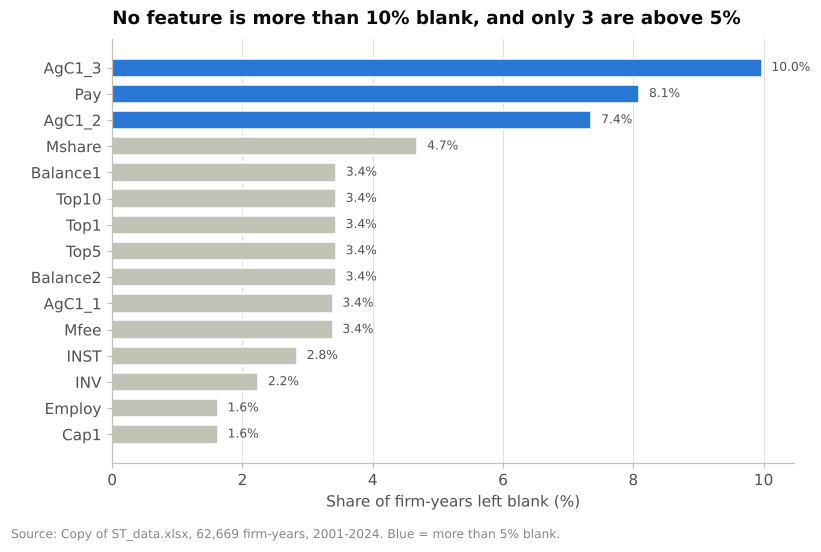

In [8]:
miss = pd.DataFrame({"blank_rows": raw.isna().sum(), "blank_%": raw.isna().mean() * 100})
miss = miss[miss["blank_rows"] > 0].sort_values("blank_%", ascending=False)        # columns with blanks, worst first
miss["band"] = pd.cut(miss["blank_%"], [0, 1, 5, 20, 100], labels=["under 1%", "1-5%", "5-20%", "over 20%"])
print(miss.round(2).to_string())

# Chart: the inputs only (the label columns are checked in 3.7)
feat_miss = miss["blank_%"].drop(["ST", "ST_next1", "ST_next2"], errors="ignore")
top = feat_miss.head(15)[::-1]                                   # the 15 worst, worst at the top
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(top.index, top.values, color=[ACCENT if v > 5 else CONTEXT for v in top.values],
        height=0.7, edgecolor="white", linewidth=1)
for y, v in enumerate(top.values):
    ax.text(v + 0.15, y, f"{v:.1f}%", va="center", fontsize=8, color=INK2)
ax.set_xlabel("Share of firm-years left blank (%)")
ax.grid(axis="y", visible=False)
ax.set_title(f"No feature is more than {np.ceil(feat_miss.max()):.0f}% blank, "
             f"and only {(feat_miss > 5).sum()} are above 5%")
save(fig, "fig01_missing_values", "Source: Copy of ST_data.xlsx, 62,669 firm-years, 2001-2024. Blue = more than 5% blank.")

In [9]:
# Which columns to check: every input at least 1% blank, plus ROE (the exact copies from 3.2 are left out)
COPIES = ["AgC1_1", "AgC2", "stock_code"]
rule = [c for c in feat_miss.index if feat_miss[c] >= 1 and c not in COPIES] + ["ROE"]
rule = sorted(rule, key=lambda c: (-feat_miss[c], c))             # most blank first, ties in name order

# Columns blank in exactly the same rows tell the same story, so each group is shown once
watch, same_as = [], {}
for c in rule:
    twins = [w for w in watch if raw[w].isna().equals(raw[c].isna())]
    if twins:
        same_as.setdefault(twins[0], []).append(c)
    else:
        watch.append(c)
groups = [f"{w} (also {', '.join(cols)})" for w, cols in same_as.items()]
print(f"Columns checked: {len(watch)}. Blank in exactly the same rows, so shown once: {'; '.join(groups)}\n")

# Clue 1: do the gaps cluster in certain years?
period = pd.cut(raw["year"], [2000, 2005, 2010, 2015, 2020, 2024],
                labels=["2001-05", "2006-10", "2011-15", "2016-20", "2021-24"])
print("Blank % by period (clue 1: do the gaps cluster in certain years?)")
print((raw[watch].isna().groupby(period, observed=True).mean() * 100).round(1).T.to_string())

# Clue 2: do normal firms with a blank turn ST more often?
normal_known = raw[(raw["ST"] == 0) & raw["ST_next1"].notna()]    # normal firms with a known t+1 outcome
rows = []
for c in watch:
    blank = normal_known[c].isna()
    rows.append({"blank rows (normal firms)": int(blank.sum()),
                 "% ST next year if blank": 100 * normal_known.loc[blank, "ST_next1"].mean(),
                 "% ST next year if filled": 100 * normal_known.loc[~blank, "ST_next1"].mean()})
print("\nClue 2: do firms with a blank turn ST more often?")
print(pd.DataFrame(rows, index=watch).round(2).to_string())

roe_blank = raw["ROE"].isna()
print(f"\nROE is blank in {roe_blank.sum():,} rows; in {raw.loc[roe_blank, 'Lev'].gt(1).mean():.0%} of them "
      f"debts exceed assets, so equity is negative and ROE cannot be calculated.")

# Clue 3: is a higher ST rate after a blank real, or just the year? (the ST rate itself moves from year to year)
year_rate = normal_known.groupby("year")["ST_next1"].mean()       # the usual ST rate of each year

def seen_vs_expected(part):
    """ST cases seen in these rows, the number their years predict, and seen / expected with its 95% range."""
    seen = int(part["ST_next1"].sum())
    expected = part["year"].map(year_rate).sum()
    if expected == 0:
        return seen, expected, "no rows"
    low = stats.chi2.ppf(0.025, 2 * seen) / 2 if seen > 0 else 0.0     # exact 95% range of a count (Poisson)
    high = stats.chi2.ppf(0.975, 2 * seen + 2) / 2
    return seen, expected, f"{seen / expected:.2f} ({low / expected:.2f} to {high / expected:.2f})"

rows = []
for c in watch:
    blank = normal_known[normal_known[c].isna()]
    seen, expected, ratio = seen_vs_expected(blank)
    rows.append({"blank rows": len(blank), "ST seen": seen, "ST expected from the year": round(expected, 1),
                 "seen / expected (95% range)": ratio,
                 "the same without 2024": seen_vs_expected(blank[blank["year"] != 2024])[2],
                 "blank rows in 2024": int((blank["year"] == 2024).sum())})
print("\nClue 3: ST cases after a blank, against what each row's year predicts (about 1 = no warning)")
print(pd.DataFrame(rows, index=watch).to_string())

# The 2024 governance gap: firms with all seven governance columns blank
GOVERNANCE = ["Board", "Indep", "Employ", "Cap1", "INST", "Pay", "Mshare"]
no_gov = raw[GOVERNANCE].isna().all(axis=1)
is_2024 = raw["year"] == 2024
print(f"\nAll seven governance columns blank: {(no_gov & is_2024).sum():,} of {is_2024.sum():,} firms in 2024, "
      f"{(no_gov & ~is_2024).sum()} rows in all earlier years together.")
normal_2024 = normal_known[normal_known["year"] == 2024]
gap = normal_2024[GOVERNANCE].isna().all(axis=1)
without, rest = normal_2024[gap], normal_2024[~gap]
print(f"Normal firms of 2024 without governance data: {len(without)}; turned ST in 2025: "
      f"{without['ST_next1'].mean():.1%} against {rest['ST_next1'].mean():.1%} for the rest "
      f"(2025 status provisional); made a loss in 2024: {without['Loss'].mean():.0%} against "
      f"{rest['Loss'].mean():.0%}.")

log_issue("3.3", "Pay, Top1-Top10, Balance1-2", "mostly blank in 2001-2004 (not yet reported); no warning once the year is allowed for",
          raw["Pay"].isna().sum(), "fill later with the training median + add a 'was blank' flag",
          "MAR: the gap depends on the year, which we can see")
log_issue("3.3", "ROE", "blank when equity is negative", roe_blank.sum(),
          "fill later with the training median + add a 'was blank' flag",
          "MNAR: the blank itself is a warning sign, so the flag must be kept")
log_issue("3.3", "INST", "blank mostly in 2001-02 and 2024; about twice the ST rate its years predict",
          raw["INST"].isna().sum(), "fill later with the training median + add a 'was blank' flag",
          "the gap carries information about the firm")
log_issue("3.3", "Board, Indep, Employ, Cap1, INST, Pay, Mshare (2024)",
          "no governance data at all for one firm in six in 2024; these firms turn ST more often",
          (no_gov & is_2024).sum(), "keep the firms, fill with the training median + 'was blank' flag; ask the data source why",
          "the training years have almost no such rows, so these firms' scores rest on their financial figures")
log_issue("3.3", "Occupy, AgC1_3", "a blank goes with fewer ST cases than the year predicts",
          raw[["Occupy", "AgC1_3"]].isna().any(axis=1).sum(), "fill later with the training median + add a 'was blank' flag",
          "the flag lets the model use the gap as a sign of lower risk")

Columns checked: 13. Blank in exactly the same rows, so shown once: Balance2 (also Top1, Top10, Top5); Cap1 (also Employ); Board (also Indep)

Blank % by period (clue 1: do the gaps cluster in certain years?)
year      2001-05  2006-10  2011-15  2016-20  2021-24
AgC1_3       22.1      9.7      8.5     11.1      6.5
Pay          70.0      0.9      0.2      0.4      4.5
AgC1_2        7.3      4.2      3.7     13.0      5.8
Mshare        1.5      7.0      3.0      3.3      6.9
Balance1     36.7      0.2      0.1      0.2      0.0
Balance2     36.7      0.2      0.1      0.2      0.0
Mfee          2.7      3.0      3.6      4.6      2.6
INST         13.3      0.5      0.2      0.3      4.5
INV           0.4      1.5      0.3      3.4      3.2
Cap1          0.5      0.7      0.1      0.2      4.3
Board         0.7      0.2      0.1      0.2      4.3
Occupy        0.1      1.5      0.3      2.0      1.9
ROE           1.6      2.0      0.7      0.3      0.5

Clue 2: do firms with a blank turn

**What the result shows.** No input is badly gappy: the worst are `AgC1_3` (10.0% blank), `Pay` (8.1%) and `AgC1_2` (7.4%). The clues cover 13 columns: every input at least 1% blank, plus `ROE`. Columns blank in exactly the same rows are shown once (`Balance2` also stands for `Top1`, `Top5` and `Top10`, `Cap1` for `Employ`, and `Board` for `Indep`).

**Clue 1: most gaps belong to particular years (MAR).**
- The shareholder stakes (`Top1`-`Top10`, `Balance1-2`) are blank for every firm in 2001 and 2002, and `INST` for 44% and 29% of firms in those years. `Pay` is blank for 82-94% of firms in 2001-2004 and for at most 3.4% in any later year before 2024. Most likely these items were not yet reported.
- `AgC1_3` is blank for every firm in 2001, the first year in the file, and for 2-17% of firms in later years. `AgC1_2` and `Mfee` are blank more often before 2022 than after.
- **2024 is different.** One firm in six (875 of 5,258) has no governance data at all: `Board`, `Indep`, `Employ`, `Cap1`, `INST`, `Pay` and `Mshare` are all blank. In all earlier years together this happened in only 77 rows. This is the jump in the 2021-24 column.

**Clue 2 needs care, because the ST rate itself changes by year** (3.6% and 4.5% in 2001 and 2002, 0.7% in 2010, 2.3% in 2024). A column that is blank mainly in high-ST years looks like a warning even when the gap means nothing. Clue 3 corrects for this by comparing each blank row with the usual ST rate of its own year:
- **Real warning: `ROE`.** It is blank when equity is negative (80% of its 475 blank rows have debts above assets), so most of these firms are already ST. Among normal firms it is blank in only 69 rows, and 58 of them (84%) turned ST the next year, about 44 times what their years predict.
- **Smaller real warning: `INST`.** Firms with a blank turn ST about twice as often as their years predict (91 cases against 47 expected), and the excess holds outside 2024 too.
- **Warning in 2024 only: `Board`/`Indep`, `Employ`/`Cap1`, `Pay` and `Mshare`.** The 830 normal firms with no governance data in 2024 made a loss twice as often as the rest (43% against 22%) and turned ST in 2025 more than three times as often (5.4% against 1.6%; the 2025 status is provisional). Before 2024, a blank in these columns says nothing about risk.
- **No warning: the shareholder stakes.** Their higher raw rate (3.9%) is the high ST rate of 2001-2002, the years in which they are blank (80 cases against 81 expected).
- **Lower risk: `Occupy` and `AgC1_3`.** None of the 878 normal firms with a blank `Occupy` turned ST (14 expected), and firms with a blank `AgC1_3` turned ST half as often as their years predict (55 cases against 111). The file does not say why.
- **No clear link: `AgC1_2`, `Mfee` and `INV`.** Every other column is blank in under 0.25% of rows, too few to judge.

**For Notebook 2:** blanks are filled with the training median and a "was blank" flag is added. The fill keeps the row. The flag lets the model use what a gap says, whether a warning (`ROE`, `INST`) or lower risk (`Occupy`, `AgC1_3`). The 2024 governance gap is the exception: the training years have almost no such rows, so the model cannot learn from it, and those firms' 2024 scores rest on their financial figures. Ask the data source why this data is missing before relying on governance reasons in the 2024 watch-list.

### 3.4 Units and scales: independent directors and management ownership

Columns that measure the same kind of thing should use the same unit. Shareholdings (`Top1`, `Top5`, `Top10`, `INST`) are fractions between 0 and 1, but the dictionary says `Indep` is in percent (33.33 means one third) and describes `Mshare` only as "as provided by the vendor". A unit mix-up does not break a tree model, but it distorts charts, capping and logistic-regression coefficients, so we check both columns.

In [10]:
share_cols = ["Indep", "Top1", "Top5", "Top10", "INST", "Mshare"]
print(raw[share_cols].describe(percentiles=[0.01, 0.5, 0.99]).T.round(3).to_string())

# Independent directors: in percent, and a zero is common only in the first years
indep_zero = raw.loc[raw["Indep"] == 0, "year"].value_counts().sort_index()
late_zero = int(((raw["Indep"] == 0) & (raw["year"] > INDEP_ZERO_VALID_UNTIL)).sum())
print("\nFirm-years with 0% independent directors, by year:", indep_zero.to_dict())
print(f"Zeros after {INDEP_ZERO_VALID_UNTIL}: {late_zero}")

# Management ownership: the share of values above 1, by year, and any value above 100
above1 = (raw["Mshare"] > 1).groupby(raw["year"]).mean() * 100
print("\nShare of Mshare values above 1 (%), selected years:",
      above1.loc[[2001, 2005, 2010, 2015, 2020, 2023, 2024]].round(1).to_dict())
print("Mshare values above 100 (impossible for a percent):")
print(raw.loc[raw["Mshare"] > 100, ["stkcd", "year", "Mshare"]].to_string(index=False))

# A 50-200x jump or drop in the same firm from one year to the next suggests a unit switch
this_year = raw[["stkcd", "year", "Mshare"]]
moved_on = this_year.assign(year=this_year["year"] + 1)          # each value moved to the following year
pairs = this_year.merge(moved_on, on=["stkcd", "year"], suffixes=("", "_prev"))
pairs = pairs[(pairs["Mshare"] > 0) & (pairs["Mshare_prev"] > 0)]
ratio = pairs["Mshare"] / pairs["Mshare_prev"]
jumps = int(ratio.between(50, 200).sum())
drops = int(ratio.between(1 / 200, 1 / 50).sum())
print(f"\nConsecutive-year pairs with Mshare > 0 both years: {len(pairs):,}; "
      f"jumps of 50-200x: {jumps}; drops to 1/200-1/50: {drops}")

log_issue("3.4", "Indep", "stored in percent (0-100) while other shares are fractions", len(raw),
          "divide by 100", "one unit for all shares")
log_issue("3.4", "Indep", f"0% independent directors after {INDEP_ZERO_VALID_UNTIL}", late_zero,
          "set to blank", "zeros cluster in 2001-2003; later zeros are almost certainly recording gaps")
log_issue("3.4", "Mshare", "unit unclear; behaves like percent with some firm-level 100x jumps",
          jumps + drops, "treat as percent, divide by 100, keep the jumps, cap in Notebook 1, 8.2",
          "most values and the 1-to-100 range fit a percent; the jumps cannot be fixed without the vendor")

          count    mean     std    min     1%     50%     99%      max
Indep   61688.0  36.580   7.253  0.000  0.000  33.330  57.140  100.000
Top1    60516.0   0.343   0.154  0.003  0.082   0.318   0.742    0.900
Top5    60516.0   0.535   0.158  0.008  0.192   0.537   0.893    0.992
Top10   60516.0   0.584   0.157  0.013  0.224   0.593   0.910    1.038
INST    60891.0   0.446   0.252  0.000  0.002   0.468   0.923    1.073
Mshare  59733.0  12.206  19.254  0.000  0.000   0.166  68.277  268.714

Firm-years with 0% independent directors, by year: {2001: 708, 2002: 27, 2003: 17, 2004: 11, 2005: 2, 2006: 3, 2007: 4, 2008: 2, 2009: 1, 2010: 1, 2024: 1}
Zeros after 2003: 25

Share of Mshare values above 1 (%), selected years: {2001: 0.8, 2005: 5.6, 2010: 29.0, 2015: 44.5, 2020: 52.0, 2023: 56.2, 2024: 45.2}
Mshare values above 100 (impossible for a percent): 1 firm-year [firm and value removed in this repository]



Consecutive-year pairs with Mshare > 0 both years: 40,184; jumps of 50-200x: 137; drops to 1/200-1/50: 148


**What the result shows.** - `Indep` is stored in percent (median 33.33) while every other share is a fraction, so it is divided by 100.
- In 2001, 708 firm-years have 0% independent directors, which fits that period. The 25 zeros after 2003 are almost certainly recording gaps and become blank.
- `Mshare` is the hardest column. Its values run from 0 to 268.7, the share of values above 1 rises from 0.8% in 2001 to over half by 2020, and 285 firm-year pairs show a sudden 50-200x jump or drop. Most values and the 0-100 range fit a percent, so we divide by 100 and blank the single impossible value (268.7). The file has no vendor note on the unit, so this stays a team decision to confirm.

### 3.5 Impossible values

Some values cannot happen in real accounts: negative inventory, a stake above 100%, a listed company with one employee. A data error should be treated as missing, while a value that is real but extreme should be kept and capped (4.5 and Notebook 1, 8.2). The rules below are written once and applied in 4.2, so the audit and the cleaning cannot drift apart.

In [11]:
# column: (why the value is impossible, the rows that have it)
IMPOSSIBLE = {
    "Lev":    ("below 0: debts cannot be negative",                      raw["Lev"] < 0),
    "INV":    ("below 0: inventory cannot be negative",                   raw["INV"] < 0),
    "FIXED":  ("below 0: fixed assets cannot be negative",                raw["FIXED"] < 0),
    "ATO":    ("below 0: revenue / assets cannot be negative",            raw["ATO"] < 0),
    "AgC1_3": ("below 0: revenue / assets cannot be negative",            raw["AgC1_3"] < 0),
    "Mfee":   ("below 0: admin expenses / revenue cannot be negative",    raw["Mfee"] < 0),
    "AgC1_2": ("below 0: selling + admin expenses / revenue below 0",     raw["AgC1_2"] < 0),
    "Top10":  ("above 1: a stake cannot exceed 100%",                     raw["Top10"] > 1),
    "INST":   ("above 1: a stake cannot exceed 100%",                     raw["INST"] > 1),
    "Mshare": ("above 100: a stake cannot exceed 100%",                   raw["Mshare"] > 100),
    "Board":  ("0 or below: ln(directors) = 0 means a one-person board",  raw["Board"] <= 0),
    "Employ": ("1 or fewer employees for a listed company",               raw["Employ"] <= 1),
}
rows = []
for col, (why, bad) in IMPOSSIBLE.items():
    rows.append({"column": col, "why impossible": why, "rows": int(bad.sum())})
    log_issue("3.5", col, why, bad.sum(), "set to blank", "data error, not a real value")
imp = pd.DataFrame(rows)
print(imp.to_string(index=False))
print(f"\nTotal values to set blank: {imp['rows'].sum()} out of {raw.size:,} cells")

column                                         why impossible  rows
   Lev                      below 0: debts cannot be negative     1
   INV                  below 0: inventory cannot be negative     1
 FIXED               below 0: fixed assets cannot be negative     1
   ATO           below 0: revenue / assets cannot be negative     6
AgC1_3           below 0: revenue / assets cannot be negative     7
  Mfee   below 0: admin expenses / revenue cannot be negative    66
AgC1_2    below 0: selling + admin expenses / revenue below 0    40
 Top10                    above 1: a stake cannot exceed 100%     3
  INST                    above 1: a stake cannot exceed 100%     3
Mshare                  above 100: a stake cannot exceed 100%     1
 Board 0 or below: ln(directors) = 0 means a one-person board    14
Employ              1 or fewer employees for a listed company     2

Total values to set blank: 145 out of 3,008,112 cells


### 3.6 Do related columns agree with each other?

Some columns describe the same fact from two sides. `Loss` says whether the firm lost money and `ROA` is profit divided by assets, so a loss-making firm should have a negative ROA. Leverage above 1 means debts are larger than assets, which normally goes with distress. A disagreement can reveal different definitions, and we need to know that before trusting either column.

In [12]:
loss_but_positive = (raw["Loss"] == 1) & (raw["ROA"] > 0)
profit_but_negative = (raw["Loss"] == 0) & (raw["ROA"] < 0)
disagree = loss_but_positive | profit_but_negative
print(f"Loss = 1 but ROA > 0 : {loss_but_positive.sum():,} rows (median ROA {raw.loc[loss_but_positive, 'ROA'].median():.3f})")
print(f"Loss = 0 but ROA < 0 : {profit_but_negative.sum():,} rows (median ROA {raw.loc[profit_but_negative, 'ROA'].median():.3f})")
print(f"Rows where they agree: {1 - disagree.mean():.1%}")

neg_equity = raw["Lev"] > 1                                      # debts larger than assets
print(f"\nDebts larger than assets (Lev > 1): {neg_equity.sum():,} firm-years; "
      f"{raw.loc[neg_equity, 'ST'].mean():.0%} are already ST that year and "
      f"{raw.loc[neg_equity, 'ST_next1'].mean():.0%} are ST the next year")
log_issue("3.6", "Loss vs ROA", "sign disagrees in a small share of rows, always close to zero",
          disagree.sum(), "keep both", "the two use slightly different profit definitions; both carry signal")

Loss = 1 but ROA > 0 : 1,630 rows (median ROA 0.017)
Loss = 0 but ROA < 0 : 532 rows (median ROA -0.020)
Rows where they agree: 96.6%

Debts larger than assets (Lev > 1): 508 firm-years; 72% are already ST that year and 95% are ST the next year


**What the result shows.** `Loss` and `ROA` agree in 96.6% of rows. The 2,162 disagreements sit very close to zero (median ROA +0.017 when `Loss` = 1 and -0.020 when `Loss` = 0). That looks like two slightly different profit lines (net profit for `Loss`, the vendor's basis for `ROA`) rather than errors, so both are kept. This is an inference, because the Data Dictionary does not say which profit line ROA uses. Debts larger than assets (`Lev` > 1) appear in 508 firm-years. 72% of those firms are already ST that year and 95% are ST the next year, which is why `NegEquity` becomes such a strong flag.

### 3.7 Are the labels right?

A model can only be as good as its labels. We check that:
1. the status columns contain only 0, 1 or blank;
2. `ST_next1` equals the firm's `ST` status in the next year and `ST_next2` the status two years later (the code joins each row to the same firm's row one or two years on, like checks A16 to A18 in `sql/03_validate.sql`);
3. the 2024 status is no longer a copy of 2023 (the team refreshed 2024 from CNINFO year-end stock names);
4. where each year's status came from, and whether the file already holds 2025 status;
5. how sticky ST is: once a firm is ST, how often is it still ST a year later? This is why the sample keeps only firms that are normal in year t. Predicting that an ST firm stays ST is easy and not useful.

In [13]:
# 1. Only 0, 1 or blank in the three status columns
counts = pd.DataFrame({col: raw[col].value_counts(dropna=False) for col in ["ST", "ST_next1", "ST_next2"]})
counts = counts.fillna(0).astype(int)
counts.index = ["blank" if pd.isna(v) else int(v) for v in counts.index]
print("Values in the three status columns:")
print(counts.to_string())

# 2. ST_next1 / ST_next2 against the real status 1 and 2 years later (a join, like checks A16 to A18 in sql/03_validate.sql)
real = raw[["stkcd", "year", "ST"]].rename(columns={"year": "later_year", "ST": "real_status"})   # real status of each firm in each year
for h, col, pairs_expected in [(1, "ST_next1", 56559), (2, "ST_next2", None)]:
    rows = raw[["stkcd", "year", col]].assign(later_year=raw["year"] + h).merge(real, on=["stkcd", "later_year"])
    rows = rows.dropna(subset=[col, "real_status"])                 # keep the pairs where both are known
    if pairs_expected:
        expect(f"Pairs where {col} can be checked against year t+{h}", len(rows), pairs_expected)
    else:
        print(f"Pairs where {col} can be checked against year t+{h}: {len(rows):,}")
    expect(f"{col} differs from the real status in year t+{h}", int((rows[col] != rows["real_status"]).sum()), 0)

# 3. 2024 is no longer a copy of 2023
st_2023 = raw[raw["year"] == 2023].set_index("stkcd")["ST"]
st_2024 = raw[raw["year"] == 2024].set_index("stkcd")["ST"]
in_both = st_2023.index.intersection(st_2024.index)
expect("Firms whose ST status changed from 2023 to 2024", (st_2023[in_both] != st_2024[in_both]).sum(), 106)

# 4. Where each year's status came from, and the 2025 status already in the file
print("\nWhere the ST status came from (selected years):")
print(pd.crosstab(raw["year"], raw["ST_source"]).loc[[2001, 2010, 2019, 2020, 2023, 2024]].to_string())
rows_2024, rows_2023 = raw[raw["year"] == 2024], raw[raw["year"] == 2023]
print(f"\n2025 status already in the file: ST_next1 of 2024 rows = {rows_2024['ST_next1'].notna().sum():,} rows "
      f"({int(rows_2024['ST_next1'].sum())} ST); ST_next2 of 2023 rows = {rows_2023['ST_next2'].notna().sum():,} rows "
      f"({int(rows_2023['ST_next2'].sum())} ST)")

# 5. How sticky ST is
stay = raw.loc[raw["ST"] == 1, "ST_next1"].mean()
print(f"\nOf firms that are ST in year t, {stay:.0%} are still ST in year t+1")
log_issue("3.7", "ST", "3 firm-years with unknown status (2020, source 'missing')",
          raw["ST"].isna().sum(), "exclude from the sample", "we cannot tell whether they were normal in year t")
log_issue("3.7", "ST_next1 (2024 rows), ST_next2 (2023 rows)", "2025 status present; source not documented",
          rows_2024["ST_next1"].notna().sum(), "use only as a flagged extra check, not for tuning or the official test",
          "the data documentation covers labels up to 2024 only; confirm the 2025 source with the team")

Values in the three status columns:
          ST  ST_next1  ST_next2
0      60537     59675     54327
1       2129      2179      2147
blank      3       815      6195
PASS  | Pairs where ST_next1 can be checked against year t+1: 56,559 (expected 56,559)
PASS  | ST_next1 differs from the real status in year t+1: 0 (expected 0)
Pairs where ST_next2 can be checked against year t+2: 51,166
PASS  | ST_next2 differs from the real status in year t+2: 0 (expected 0)
PASS  | Firms whose ST status changed from 2023 to 2024: 106 (expected 106)

Where the ST status came from (selected years):


ST_source  cninfo year-end name  cninfo year-end name (vendor gap)  missing  vendor
year                                                                               
2001                          0                                  3        0    1007
2010                          0                                  2        0    1901
2019                          0                                  0        0    3683
2020                          0                                  0        3    4110
2023                          0                                  0        0    5311
2024                       5258                                  0        0       0

2025 status already in the file: ST_next1 of 2024 rows = 5,253 rows (178 ST); ST_next2 of 2023 rows = 5,258 rows (181 ST)

Of firms that are ST in year t, 59% are still ST in year t+1


**What the result shows.** The labels are internally consistent. `ST_next1` equals the firm's real status a year later in all 56,559 pairs that can be checked, and `ST_next2` matches two years later in all 51,166. The 2024 status, refreshed from CNINFO year-end names, differs from 2023 for 106 firms, so it is no longer a copy of 2023. ST is sticky: 59% of firms that are ST in a year are still ST the next. The file also holds a 2025 status (5,253 rows for t+1, 5,258 for t+2) whose source is not documented. It is used only for the flagged 2025 forward check in Notebook 2.

### 3.8 The quality log so far

Every finding from Section 3, with the action Section 4 (or Notebook 2) takes. This table is saved in section 9 as `outputs/end_to_end/data_quality_log.csv`.

In [14]:
pd.DataFrame(QUALITY_LOG)

,step,column,issue,rows_affected,action,reason
0,3.1,"stkcd, year",gap years inside some firms' histories,647,lag features use the previous row only if it is the previous year,otherwise 'last year' would silently mean 'two or more years ago'
1,3.2,AgC1_1,exact copy of Mfee,62669,drop,a duplicate adds nothing and doubles the weight
2,3.2,AgC2,exact copy of Occupy,62669,drop,a duplicate adds nothing and doubles the weight
3,3.2,stock_code,text copy of stkcd,62669,drop,"an identifier, not a predictor"
4,3.2,"ATO, AgC1_3","same definition in the dictionary, different numbers in most rows",35007,keep both; Notebook 2 checks their VIF,"neither is a pure copy, so dropping one would lose information"
5,3.3,"Pay, Top1-Top10, Balance1-2",mostly blank in 2001-2004 (not yet reported); no warning once the year is al...,5071,fill later with the training median + add a 'was blank' flag,"MAR: the gap depends on the year, which we can see"
6,3.3,ROE,blank when equity is negative,475,fill later with the training median + add a 'was blank' flag,"MNAR: the blank itself is a warning sign, so the flag must be kept"
7,3.3,INST,blank mostly in 2001-02 and 2024; about twice the ST rate its years predict,1778,fill later with the training median + add a 'was blank' flag,the gap carries information about the firm
8,3.3,"Board, Indep, Employ, Cap1, INST, Pay, Mshare (2024)",no governance data at all for one firm in six in 2024; these firms turn ST m...,875,"keep the firms, fill with the training median + 'was blank' flag; ask the da...","the training years have almost no such rows, so these firms' scores rest on ..."
9,3.3,"Occupy, AgC1_3",a blank goes with fewer ST cases than the year predicts,6278,fill later with the training median + add a 'was blank' flag,the flag lets the model use the gap as a sign of lower risk


## 4. Clean the full history

We clean all 62,669 firm-years, including ST firms and financial firms, because Section 5 needs complete, correct histories to build features such as "loss last year". The modelling sample is chosen afterwards (Section 6).

### 4.1 Remove duplicate and identifier-only columns

Drop the exact copies found in 3.2 (`AgC1_1`, `AgC2`) and the text copy of the stock code.

In [15]:
DUPLICATES = ["AgC1_1", "AgC2", "stock_code"]                    # the exact copies found in 3.2
panel = raw.drop(columns=DUPLICATES)                             # a new table: raw stays as loaded
blanks_before = panel.isna().sum()                               # to count the new blanks in 4.2 and 4.6
print("Dropped:", DUPLICATES)
print("Columns now:", panel.shape[1])

Dropped: ['AgC1_1', 'AgC2', 'stock_code']
Columns now: 45


### 4.2 Turn impossible values into blanks

We apply the rules from 3.5, plus the independent-director rule from 3.4 (0% after 2003). A blank is honest: it says "we do not know", and Notebook 2 fills it with a typical value and a "was blank" flag. An impossible number left in would teach the model something false.

In [16]:
for col, (why, bad) in IMPOSSIBLE.items():
    panel.loc[bad, col] = np.nan                                 # the rows found in 3.5
late_zero_rows = (panel["Indep"] == 0) & (panel["year"] > INDEP_ZERO_VALID_UNTIL)
panel.loc[late_zero_rows, "Indep"] = np.nan                      # the rule from 3.4

added = panel.isna().sum() - blanks_before
added = added[added > 0].sort_values(ascending=False)
print("New blanks per column:", added.to_dict())
expect("Values set to blank in 4.2", added.sum(), imp["rows"].sum() + late_zero)

New blanks per column: {'Mfee': 66, 'AgC1_2': 40, 'Indep': 25, 'Board': 14, 'AgC1_3': 7, 'ATO': 6, 'Top10': 3, 'INST': 3, 'Employ': 2, 'FIXED': 1, 'INV': 1, 'Lev': 1, 'Mshare': 1}
PASS  | Values set to blank in 4.2: 170 (expected 170)


### 4.3 Put every share on the same scale, and tame the head count

- `Indep` and `Mshare` are divided by 100, so every ownership or board share is a fraction between 0 and 1, like `Top1` or `INST`.
- `Employ` is a raw head count from 2 to almost a million. The other size measures (`Size`, `Pay`) are already natural logs, so we use `Employ_ln = ln(1 + employees)` the same way. A log keeps the order of firms but stops a few giants from dominating.

In [17]:
panel["Indep"] = panel["Indep"] / 100
panel["Mshare"] = panel["Mshare"] / 100
panel["Employ_ln"] = np.log1p(panel["Employ"])
panel = panel.drop(columns="Employ")
print(panel[["Indep", "Mshare", "Top1", "INST", "Employ_ln"]].describe().T.round(3).to_string())
expect("Shares above 1 after rescaling (Indep, Mshare)", int((panel[["Indep", "Mshare"]] > 1).sum().sum()), 0)

             count   mean    std    min    25%    50%    75%     max
Indep      61663.0  0.366  0.072  0.000  0.333  0.333  0.429   1.000
Mshare     59732.0  0.122  0.192  0.000  0.000  0.002  0.209   0.900
Top1       60516.0  0.343  0.154  0.003  0.225  0.318  0.447   0.900
INST       60888.0  0.446  0.252  0.000  0.241  0.468  0.646   0.999
Employ_ln  61650.0  7.549  1.347  1.099  6.693  7.490  8.351  13.784
PASS  | Shares above 1 after rescaling (Indep, Mshare): 0 (expected 0)


### 4.4 Missing values: decide now, fill later

We do not fill blanks in this notebook. Filling uses a typical value (the median), and the median must be learned from the training years only. Computed on all years, it would leak a little of the test years into training (a classic form of leakage). So the filling happens inside Notebook 2's pipeline, which learns the medians from the training rows and applies them everywhere.

The plan:
- "`Pay` is mostly blank in 2001-2004, and `Top1`-`Top10` and `Balance1-2` in 2001-2002. They look MAR because the gap depends on the year. I will fill them with the training median, fitted on the training data only, and add a 'was blank' flag."
- "`ROE` is blank when equity is negative. It is MNAR: the blank itself warns of distress (most such firms turn ST). I will fill it with the training median and keep a 'was blank' flag, so the warning is not lost."
- No column is blank in more than about 10% of rows, far below the 70-90% levels at which dropping a column is usually considered.
- XGBoost can also handle blanks natively, but Notebook 2 gives every model the same median-plus-flag inputs so the comparison is fair.

### 4.5 Extreme values: real but rare, so cap them (with training-year limits)

After 4.2, the extreme values left are possible but rare, for example revenue growth of several thousand percent after a restructuring, or Tobin's Q above 50 for a tiny shell company. They are not errors, so we keep the rows but cap the values, so a few points cannot pull a logistic regression around. There are two common single-variable methods: trim beyond about 2 standard deviations, or cap at the IQR fences (Q1 − 1.5 × IQR and Q3 + 1.5 × IQR). The table below shows why we cap more gently, at the 1st and 99th percentiles of the training years (*winsorising*). On financial ratios the IQR fences would flag 7-10% of all values, and distressed firms are exactly the ones in the tails, so aggressive capping would erase the signal we want. The caps are computed in Notebook 1 (8.2), after the time split, from training rows only. This notebook does not apply them.

In [18]:
normal_rows = panel[panel["ST"] == 0]
low_pct, high_pct = WINSOR_LIMITS                                # the 1st and 99th percentiles
rows = []
for col in ["Growth", "TobinQ", "Mfee", "ROE", "Cap2", "ROA", "Lev"]:
    x = normal_rows[col].dropna()
    q1, q3 = x.quantile(0.25), x.quantile(0.75)
    low_fence, high_fence = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)        # the IQR fences
    p01, p99 = x.quantile(low_pct), x.quantile(high_pct)
    rows.append({"column": col, "min": x.min(), "1st pct": p01, "median": x.median(), "99th pct": p99, "max": x.max(),
                 "% outside IQR fences": 100 * ((x < low_fence) | (x > high_fence)).mean(),
                 "% outside 1st-99th pct": 100 * ((x < p01) | (x > p99)).mean()})
print(pd.DataFrame(rows).round(3).to_string(index=False))
log_issue("4.5", "all continuous features", "real but extreme values in the tails", 0,
          "cap at the 1st/99th percentiles of the training years (Notebook 1, 8.2)",
          "IQR fences would cap 7-10% of values and erase the distress signal")

column     min  1st pct  median  99th pct        max  % outside IQR fences  % outside 1st-99th pct
Growth  -2.684   -0.582   0.099     2.129 134607.062                 7.232                   2.002
TobinQ   0.611    0.846   1.516     7.762    715.945                 7.552                   2.002
  Mfee   0.000    0.008   0.072     9.635 183604.078                 9.889                   2.000
   ROE -85.647   -0.675   0.070     0.352      3.922                 9.310                   2.001
  Cap2   0.072    0.404   1.991    38.556 110126.242                 8.775                   2.002
   ROA  -1.859   -0.223   0.037     0.213      1.285                 8.063                   2.002
   Lev   0.007    0.052   0.425     0.932      9.699                 0.164                   2.002


### 4.6 What cleaning changed

A summary of every value the cleaning touched, so it can be stated in one line.

In [19]:
before = blanks_before.rename({"Employ": "Employ_ln"})           # Employ became Employ_ln in 4.3
changed = panel.isna().sum() - before[panel.columns]             # new blanks in each column
changed = changed[changed > 0].sort_values(ascending=False)
print("Values turned blank by cleaning, per column:")
print(changed.to_string())
print(f"\nTotal: {changed.sum()} values in {panel.shape[0]:,} rows; no rows were deleted.")
expect("Values turned blank by cleaning", changed.sum(), 170)
expect("Rows after cleaning", len(panel), 62669)

Values turned blank by cleaning, per column:
Mfee         66
AgC1_2       40
Indep        25
Board        14
AgC1_3        7
ATO           6
Top10         3
INST          3
Employ_ln     2
FIXED         1
INV           1
Lev           1
Mshare        1

Total: 170 values in 62,669 rows; no rows were deleted.
PASS  | Values turned blank by cleaning: 170 (expected 170)
PASS  | Rows after cleaning: 62,669 (expected 62,669)


## 5. Feature engineering: new warning signals

The raw columns describe one year at a time, but distress is a story over time: profits falling, debts rising, losses repeating. So we add features for change and history. Each one uses only information from year t or earlier, so none peeks at the year being predicted (data leakage is using a variable not available at prediction time).

We work on the full cleaned history (`panel`), sorted by firm and year. A helper, `last_year()`, returns a firm's value from the previous fiscal year only if that row really is the previous year. For the 647 firms with gap years (3.1) it returns a blank instead of silently reaching back two years.

In [20]:
panel = panel.sort_values(["stkcd", "year"]).reset_index(drop=True)      # each firm's years in order
by_firm = panel.groupby("stkcd")
prev_is_last_year = by_firm["year"].shift(1) == panel["year"] - 1        # is the row above the previous fiscal year?

def last_year(col):
    """The firm's value of `col` in the previous fiscal year, or blank if that year is missing."""
    return by_firm[col].shift(1).where(prev_is_last_year)

print(f"Rows whose previous row is the previous fiscal year: {prev_is_last_year.mean():.1%}")
print(f"Rows with no usable last year (first year of a firm, or after a gap): {(~prev_is_last_year).sum():,}")

Rows whose previous row is the previous fiscal year: 90.3%
Rows with no usable last year (first year of a firm, or after a gap): 6,110


### 5.1 Listing board, from the stock code

Firms trade on the main boards, ChiNext, the STAR Market, the Beijing exchange or the B-share market, and their ST rates differ a lot (table below). The first digits of the stock code give the board, the same rule `sql/02_load_data.sql` uses for `dim_firm.listing_board`, so the warehouse and this notebook agree. The two small B-share boards are merged into one group (group rare levels by business logic).

In [21]:
def board_of(code):
    """The listing board, from the first digits of the 6-digit stock code (the prefixes sql/02_load_data.sql uses)."""
    if code[:3] in ("600", "601", "603", "605", "000", "001", "002", "003"):    # Shanghai and Shenzhen main boards
        return "Main board"
    if code[:3] in ("300", "301"):
        return "ChiNext"
    if code[:3] in ("688", "689"):
        return "STAR Market"
    if code[:3] in ("900", "200"):                                              # Shanghai and Shenzhen B-shares
        return "B-share"
    if code[0] in ("4", "8"):
        return "Beijing"
    return "Other"

stock_code = panel["stkcd"].astype(int).astype(str).str.zfill(6)
panel["listing_board"] = stock_code.map(board_of)
panel["region"] = panel["region_code"].map({2: "East", 1: "Central", 0: "West"}).fillna("Unknown")

board_table = panel.groupby("listing_board").agg(firm_years=("stkcd", "size"), ST_rate_pct=("ST", "mean"))
board_table["ST_rate_pct"] = board_table["ST_rate_pct"] * 100
print(board_table.round(2).to_string())

               firm_years  ST_rate_pct
listing_board                         
B-share               280         7.14
Beijing               725         0.00
ChiNext             10479         0.76
Main board          48911         4.14
STAR Market          2274         0.22


### 5.2 Change features: is the firm getting worse?

A firm with 2% ROA that had 10% last year is in a very different position from one that had −5%. Year-on-year changes capture that direction:
- `ROA_chg` = ROA this year − ROA last year (profitability falling?)
- `Lev_chg` = leverage this year − leverage last year (debt piling up?)
- `Cashflow_chg` = operating cash flow / assets, this year − last year (cash drying up?)
- `Size_chg` = ln(assets) this year − ln(assets) last year, roughly the % change in total assets (shrinking?)
- `Loss_lag1` = whether the firm also lost money last year

In [22]:
panel["Loss_lag1"] = last_year("Loss")
for col in ["ROA", "Lev", "Cashflow", "Size"]:
    panel[f"{col}_chg"] = panel[col] - last_year(col)            # this year minus last year
new = ["Loss_lag1", "ROA_chg", "Lev_chg", "Cashflow_chg", "Size_chg"]
print("Share of rows where each change feature exists:")
print(panel[new].notna().mean().round(3).to_string())

Share of rows where each change feature exists:
Loss_lag1       0.903
ROA_chg         0.902
Lev_chg         0.902
Cashflow_chg    0.903
Size_chg        0.903


### 5.3 Distress flags that mirror the warning signs

Simple yes/no flags make the strongest warning signs explicit, so even a simple model can use them:
- `Loss_2yr` = 1 if the firm lost money this year and last year. The team's earlier breakdown linked two straight years of losses to the exchange rule, and 7.5 shows how strongly it goes with turning ST.
- `NegEquity` = 1 if debts exceed assets (`Lev` > 1), so shareholders' equity is negative.
- `NegCFO` = 1 if operations burned cash this year (`Cashflow` < 0).

A flag stays blank when its inputs are blank, so a missing year is never mistaken for "no".

In [23]:
def flag(condition, known):
    """1 where the condition holds, 0 where it does not, and blank where the input is blank."""
    return condition.astype(float).where(known)

panel["Loss_2yr"]  = flag((panel["Loss"] == 1) & (panel["Loss_lag1"] == 1), panel["Loss_lag1"].notna())
panel["NegEquity"] = flag(panel["Lev"] > 1, panel["Lev"].notna())
panel["NegCFO"]    = flag(panel["Cashflow"] < 0, panel["Cashflow"].notna())
print(panel[["Loss_2yr", "NegEquity", "NegCFO"]].mean().mul(100).round(2).rename("% of firm-years flagged").to_string())

Loss_2yr      7.36
NegEquity     0.81
NegCFO       21.55


### 5.4 Trouble history: has the firm been ST before?

A firm that was ST, recovered and became normal again is more fragile than one that never had trouble. `prior_ST` = 1 if the firm was ST in any earlier year. It only looks backwards and never uses the current year's status, so it cannot leak the answer.

In [24]:
st = panel["ST"].fillna(0)
st_so_far = st.groupby(panel["stkcd"]).cumsum()                  # the firm's ST years up to and including this one
panel["prior_ST"] = (st_so_far - st > 0).astype(float)           # 1 if the firm was ST in any earlier year
normal_now = (panel["ST"] == 0) & panel["ST_next1"].notna()
print(f"Normal firm-years with an earlier ST episode: {panel.loc[normal_now, 'prior_ST'].mean():.1%}")
print("ST next year (%), by trouble history:")
print((panel[normal_now].groupby("prior_ST")["ST_next1"].mean() * 100).round(2).to_string())

Normal firm-years with an earlier ST episode: 10.4%
ST next year (%), by trouble history:


prior_ST
0.0    1.42
1.0    4.21


### 5.5 Industry-relative features: compared with peers

A leverage of 70% is alarming for a software firm but normal for a property developer. Comparing a firm with the median of its own industry in the same year removes that difference:
- `ROA_ind_rel` = ROA − median ROA of the same industry group and year
- `Lev_ind_rel` = leverage − median leverage of the same industry group and year

The median uses only same-year figures, which are public by the time the year-t annual reports are out, so nothing from the future is used.

In [25]:
for col in ["ROA", "Lev"]:
    peer_median = panel.groupby(["Industry", "year"])[col].transform("median")
    panel[f"{col}_ind_rel"] = panel[col] - peer_median
print(panel[["ROA_ind_rel", "Lev_ind_rel"]].describe().T.round(3).to_string())

               count   mean    std     min    25%  50%    75%      max
ROA_ind_rel  62662.0 -0.004  0.300 -64.896 -0.024  0.0  0.029   20.731
Lev_ind_rel  62668.0  0.041  3.685  -0.786 -0.138  0.0  0.135  876.715


### 5.7 The feature dictionary

Every input the models may use, in one table: its plain meaning, how it is calculated, which years it draws on, and the direction we expect it to push the risk. The expected direction is a hypothesis. Step 7.4 shows the direction the data actually show, so the team can compare. The table is saved in section 9 as `outputs/end_to_end/feature_dictionary.csv`.

Each feature also gets an indicator family, such as "Profitability and losses" or "Executive pay", and a type (financial, governance, market or context). Objective 2 asks for the top five indicators. Ranking single columns would return five versions of profitability (`ROA`, `ROE`, `ROA_ind_rel`, `Loss`, `Loss_2yr`), which tells a credit officer one thing five times. Ranking families returns five different warning signs. The governance label for management costs and for funds taken by big shareholders comes from the dataset's own Data Dictionary, which calls them agency costs.

In [26]:
# name: (group, plain meaning, how it is calculated, years used, what we expect)
FEATURES = {
    "Size": ("Size", "How big the firm is", "ln(total assets)", "t", "smaller = riskier"),
    "Employ_ln": ("Size", "How many people it employs", "ln(1 + employees)", "t", "smaller = riskier"),
    "Lev": ("Debt", "Share of assets paid for with debt", "total liabilities / total assets", "t", "higher = riskier"),
    "ROA": ("Profitability", "Profit per unit of assets", "vendor ROA", "t", "lower = riskier"),
    "ROE": ("Profitability", "Profit per unit of shareholders' money", "vendor ROE (blank if equity <= 0)", "t", "lower = riskier"),
    "ATO": ("Efficiency", "Sales per unit of assets", "revenue / average total assets", "t", "lower = riskier"),
    "AgC1_3": ("Efficiency", "Sales per unit of assets (agency-cost version)", "revenue / average total assets", "t", "lower = riskier"),
    "Cashflow": ("Cash", "Cash from operations per unit of assets", "operating cash flow / total assets", "t", "lower = riskier"),
    "INV": ("Assets", "Share of assets held as inventory", "inventory / total assets", "t", "unclear"),
    "FIXED": ("Assets", "Share of assets in plant and equipment", "net fixed assets / total assets", "t", "unclear"),
    "Cap1": ("Assets", "Assets per employee", "ln(total assets / employees)", "t", "unclear"),
    "Cap2": ("Assets", "Assets needed per unit of sales", "total assets / revenue", "t", "higher = riskier"),
    "Growth": ("Growth", "How fast sales grew", "revenue_t / revenue_(t-1) - 1", "t-1, t", "lower = riskier"),
    "Mfee": ("Costs", "Admin costs per unit of sales", "administrative expenses / revenue", "t", "higher = riskier"),
    "AgC1_2": ("Costs", "Selling + admin costs per unit of sales", "(admin + selling expenses) / revenue", "t", "higher = riskier"),
    "Board": ("Governance", "Board size", "ln(number of directors)", "t", "unclear"),
    "Indep": ("Governance", "Share of independent directors", "independent / all directors", "t", "unclear"),
    "Occupy": ("Governance", "Money tied up by big shareholders", "other receivables / total assets", "t", "higher = riskier"),
    "Pay": ("Governance", "Total pay of top managers", "ln(total management pay)", "t", "lower = riskier"),
    "Top1": ("Ownership", "Stake of the largest shareholder", "fraction", "t", "lower = riskier"),
    "Top5": ("Ownership", "Stake of the top five shareholders", "fraction", "t", "lower = riskier"),
    "Top10": ("Ownership", "Stake of the top ten shareholders", "fraction", "t", "lower = riskier"),
    "Balance1": ("Ownership", "Second shareholder's weight against the first", "2nd / largest stake", "t", "unclear"),
    "Balance2": ("Ownership", "Shareholders 2-5 against the first", "(2nd..5th) / largest stake", "t", "unclear"),
    "INST": ("Ownership", "Stake of institutional investors", "fraction", "t", "lower = riskier"),
    "Mshare": ("Ownership", "Stake of managers", "fraction (vendor value / 100)", "t", "lower = riskier"),
    "TobinQ": ("Market", "Market value against book value", "vendor Tobin's Q", "t", "unclear"),
    "ListAge": ("Age", "Years since listing", "ln(years listed + 1)", "t", "older = riskier"),
    "FirmAge": ("Age", "Years since founding", "ln(years since founding + 1)", "t", "unclear"),
    "ROA_chg": ("Change", "Did profitability fall?", "ROA_t - ROA_(t-1)", "t-1, t", "falling = riskier"),
    "Lev_chg": ("Change", "Did debt pile up?", "Lev_t - Lev_(t-1)", "t-1, t", "rising = riskier"),
    "Cashflow_chg": ("Change", "Did operating cash dry up?", "Cashflow_t - Cashflow_(t-1)", "t-1, t", "falling = riskier"),
    "Size_chg": ("Change", "Did the firm shrink?", "Size_t - Size_(t-1), about the % change in assets", "t-1, t", "shrinking = riskier"),
    "ROA_ind_rel": ("Peers", "Profitability against the industry", "ROA - median ROA of same industry and year", "t", "below peers = riskier"),
    "Lev_ind_rel": ("Peers", "Debt against the industry", "Lev - median Lev of same industry and year", "t", "above peers = riskier"),
    "Loss": ("Flag", "Lost money this year", "1 if net profit < 0", "t", "1 = riskier"),
    "Loss_lag1": ("Flag", "Lost money last year", "Loss in t-1", "t-1", "1 = riskier"),
    "Loss_2yr": ("Flag", "Lost money two years in a row", "Loss_t = 1 and Loss_(t-1) = 1", "t-1, t", "1 = riskier"),
    "NegEquity": ("Flag", "Debts larger than assets", "1 if Lev > 1", "t", "1 = riskier"),
    "NegCFO": ("Flag", "Operations burned cash", "1 if Cashflow < 0", "t", "1 = riskier"),
    "prior_ST": ("Flag", "Was ST in an earlier year", "1 if ST in any year before t", "before t", "1 = riskier"),
    "Dual": ("Flag", "Chair and general manager are one person", "1 / 0", "t", "unclear"),
    "SOE": ("Flag", "State-owned enterprise", "1 / 0", "t", "unclear"),
    "Big4": ("Flag", "Audited by a Big Four firm", "1 / 0", "t", "1 = safer"),
    "regulated_industry": ("Flag", "Regulated industry (vendor flag)", "1 / 0", "t", "unclear"),
    "Industry": ("Category", "Industry group", "CSRC section; manufacturing split into C1-C4", "t", "differs by group"),
    "region": ("Category", "Economic region", "East / Central / West / Unknown", "t", "differs by group"),
    "listing_board": ("Category", "Where the stock trades", "from the stock code (5.1)", "t", "differs by group"),
}
# Indicator families (Objective 2): related features are grouped, so the "top five indicators" are five different
# ideas, not five versions of profitability. The Data Dictionary calls Mfee/AgC1_2 and Occupy agency costs, so they
# count as governance; AgC1_3 is asset turnover under another name, so it sits with ATO.
FAMILIES = {
    "Profitability and losses": ("Financial", ["ROA", "ROE", "ROA_ind_rel", "ROA_chg", "Loss", "Loss_lag1", "Loss_2yr"]),
    "Debt and solvency": ("Financial", ["Lev", "Lev_ind_rel", "Lev_chg", "NegEquity"]),
    "Size and shrinking": ("Financial", ["Size", "Size_chg", "Employ_ln"]),
    "Operating cash flow": ("Financial", ["Cashflow", "Cashflow_chg", "NegCFO"]),
    "Sales growth": ("Financial", ["Growth"]),
    "Asset turnover": ("Financial", ["ATO", "AgC1_3"]),
    "Asset mix": ("Financial", ["INV", "FIXED", "Cap1", "Cap2"]),
    "Management costs": ("Governance", ["Mfee", "AgC1_2"]),
    "Funds taken by big shareholders": ("Governance", ["Occupy"]),
    "Executive pay": ("Governance", ["Pay"]),
    "Ownership structure": ("Governance", ["Top1", "Top5", "Top10", "Balance1", "Balance2", "INST", "Mshare", "SOE"]),
    "Board structure": ("Governance", ["Board", "Indep", "Dual"]),
    "Audit quality": ("Governance", ["Big4"]),
    "Market valuation": ("Market", ["TobinQ"]),
    "Firm age": ("Context", ["ListAge", "FirmAge"]),
    "ST history": ("Context", ["prior_ST"]),
    "Industry and region": ("Context", ["Industry", "region", "regulated_industry"]),
}

# Look-ups: the family of each feature, and the type of each family
FEATURE_FAMILY, FAMILY_TYPE = {}, {}
for family, (kind, members) in FAMILIES.items():
    FAMILY_TYPE[family] = kind
    for f in members:
        assert f not in FEATURE_FAMILY, f"{f} sits in two families"
        FEATURE_FAMILY[f] = family
assert set(FEATURE_FAMILY) == set(FEATURES) - {"listing_board"}, "every input needs exactly one family"

# The dictionary as a table (saved in section 9)
feature_dictionary = pd.DataFrame.from_dict(
    FEATURES, orient="index", columns=["group", "plain meaning", "how it is calculated", "years used", "what we expect"])
feature_dictionary.index.name = "feature"
family = feature_dictionary.index.map(FEATURE_FAMILY)
feature_dictionary["indicator family"] = family.fillna("(not a default input, see Notebook 1, 8.1)")
feature_dictionary["family type"] = feature_dictionary["indicator family"].map(FAMILY_TYPE).fillna("")
NEW_FEATURES = ["Employ_ln", "ROA_chg", "Lev_chg", "Cashflow_chg", "Size_chg", "ROA_ind_rel", "Lev_ind_rel",
                "Loss_lag1", "Loss_2yr", "NegEquity", "NegCFO", "prior_ST", "region", "listing_board"]
feature_dictionary["new in this notebook"] = feature_dictionary.index.isin(NEW_FEATURES)

types = list(FAMILY_TYPE.values())
print(f"{len(feature_dictionary)} features, of which {feature_dictionary['new in this notebook'].sum()} are new; "
      f"{len(FAMILIES)} indicator families ({types.count('Financial')} financial, "
      f"{types.count('Governance')} governance, the rest market or context)")
feature_dictionary

48 features, of which 14 are new; 17 indicator families (7 financial, 6 governance, the rest market or context)


,group,plain meaning,how it is calculated,years used,what we expect,indicator family,family type,new in this notebook
feature,,,,,,,,
Size,Size,How big the firm is,ln(total assets),t,smaller = riskier,Size and shrinking,Financial,False
Employ_ln,Size,How many people it employs,ln(1 + employees),t,smaller = riskier,Size and shrinking,Financial,True
Lev,Debt,Share of assets paid for with debt,total liabilities / total assets,t,higher = riskier,Debt and solvency,Financial,False
ROA,Profitability,Profit per unit of assets,vendor ROA,t,lower = riskier,Profitability and losses,Financial,False
ROE,Profitability,Profit per unit of shareholders' money,vendor ROE (blank if equity <= 0),t,lower = riskier,Profitability and losses,Financial,False
ATO,Efficiency,Sales per unit of assets,revenue / average total assets,t,lower = riskier,Asset turnover,Financial,False
AgC1_3,Efficiency,Sales per unit of assets (agency-cost version),revenue / average total assets,t,lower = riskier,Asset turnover,Financial,False
Cashflow,Cash,Cash from operations per unit of assets,operating cash flow / total assets,t,lower = riskier,Operating cash flow,Financial,False
INV,Assets,Share of assets held as inventory,inventory / total assets,t,unclear,Asset mix,Financial,False


## 6. Choose the prediction sample and the two targets

### 6.1 Normal firms only

The project brief fixes the rule: "only firms classified as non-ST in year t are included." A firm that is already ST is not a prediction problem (3.7 showed most stay ST the next year), and including those firms would make the model look clever for stating the obvious. Firm-years whose status is unknown (3 rows) are left out too.

### 6.2 Financial firms: a team decision

Banks, insurers and brokers (CSRC section J) run on borrowed money by design, so a leverage of 90% is normal for a bank but alarming for a manufacturer, and their accounts follow different rules. Mixing them in would blur what leverage means for everyone else. They are also very rarely ST, so dropping them costs almost no ST cases. **Default: excluded** (`EXCLUDE_FINANCIAL = True` in 1.1). This is why the row counts here are slightly lower than in the first breakdown, which counted all industries. If the team prefers to keep them, flip the setting and re-run. Every later step adapts.

In [27]:
normal = panel[panel["ST"].eq(0)].copy()
print(f"All firm-years            : {len(panel):,}")
print(f"  already ST in year t    : {int(panel['ST'].eq(1).sum()):,}  (left out: not a prediction problem)")
print(f"  ST status unknown       : {int(panel['ST'].isna().sum())}  (left out)")
print(f"  normal in year t        : {len(normal):,}")

fin = normal["Industry"].eq("J")
print(f"\nFinancial firm-years among the normal ones: {fin.sum():,} "
      f"({int(normal.loc[fin, 'ST_next1'].sum())} turn ST the next year)")
sample = normal[~fin].copy() if EXCLUDE_FINANCIAL else normal.copy()
print(f"Prediction sample ({'financial firms excluded' if EXCLUDE_FINANCIAL else 'all industries'}): {len(sample):,} firm-years")
log_issue("6.2", "Industry = J", "financial firms have structurally different balance sheets", int(fin.sum()),
          "excluded by default (EXCLUDE_FINANCIAL)", "leverage means something different for banks; very few ST cases")

All firm-years            : 62,669
  already ST in year t    : 2,129  (left out: not a prediction problem)
  ST status unknown       : 3  (left out)
  normal in year t        : 60,537

Financial firm-years among the normal ones: 1,333 (6 turn ST the next year)
Prediction sample (financial firms excluded): 59,204 firm-years


### 6.3 Two independent targets

The project brief defines two separate yes/no questions, answered by two separately trained models:
- **Target t+1:** `ST_next1` = 1 if the firm is ST, \*ST or PT at the end of year t+1, otherwise 0. This is the main model.
- **Target t+2:** `ST_next2` = 1 if the firm is ST, \*ST or PT at the end of year t+2, otherwise 0, whatever happened in year t+1. It is not "ST at any point within two years".

The table below shows the two labels really differ. In the full run, two real firms show why (their rows are removed from this public copy): one is still normal in t+1 but ST in t+2 (only the t+2 model should flag it), and the other is ST in t+1 but has recovered by t+2.

In [28]:
both_known = sample["ST_next1"].notna() & sample["ST_next2"].notna()
ct = pd.crosstab(sample.loc[both_known, "ST_next1"].astype(int), sample.loc[both_known, "ST_next2"].astype(int),
                 rownames=["ST_next1"], colnames=["ST_next2"], margins=True, margins_name="total")
print(ct.to_string())
only_t2 = int(((sample["ST_next1"] == 0) & (sample["ST_next2"] == 1)).sum())
only_t1 = int(((sample["ST_next1"] == 1) & (sample["ST_next2"] == 0)).sum())
print(f"\nNormal in t+1 but ST in t+2: {only_t2:,} rows; ST in t+1 but recovered by t+2: {only_t1:,} rows")

# Two real examples: the first firm-year of 2010-2017 with each pattern
cols = ["stkcd", "year", "ST", "ST_next1", "ST_next2", "Loss", "ROA"]
for t1, t2, story in [(0, 1, "normal in t+1, ST in t+2"), (1, 0, "ST in t+1, recovered by t+2")]:
    match = sample[(sample["ST_next1"] == t1) & (sample["ST_next2"] == t2) & sample["year"].between(2010, 2017)]
    firm, yr = int(match["stkcd"].iloc[0]), int(match["year"].iloc[0])
    print(f"\nFirm {firm} ({story}); the example is its {yr} row:")
    firm_rows = panel[(panel["stkcd"] == firm) & panel["year"].between(yr - 1, yr + 2)]
    print(firm_rows[cols].to_string(index=False))

ST_next2      0     1  total
ST_next1                    
0         51138   938  52076
1           401   388    789
total     51539  1326  52865

Normal in t+1 but ST in t+2: 938 rows; ST in t+1 but recovered by t+2: 401 rows

[Firm-by-firm example removed in this repository: it shows two firms' yearly values from the ZxData dataset, which is licensed for academic use only. Run the notebook with your own copy of the data to see it.]


### 6.4 Rows with no known outcome

A row can train or test a model only if its outcome is known, so each model drops the rows where its own target is blank. These are mostly firms with no row in the target year (delisted, merged or otherwise gone), plus the 2024 rows for t+2, whose target year (2026) has not happened. Dropping firms that disappear can make the data look a little healthier than reality (survivorship bias), which is worth stating with the results. The number is small.

In [29]:
for target in ["ST_next1", "ST_next2"]:
    unknown = sample[target].isna()
    print(f"{target}: {unknown.sum():,} rows without a known outcome; by year:")
    print("   ", sample.loc[unknown, "year"].value_counts().sort_index().to_dict())
log_issue("6.4", "ST_next1 / ST_next2", "outcome unknown (firm has no row in the target year)",
          int(sample["ST_next1"].isna().sum()), "dropped per model", "cannot train or test without the answer")

ST_next1: 633 rows without a known outcome; by year:
    {2001: 2, 2002: 1, 2004: 9, 2005: 16, 2006: 34, 2007: 4, 2008: 4, 2009: 7, 2010: 17, 2011: 15, 2012: 48, 2013: 106, 2014: 142, 2015: 98, 2016: 104, 2017: 2, 2021: 2, 2022: 19, 2023: 2, 2024: 1}
ST_next2: 5,753 rows without a known outcome; by year:
    {2001: 3, 2002: 2, 2003: 10, 2004: 23, 2005: 57, 2006: 8, 2007: 6, 2008: 10, 2009: 19, 2010: 14, 2011: 45, 2012: 107, 2013: 144, 2014: 90, 2015: 105, 2016: 2, 2017: 1, 2018: 2, 2020: 1, 2021: 35, 2022: 20, 2023: 32, 2024: 5017}


### 6.5 The time split

An earlier version had 2018 in both the training and tuning years, and its test years did not match the labels. The project then fixed one split, by feature year (the year whose numbers we use):

| Set | Feature years (X) | t+1 target years | t+2 target years | Used for |
|---|---|---|---|---|
| Training | 2001-2017 | 2002-2018 | 2003-2019 | learning the patterns, cross-validation |
| Validation (tuning) | 2018-2019 | 2019-2020 | 2020-2021 | choosing settings and the decision threshold |
| Test | 2020-2022 | 2021-2023 | 2022-2024 | one final, honest score |

We never shuffle years. The model must always be judged on years after the ones it learned from, as it would be in real use. A random split would let it learn from 2021 to "predict" 2019, which flatters it (Notebook 2 measures by how much).

Two extra years sit outside the official split:
- **2023 (out-of-time check):** its t+1 target is the 2024 status, which the team refreshed from CNINFO, so it is a fair extra test once the final model is refitted. Its t+2 target is the 2025 status, whose source is not documented yet.
- **2024 (watch-list year):** the year the annual watch-list ranks and the AWS demo scores. Its t+1 target is the 2025 status, so Notebook 2 also runs a 2025 forward check. A model trained only on years whose outcomes were known by the end of 2024 ranks the 2024 accounts, and we count how many of the firms that turned ST in 2025 were in its top 10%. The 2023 rows give the same check for t+2. Because the source of the 2025 status is not documented, these results stay labelled provisional until the team confirms where it came from.

In [30]:
SPLIT_ORDER = ["train", "validation", "test", "out_of_time", "latest"]

def split_of(year):
    """The split a feature year belongs to, as planned (plus the two extra years)."""
    if TRAIN_YEARS[0] <= year <= TRAIN_YEARS[1]:
        return "train"
    if VALID_YEARS[0] <= year <= VALID_YEARS[1]:
        return "validation"
    if TEST_YEARS[0] <= year <= TEST_YEARS[1]:
        return "test"
    if year == OUT_OF_TIME_YEAR:
        return "out_of_time"
    if year == LATEST_YEAR:
        return "latest"
    return "unused"

def years_text(first, last):
    """'2001-2017', or just '2023' for a single year."""
    return f"{first}" if first == last else f"{first}-{last}"

sample["split"] = sample["year"].map(split_of)

# Rows, ST cases and ST rate of each split, for each target
rows = []
for target, h in [("ST_next1", 1), ("ST_next2", 2)]:
    known = sample[sample[target].notna()]
    for split in SPLIT_ORDER:
        part = known[known["split"] == split]
        if len(part) == 0:
            continue
        first, last = part["year"].min(), part["year"].max()
        rows.append({"target": target, "split": split,
                     "feature years": years_text(first, last), "target years": years_text(first + h, last + h),
                     "rows": len(part), "ST cases": int(part[target].sum()),
                     "ST rate %": round(100 * part[target].mean(), 2)})
split_table = pd.DataFrame(rows)
print(split_table.to_string(index=False))
split_lookup = split_table.set_index(["target", "split"])        # look up a row by (target, split)

# The official years must match the planned split exactly
PLANNED_SPLIT = {("ST_next1", "train"): "2002-2018", ("ST_next1", "validation"): "2019-2020", ("ST_next1", "test"): "2021-2023",
            ("ST_next2", "train"): "2003-2019", ("ST_next2", "validation"): "2020-2021", ("ST_next2", "test"): "2022-2024"}
print()
for (target, split), years in PLANNED_SPLIT.items():
    got = split_lookup.loc[(target, split), "target years"]
    expect_text(f"{target} {split} target years match the planned split", got, years)

  target       split feature years target years  rows  ST cases  ST rate %
ST_next1       train     2001-2017    2002-2018 28673       515       1.80
ST_next1  validation     2018-2019    2019-2020  6803       140       2.06
ST_next1        test     2020-2022    2021-2023 12997       154       1.18
ST_next1 out_of_time          2023         2024  5082        92       1.81
ST_next1      latest          2024         2025  5016       115       2.29
ST_next2       train     2001-2017    2003-2019 28636       765       2.67
ST_next2  validation     2018-2019    2020-2021  6801       210       3.09
ST_next2        test     2020-2022    2022-2024 12962       247       1.91
ST_next2 out_of_time          2023         2025  5052       144       2.85

PASS  | ST_next1 train target years match the planned split: 2002-2018 (expected 2002-2018)
PASS  | ST_next1 validation target years match the planned split: 2019-2020 (expected 2019-2020)
PASS  | ST_next1 test target years match the planned split: 

In [31]:
EXPECTED_SPLIT = {("ST_next1", "train"): (28673, 515), ("ST_next1", "validation"): (6803, 140),
                  ("ST_next1", "test"): (12997, 154), ("ST_next2", "train"): (28636, 765),
                  ("ST_next2", "validation"): (6801, 210), ("ST_next2", "test"): (12962, 247)}
for (target, split), (n_rows, n_st) in EXPECTED_SPLIT.items():
    expect(f"{target} {split}: rows", split_lookup.loc[(target, split), "rows"], n_rows)
    expect(f"{target} {split}: ST cases", split_lookup.loc[(target, split), "ST cases"], n_st)

PASS  | ST_next1 train: rows: 28,673 (expected 28,673)
PASS  | ST_next1 train: ST cases: 515 (expected 515)
PASS  | ST_next1 validation: rows: 6,803 (expected 6,803)
PASS  | ST_next1 validation: ST cases: 140 (expected 140)
PASS  | ST_next1 test: rows: 12,997 (expected 12,997)
PASS  | ST_next1 test: ST cases: 154 (expected 154)
PASS  | ST_next2 train: rows: 28,636 (expected 28,636)
PASS  | ST_next2 train: ST cases: 765 (expected 765)
PASS  | ST_next2 validation: rows: 6,801 (expected 6,801)
PASS  | ST_next2 validation: ST cases: 210 (expected 210)
PASS  | ST_next2 test: rows: 12,962 (expected 12,962)
PASS  | ST_next2 test: ST cases: 247 (expected 247)


### 6.6 The split in one picture

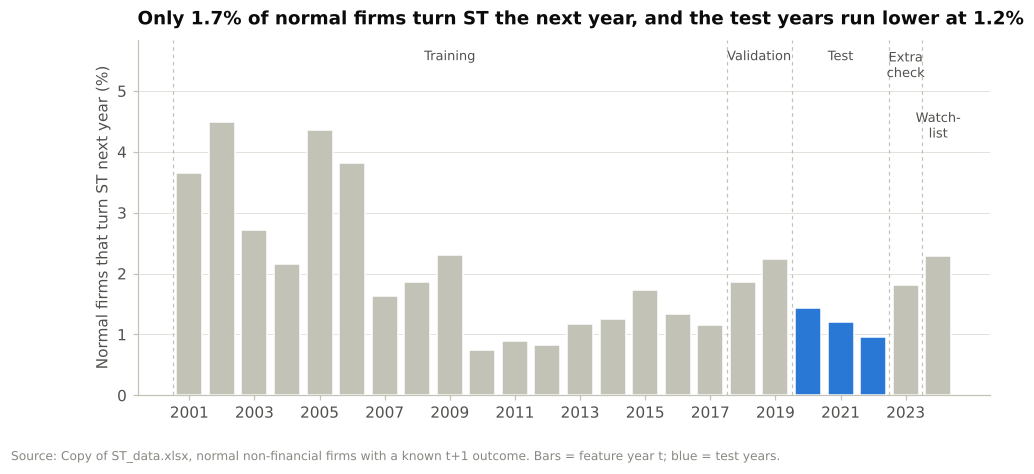

In [32]:
known = sample[sample["ST_next1"].notna()]
st_rate_by_year = known.groupby("year")["ST_next1"].mean() * 100         # % of normal firms that turn ST next year
overall = known.loc[known["split"].isin(["train", "validation", "test"]), "ST_next1"].mean()
test_rate = split_lookup.loc[("ST_next1", "test"), "ST rate %"] / 100

fig, ax = plt.subplots(figsize=(10, 4.2))
colors = [ACCENT if split_of(year) == "test" else CONTEXT for year in st_rate_by_year.index]
ax.bar(st_rate_by_year.index, st_rate_by_year, color=colors, width=0.8, edgecolor="white", linewidth=1)
# a dashed line and a name at the start of each part of the split
spans = [("Training", *TRAIN_YEARS, 0.97), ("Validation", *VALID_YEARS, 0.97), ("Test", *TEST_YEARS, 0.97),
         ("Extra\ncheck", OUT_OF_TIME_YEAR, OUT_OF_TIME_YEAR, 0.97), ("Watch-\nlist", LATEST_YEAR, LATEST_YEAR, 0.80)]
ymax = st_rate_by_year.max() * 1.3
for name, first, last, height in spans:
    ax.axvline(first - 0.5, color=AXIS, linewidth=0.8, linestyle=(0, (3, 3)))
    ax.text((first + last) / 2, ymax * height, name, ha="center", va="top", fontsize=8.5, color=INK2)
ax.set_ylim(0, ymax)
ax.set_xticks(range(2001, 2025, 2))
ax.set_ylabel("Normal firms that turn ST next year (%)")
ax.grid(axis="x", visible=False)
ax.set_title(f"Only {overall:.1%} of normal firms turn ST the next year, and the test years run "
             f"{'lower' if test_rate < overall else 'higher'} at {test_rate:.1%}")
save(fig, "fig02_time_split_st_rate", "Source: Copy of ST_data.xlsx, normal non-financial firms with a known t+1 outcome. Bars = feature year t; blue = test years.")

**What the result shows.** - The split matches the planned split exactly (six PASS lines).
- The t+1 model learns from 28,673 normal firm-years containing 515 future-ST cases, tunes on 6,803 (140 cases) and is tested once on 12,997 (154 cases). The t+2 model has 28,636 / 6,801 / 12,962 rows with 765 / 210 / 247 cases.
- The two targets really differ: 938 firm-years are normal in t+1 but ST in t+2, and 401 are ST in t+1 but recovered by t+2.
- The test years are the calmest: their ST rate is 1.18%, against 1.80% in training. Precision will look lower there for every model. That is a property of those years, not a fault.
- The extra checks are not small: 2023 → 2024 holds 5,082 firms (92 cases) and 2024 → 2025 holds 5,016 firms (115 cases), close to the 154 cases of the whole three-year test. That is why the 2025 forward check is worth running once the source of the 2025 status is confirmed.

## 7. Exploratory data analysis (EDA)

EDA asks: which firms turn ST, and what do they look like a year before? From here on we explore only the training years (2001-2017) for anything that could shape modelling choices. Choosing features by looking at the test years would make the test an unfair exam (tuning on the test set makes results look better than they are). Steps 7.1 and 7.7 show all years because they describe change over time.

### 7.1 How rare is turning ST?

In [33]:
labelled = sample[sample["ST_next1"].notna() & sample["split"].isin(["train", "validation", "test"])]
rate = labelled["ST_next1"].mean()
print(f"Normal firm-years with a known t+1 outcome, 2001-2022: {len(labelled):,}")
print(f"Turn ST next year: {int(labelled['ST_next1'].sum()):,} ({rate:.2%}), about 1 in {1 / rate:.0f}")
print(f"\nA 'model' that always answers 'stays normal' would be {1 - rate:.1%} accurate and catch 0 ST firms.")
print("That is why accuracy is the wrong yardstick here; Notebook 2 leads with recall, precision, F1 and PR-AUC.")

Normal firm-years with a known t+1 outcome, 2001-2022: 48,473
Turn ST next year: 809 (1.67%), about 1 in 60

A 'model' that always answers 'stays normal' would be 98.3% accurate and catch 0 ST firms.
That is why accuracy is the wrong yardstick here; Notebook 2 leads with recall, precision, F1 and PR-AUC.


### 7.2 Which groups turn ST more often?

We compare the ST-next-year rate across industries, listing boards, ownership, region and auditor. For yes/no features the standard test is the chi-square test of independence: a p-value below 0.05 says the feature and the outcome are related. With almost 29,000 rows even tiny differences come out significant, so we also report Cramér's V, which measures how strong the link is (about 0.1 weak, 0.3 moderate, 0.5 strong).

EDA rows (training years 2001-2017, known t+1 outcome): 28,673; ST next year: 515


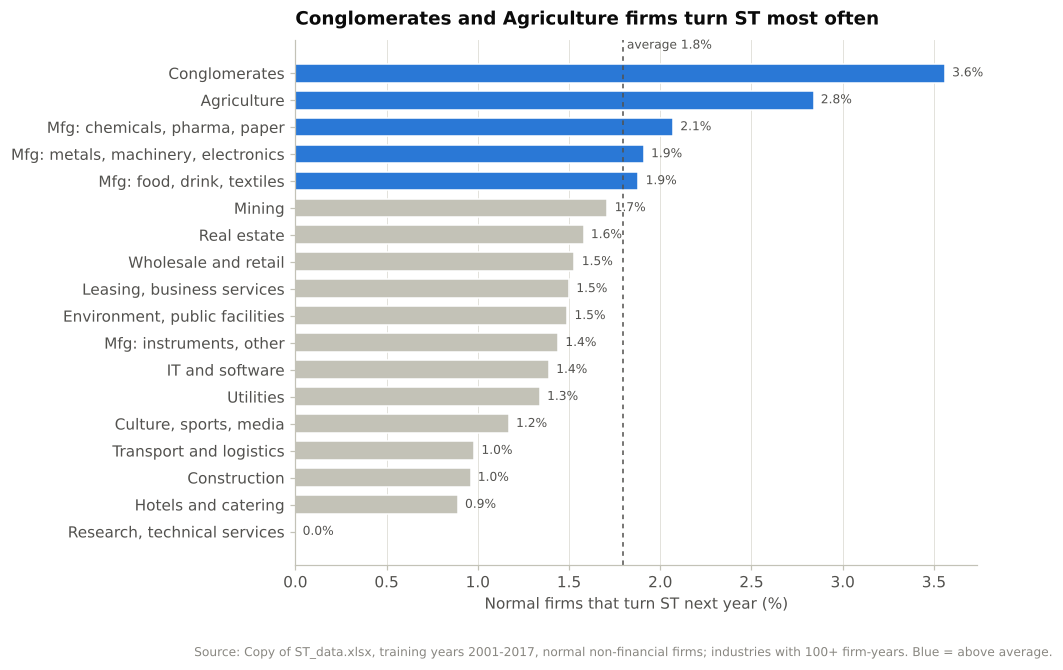


ST next year by listing_board:
               firm_years  ST_cases  ST rate %
listing_board                                 
B-share               178       7.0       3.93
Main board          25469     508.0       1.99
ChiNext              3026       0.0       0.00

ST next year by region:
         firm_years  ST_cases  ST rate %
region                                  
West           3789     120.0       3.17
Central        5578     124.0       2.22
East          19306     271.0       1.40

ST next year by SOE:
     firm_years  ST_cases  ST rate %
SOE                                 
1         14087     284.0       2.02
0         14586     231.0       1.58

ST next year by Big4:
      firm_years  ST_cases  ST rate %
Big4                                 
0.0        26876     495.0       1.84
1.0         1758      20.0       1.14


In [34]:
eda = sample[sample["split"].eq("train") & sample["ST_next1"].notna()].copy()
eda["Industry name"] = eda["Industry"].map(INDUSTRY_NAMES)
print(f"EDA rows (training years 2001-2017, known t+1 outcome): {len(eda):,}; ST next year: {int(eda['ST_next1'].sum())}")

def rate_table(col):
    t = eda.groupby(col)["ST_next1"].agg(firm_years="size", ST_cases="sum", rate="mean")
    t["ST rate %"] = (100 * t.pop("rate")).round(2)
    return t.sort_values("ST rate %", ascending=False)

ind = rate_table("Industry name")
avg = 100 * eda["ST_next1"].mean()
fig, ax = plt.subplots(figsize=(8, 6.2))
shown = ind[ind["firm_years"] >= 100][::-1]
ax.barh(shown.index, shown["ST rate %"], color=[ACCENT if v > avg else CONTEXT for v in shown["ST rate %"]],
        height=0.7, edgecolor="white", linewidth=1)
for y, v in enumerate(shown["ST rate %"]):
    ax.text(v + 0.04, y, f"{v:.1f}%", va="center", fontsize=8, color=INK2)
ax.axvline(avg, color=INK2, linewidth=1, linestyle=(0, (3, 3)))
ax.text(avg, len(shown) - 0.2, f" average {avg:.1f}%", fontsize=8, color=INK2, va="bottom")
ax.set_xlabel("Normal firms that turn ST next year (%)")
ax.grid(axis="y", visible=False)
top2 = ind[ind["firm_years"] >= 100].index[:2]
ax.set_title(f"{top2[0]} and {top2[1]} firms turn ST most often")
save(fig, "fig03_st_rate_by_industry", "Source: Copy of ST_data.xlsx, training years 2001-2017, normal non-financial firms; industries with 100+ firm-years. Blue = above average.")
for col in ["listing_board", "region", "SOE", "Big4"]:
    print(f"\nST next year by {col}:")
    print(rate_table(col).to_string())

In [35]:
print("Chi-square tests of independence with ST next year (training years):")
rows = []
for col in ["Loss", "Loss_2yr", "NegEquity", "NegCFO", "prior_ST", "SOE", "Big4", "Dual"]:
    sub = eda[[col, "ST_next1"]].dropna()
    table = pd.crosstab(sub[col], sub["ST_next1"])
    chi2, p, dof, expected = stats.chi2_contingency(table)
    cramers_v = np.sqrt(chi2 / (len(sub) * (min(table.shape) - 1)))      # 0 = no link, 1 = a perfect link
    rows.append({"feature": col, "chi-square": round(chi2, 1), "p-value": f"{p:.1e}", "Cramer's V": round(cramers_v, 3),
                 "% ST if 1": round(100 * sub.loc[sub[col] == 1, "ST_next1"].mean(), 2),
                 "% ST if 0": round(100 * sub.loc[sub[col] == 0, "ST_next1"].mean(), 2)})
chi_table = pd.DataFrame(rows).sort_values("Cramer's V", ascending=False)
chi_table

Chi-square tests of independence with ST next year (training years):


,feature,chi-square,p-value,Cramer's V,% ST if 1,% ST if 0
1,Loss_2yr,8635.5,0.0e+00,0.588,44.72,0.39
0,Loss,3858.9,0.0e+00,0.367,15.93,0.11
2,NegEquity,2557.8,0.0e+00,0.299,88.52,1.61
3,NegCFO,117.9,1.8e-27,0.064,3.40,1.34
4,prior_ST,73.4,1.1e-17,0.051,3.84,1.57
7,Dual,11.5,6.8e-04,0.020,1.27,1.94
5,SOE,7.4,6.7e-03,0.016,2.02,1.58
6,Big4,4.2,3.9e-02,0.012,1.14,1.84


**What the result shows.** - Industry matters, but less than finances do. Conglomerates (3.6%) and agriculture (2.8%) turn ST most often, against an average of 1.8%. Research and technical services had no cases.
- Western firms turn ST about twice as often as eastern ones (3.2% against 1.4%), and state-owned firms slightly more often than private ones (2.0% against 1.6%).
- ChiNext had no ST cases at all in the training years, which matters in 8.1.
- Two losses in a row has by far the strongest link among the yes/no flags (Cramér's V 0.59; 44.7% of these firms turn ST next year, against 0.4% of the rest), followed by a loss this year (0.37) and debts larger than assets (0.30).
- The governance flags (CEO duality, state ownership, Big Four auditor) pass the significance test only because the sample is large. Their Cramér's V is below 0.03, which means almost no practical link.

### 7.3 What future-ST firms look like a year before

The box plots compare typical values (the line is the median, the box holds the middle half of firms) for firms that turn ST the next year (blue) and firms that stay normal (grey). The display covers the 1st-99th percentile range so a few extreme values do not squash the boxes. Nothing is removed from the data.

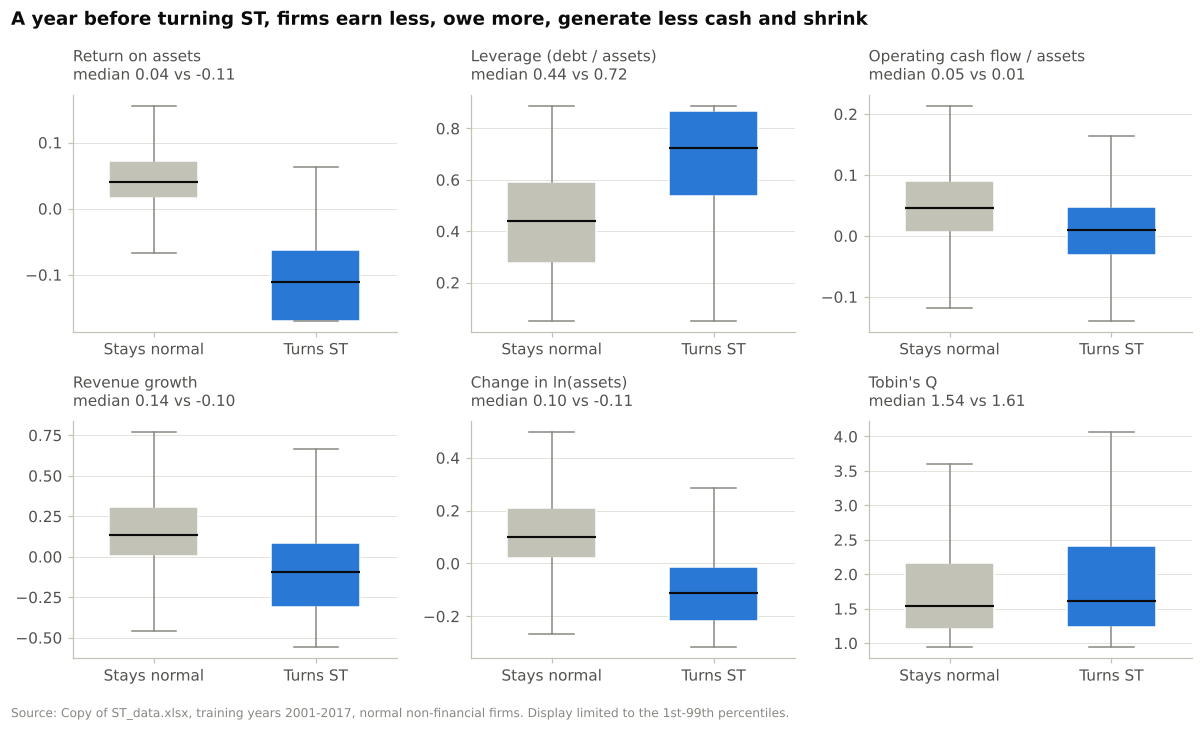

,median if stays normal,median if turns ST
Size,21.643,21.006
Employ_ln,7.535,7.382
Lev,0.439,0.722
ROA,0.041,-0.111
ROE,0.077,-0.309
ATO,0.573,0.367
AgC1_3,0.424,0.297
Cashflow,0.046,0.010
INV,0.121,0.109
FIXED,0.212,0.314


In [36]:
show_cols = {"ROA": "Return on assets", "Lev": "Leverage (debt / assets)", "Cashflow": "Operating cash flow / assets",
             "Growth": "Revenue growth", "Size_chg": "Change in ln(assets)", "TobinQ": "Tobin's Q"}
fig, axes = plt.subplots(2, 3, figsize=(11, 6.4))
for ax, (col, label) in zip(axes.ravel(), show_cols.items()):
    lo, hi = eda[col].quantile([0.01, 0.99])                     # show the 1st-99th percentile range only
    stays = eda.loc[eda["ST_next1"] == 0, col].dropna().clip(lo, hi)
    turns = eda.loc[eda["ST_next1"] == 1, col].dropna().clip(lo, hi)
    boxes = ax.boxplot([stays, turns], tick_labels=["Stays normal", "Turns ST"], showfliers=False, widths=0.55,
                       patch_artist=True, medianprops={"color": INK, "linewidth": 1.4}, boxprops={"edgecolor": "white"},
                       whiskerprops={"color": MUTED}, capprops={"color": MUTED})
    boxes["boxes"][0].set_facecolor(CONTEXT)
    boxes["boxes"][1].set_facecolor(ACCENT)
    ax.set_title(f"{label}\nmedian {stays.median():.2f} vs {turns.median():.2f}", fontsize=10, fontweight="normal", color=INK2)
    ax.grid(axis="x", visible=False)
fig.suptitle("A year before turning ST, firms earn less, owe more, generate less cash and shrink",
             x=0.01, ha="left", fontsize=12, fontweight="bold")
fig.tight_layout()
save(fig, "fig04_key_ratios_by_outcome", "Source: Copy of ST_data.xlsx, training years 2001-2017, normal non-financial firms. Display limited to the 1st-99th percentiles.")

NOT_CATEGORY = [c for c in FEATURES if FEATURES[c][0] != "Category"]     # every number and yes/no flag
medians = eda.groupby("ST_next1")[NOT_CATEGORY].median().T
medians.columns = ["median if stays normal", "median if turns ST"]
medians.round(3)

### 7.4 Which single signals separate the two groups best?

For each feature on its own we compute the ROC-AUC: the chance that a randomly picked future-ST firm looks riskier on that feature than a randomly picked normal firm. 0.5 means the feature is useless and 1.0 means it separates the groups perfectly. An AUC far below 0.5 is just as useful with the direction flipped (low values mean risk), so the chart shows the stronger reading of each feature and the colour says which way it points. This is a first screen, not a final verdict: Notebook 2 judges features together, inside a model.

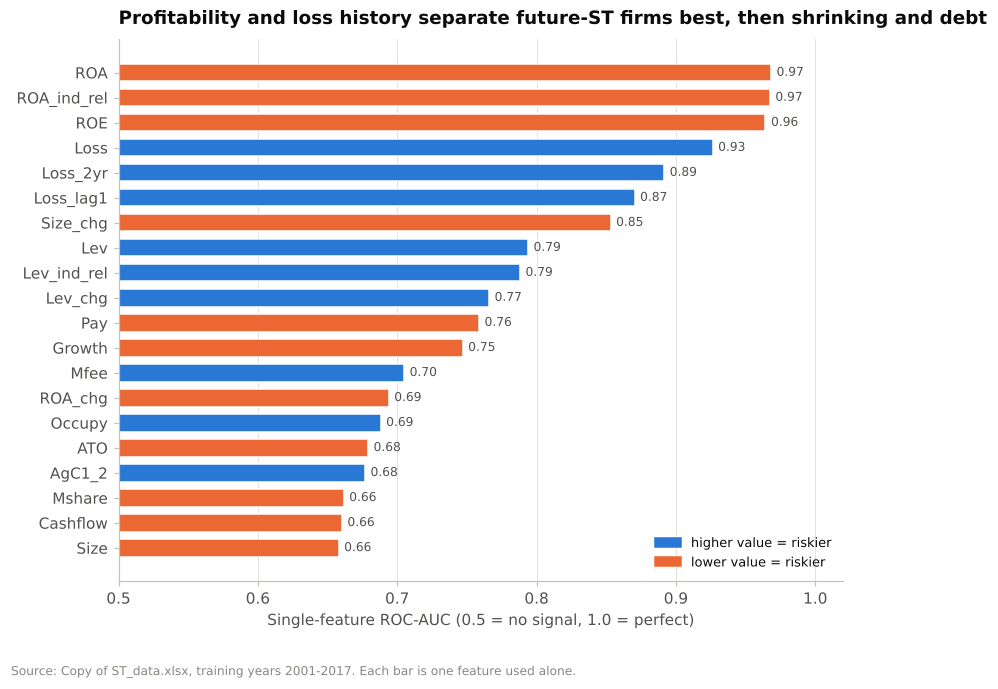

,feature,AUC,strength,direction seen,what we expected,blank %
0,ROA,0.032,0.968,lower = riskier,lower = riskier,0.0
1,ROA_ind_rel,0.033,0.967,lower = riskier,below peers = riskier,0.0
2,ROE,0.036,0.964,lower = riskier,lower = riskier,0.1
3,Loss,0.926,0.926,higher = riskier,1 = riskier,0.0
4,Loss_2yr,0.892,0.892,higher = riskier,1 = riskier,13.0
5,Loss_lag1,0.870,0.870,higher = riskier,1 = riskier,13.0
6,Size_chg,0.147,0.853,lower = riskier,shrinking = riskier,13.0
7,Lev,0.794,0.794,higher = riskier,higher = riskier,0.0
8,Lev_ind_rel,0.788,0.788,higher = riskier,above peers = riskier,0.0
9,Lev_chg,0.766,0.766,higher = riskier,rising = riskier,13.0


In [37]:
signal = []
for col in NOT_CATEGORY:
    sub = eda[[col, "ST_next1"]].dropna()
    auc = roc_auc_score(sub["ST_next1"], sub[col])
    signal.append({"feature": col, "AUC": auc, "strength": max(auc, 1 - auc),      # 0.5 = no signal, 1 = perfect
                   "direction seen": "higher = riskier" if auc >= 0.5 else "lower = riskier",
                   "what we expected": FEATURES[col][4], "blank %": round(100 * eda[col].isna().mean(), 1)})
signal = pd.DataFrame(signal).sort_values("strength", ascending=False).reset_index(drop=True)

top = signal.head(20)[::-1]                                      # the 20 strongest, strongest at the top
fig, ax = plt.subplots(figsize=(8.5, 6.4))
ax.barh(top["feature"], top["strength"] - 0.5, left=0.5, height=0.7, edgecolor="white", linewidth=1,
        color=[ACCENT if d == "higher = riskier" else SECOND for d in top["direction seen"]])
for y, v in enumerate(top["strength"]):
    ax.text(v + 0.004, y, f"{v:.2f}", va="center", fontsize=8, color=INK2)
ax.set_xlim(0.5, 1.02)
ax.set_xlabel("Single-feature ROC-AUC (0.5 = no signal, 1.0 = perfect)")
ax.grid(axis="y", visible=False)
ax.legend(handles=[Patch(color=ACCENT, label="higher value = riskier"), Patch(color=SECOND, label="lower value = riskier")],
          loc="lower right", fontsize=8.5)
ax.set_title("Profitability and loss history separate future-ST firms best, then shrinking and debt")
save(fig, "fig05_single_feature_signal", "Source: Copy of ST_data.xlsx, training years 2001-2017. Each bar is one feature used alone.")
signal.round(3)

**What the result shows.** - Profitability dominates. `ROA`, `ROA_ind_rel` and `ROE` each reach a strength near 0.97 on their own, followed by the loss flags (0.87-0.93), shrinking assets (`Size_chg`, 0.85) and debt (`Lev` and its change, 0.77-0.79).
- The strongest governance signals are executive pay (`Pay`, 0.76; lower pay goes with more risk), management costs (`Mfee`, 0.70) and funds taken by big shareholders (`Occupy`, 0.69).
- Board size, independent directors, CEO duality and the Big Four auditor sit at 0.51-0.56, almost no signal on their own.
- Every feature with a clear signal points the way the team expected. The one miss is `Cashflow_chg`, expected to matter but showing no signal (0.51). Of the features marked "unclear", future-ST firms hold more fixed assets (`FIXED`, 0.63) and fewer assets per employee (`Cap1`, 0.60).

Because ROA alone separates the groups this well, Notebook 2 adds a "rank firms by ROA" baseline that every model must beat.

### 7.5 Loss history: the rule the model has to beat

If two straight years of losses already flag most future-ST firms, a model must prove it adds something beyond that rule, otherwise a one-line rule would do. This step measures how far the rule goes and how many future-ST firms it misses. Notebook 2 turns it into the loss-rule baseline that every model is compared with.

                                    firm_years  ST_cases  ST rate %
Profit this year                         25623      29.0       0.11
Loss this year,\nprofit last year         1994      66.0       3.31
Loss this year\nand last year              843     377.0      44.72
Loss this year,\nlast year unknown         213      43.0      20.19


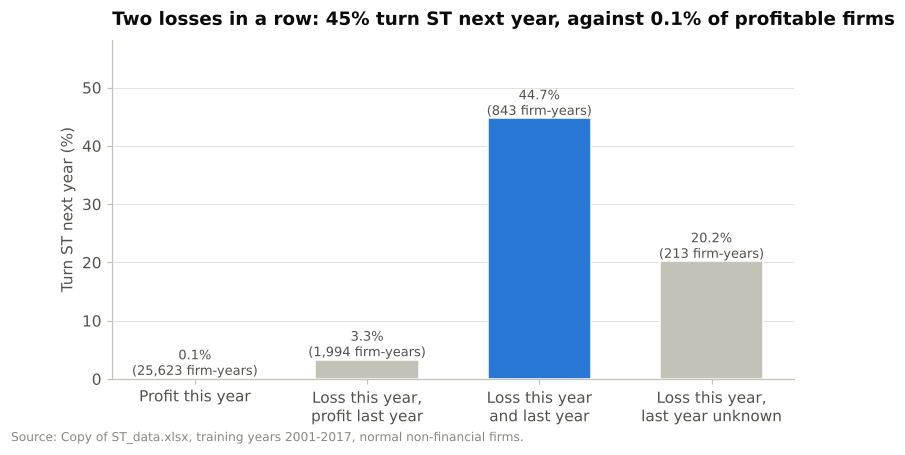


Of the 515 future-ST firms in the training years:
  73.2% had two losses in a row  -> the 'two losses' rule catches these
  94.4% had a loss this year      -> the 'any loss' rule catches these
  5.6% were profitable this year -> no loss rule can catch these; the model must

The two-loss rule flags 843 firm-years, of which 44.7% turn ST (its precision).


In [38]:
# Each firm-year's loss history ("last year unknown" = the firm's first year, or the year after a gap)
history = pd.Series("Loss this year,\nlast year unknown", index=eda.index)
history[eda["Loss"] == 0] = "Profit this year"
history[(eda["Loss"] == 1) & (eda["Loss_lag1"] == 0)] = "Loss this year,\nprofit last year"
history[(eda["Loss"] == 1) & (eda["Loss_lag1"] == 1)] = "Loss this year\nand last year"
ORDER = ["Profit this year", "Loss this year,\nprofit last year", "Loss this year\nand last year", "Loss this year,\nlast year unknown"]
hist = eda.groupby(history)["ST_next1"].agg(firm_years="size", ST_cases="sum", rate="mean")
hist["ST rate %"] = (100 * hist.pop("rate")).round(2)
hist = hist.reindex(ORDER)
print(hist.to_string())

fig, ax = plt.subplots(figsize=(8, 4))
bars = hist[hist["firm_years"] >= 100]
ax.bar(bars.index, bars["ST rate %"], color=[ACCENT if "and last" in i else CONTEXT for i in bars.index],
       width=0.6, edgecolor="white", linewidth=1)
for x, (v, n) in enumerate(zip(bars["ST rate %"], bars["firm_years"])):
    ax.text(x, v + 0.6, f"{v:.1f}%\n({n:,} firm-years)", ha="center", fontsize=8.5, color=INK2)
ax.set_ylabel("Turn ST next year (%)")
ax.set_ylim(0, bars["ST rate %"].max() * 1.3)
ax.grid(axis="x", visible=False)
two_losses = hist.loc["Loss this year\nand last year", "ST rate %"]
profit = hist.loc["Profit this year", "ST rate %"]
ax.set_title(f"Two losses in a row: {two_losses:.0f}% turn ST next year, against {profit:.1f}% of profitable firms")
save(fig, "fig06_loss_history", "Source: Copy of ST_data.xlsx, training years 2001-2017, normal non-financial firms.")

future = eda[eda["ST_next1"] == 1]                               # the firms that turn ST the next year
caught_2yr = (future["Loss_2yr"] == 1).mean()
caught_any = (future["Loss"] == 1).mean()
print(f"\nOf the {len(future)} future-ST firms in the training years:")
print(f"  {caught_2yr:.1%} had two losses in a row  -> the 'two losses' rule catches these")
print(f"  {caught_any:.1%} had a loss this year      -> the 'any loss' rule catches these")
print(f"  {1 - caught_any:.1%} were profitable this year -> no loss rule can catch these; the model must")
flagged = eda["Loss_2yr"] == 1
print(f"\nThe two-loss rule flags {flagged.sum():,} firm-years, of which {eda.loc[flagged, 'ST_next1'].mean():.1%} turn ST (its precision).")

**What the result shows.** Loss history explains a lot, but not everything. Two losses in a row is followed by ST in 44.7% of cases (377 of 843 firm-years), against 0.11% for profitable firms. Of the 515 future-ST firms in the training years, 73.2% had two losses in a row and 94.4% made a loss that year. Only 29 (5.6%) were profitable, and no loss rule can catch those.

So a simple "two losses" rule already catches about three cases in four, with a precision of 45%. A model earns its place only if it does better at two jobs: ranking the single-loss firms (3.3% of them turn ST) and finding the rare profitable ones. Notebook 2 measures exactly that.

### 7.6 Which features move together? (multicollinearity)

When two features carry almost the same information (for example `Top5` and `Top10`), a logistic regression cannot tell which one matters and its coefficients become unstable, even though predictions may stay fine. The usual check is a correlation matrix and the variance inflation factor, VIF: VIF 1 means no overlap, up to 5 is acceptable and above 10 is high. We use Spearman (rank) correlation because the ratios are skewed. Notebook 2 computes VIF on the exact inputs of the logistic model.

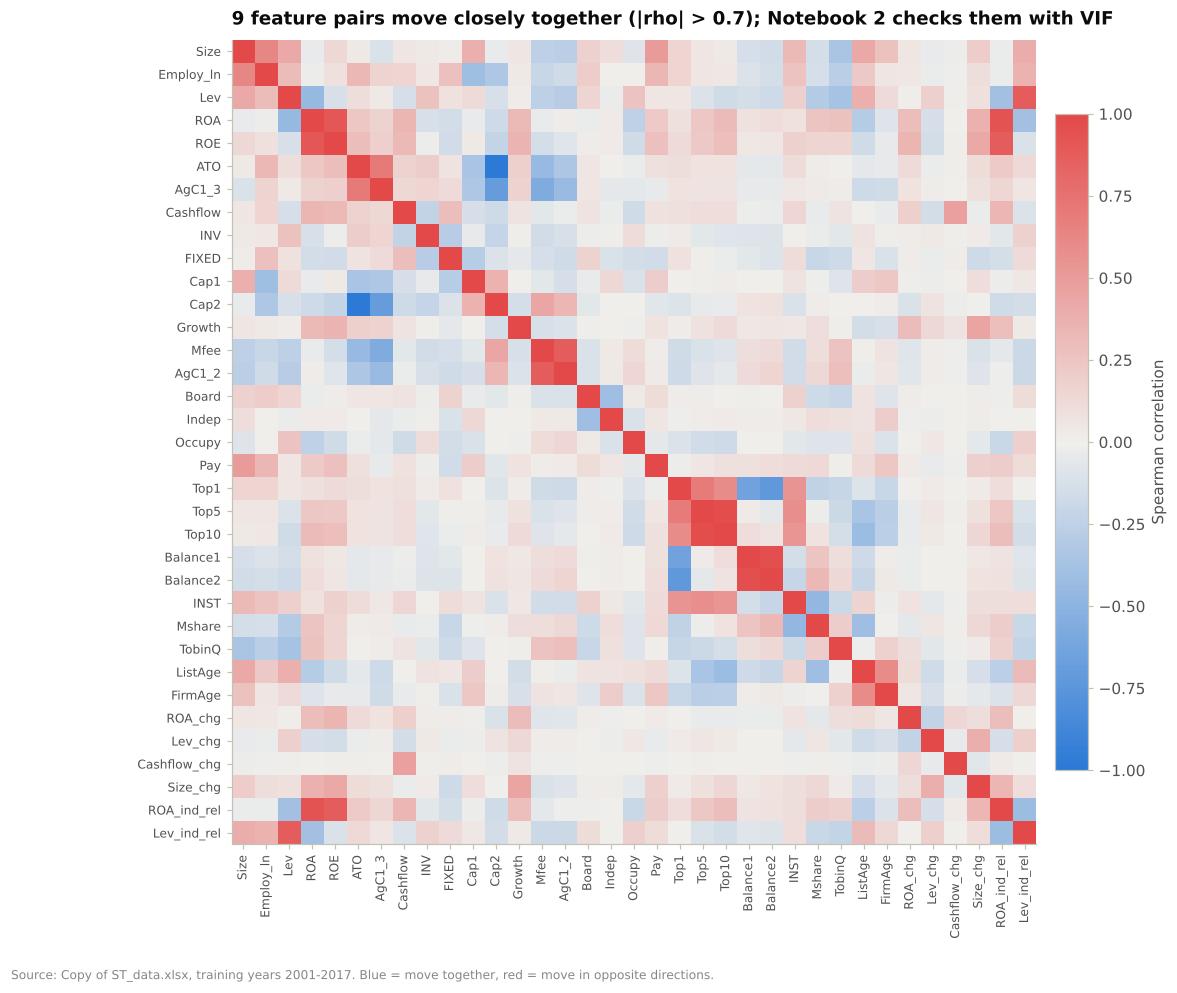

,feature A,feature B,rho
0,ATO,Cap2,-0.984
1,Top5,Top10,0.968
2,Balance1,Balance2,0.953
3,ROA,ROA_ind_rel,0.937
4,ROA,ROE,0.912
5,ROE,ROA_ind_rel,0.873
6,Lev,Lev_ind_rel,0.873
7,Mfee,AgC1_2,0.871
8,Top1,Balance2,-0.722


In [39]:
numeric_feats = [c for c in FEATURES if FEATURES[c][0] not in ("Category", "Flag")]
corr = eda[numeric_feats].corr(method="spearman")
fig, ax = plt.subplots(figsize=(11, 9.5))
im = ax.imshow(corr, cmap=DIVERGING, vmin=-1, vmax=1)
ax.set_xticks(range(len(numeric_feats)), numeric_feats, rotation=90, fontsize=8)
ax.set_yticks(range(len(numeric_feats)), numeric_feats, fontsize=8)
ax.grid(False)
cbar = fig.colorbar(im, ax=ax, fraction=0.035, pad=0.02)
cbar.set_label("Spearman correlation", color=INK2)

# Every pair of features once, then the pairs that move closely together
pairs = []
for i, a in enumerate(numeric_feats):
    for b in numeric_feats[i + 1:]:
        pairs.append({"feature A": a, "feature B": b, "rho": corr.loc[a, b]})
pairs = pd.DataFrame(pairs)
strong = pairs[pairs["rho"].abs() > 0.7].sort_values("rho", key=abs, ascending=False).reset_index(drop=True)
ax.set_title(f"{len(strong)} feature pairs move closely together (|rho| > 0.7); Notebook 2 checks them with VIF")
save(fig, "fig07_correlation_heatmap", "Source: Copy of ST_data.xlsx, training years 2001-2017. Blue = move together, red = move in opposite directions.")
strong.round(3)

**What the result shows.** Nine pairs move closely together (|rho| > 0.7), and most are built that way: `ATO` and `Cap2` are near mirror images (-0.98; sales per unit of assets against assets per unit of sales), `Top5` and `Top10` overlap (0.97), as do `Balance1` and `Balance2` (0.95), `ROA` with `ROA_ind_rel` (0.94) and `ROE` (0.91), `Lev` with `Lev_ind_rel` (0.87), and `Mfee` with `AgC1_2` (0.87). This does not hurt tree models, but it makes logistic-regression coefficients unstable. Notebook 2 therefore computes VIF on the logistic inputs and measures importance by indicator family, scrambling a whole family at once, which side-steps the overlap.

### 7.7 The market changes over time (why we split by year)

If the world stood still, a random split would be fine. It does not. The share of loss-making firms and typical profitability move with the economy (the 2008 crisis, the 2015 market crash, COVID in 2020). A model trained on one era is tested on another, which is what happens in real use. This is also why Notebook 2 checks performance year by year and why the deployment plan includes drift monitoring.

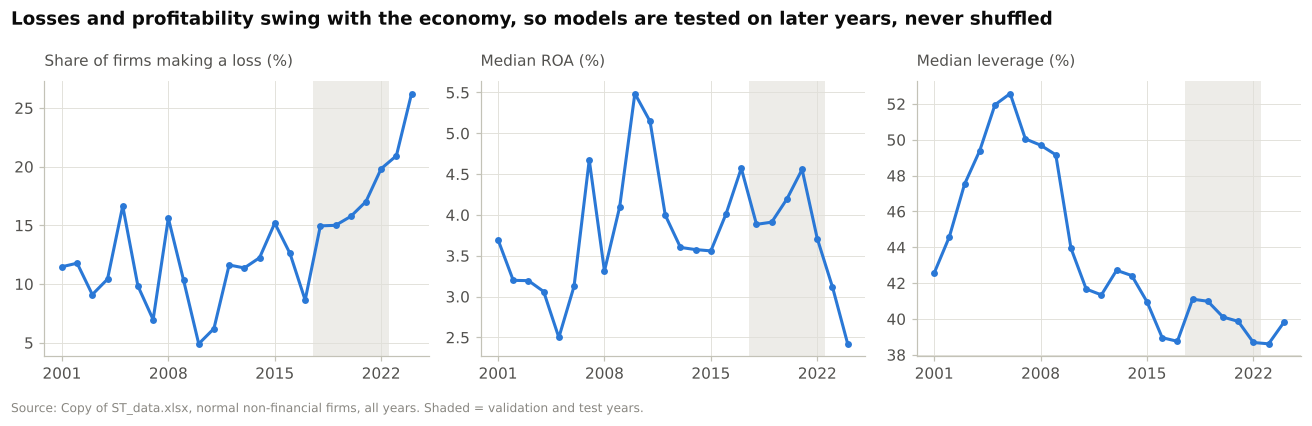

year,2001,2002,2003,2004,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
loss_share,11.47,11.78,9.10,10.42,16.65,9.83,6.97,15.61,10.34,4.90,6.20,11.62,11.37,12.24,15.19,12.61,8.63,14.95,15.00,15.76,17.03,19.83,20.93,26.23
median_roa,3.70,3.20,3.20,3.06,2.50,3.13,4.67,3.31,4.10,5.49,5.15,4.00,3.60,3.58,3.56,4.01,4.57,3.88,3.91,4.19,4.56,3.71,3.12,2.42
median_lev,42.56,44.59,47.52,49.40,51.95,52.58,50.05,49.70,49.16,43.95,41.67,41.34,42.72,42.42,40.96,38.96,38.75,41.10,40.99,40.11,39.87,38.69,38.61,39.81


In [40]:
yearly = sample.groupby("year").agg(loss_share=("Loss", "mean"), median_roa=("ROA", "median"),
                                    median_lev=("Lev", "median"))
titles = {"loss_share": "Share of firms making a loss (%)", "median_roa": "Median ROA (%)",
          "median_lev": "Median leverage (%)"}
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6), sharex=True)
for ax, (col, title) in zip(axes, titles.items()):
    ax.plot(yearly.index, 100 * yearly[col], color=ACCENT, linewidth=2, marker="o", markersize=3.5)
    for first, last in [VALID_YEARS, TEST_YEARS]:                # shade the validation and test years
        ax.axvspan(first - 0.5, last + 0.5, color=GRID, alpha=0.6, linewidth=0)
    ax.set_title(title, fontsize=10, fontweight="normal", color=INK2)
    ax.set_xticks([2001, 2008, 2015, 2022])
fig.suptitle("Losses and profitability swing with the economy, so models are tested on later years, never shuffled",
             x=0.01, ha="left", fontsize=12, fontweight="bold")
fig.tight_layout()
save(fig, "fig08_drift_over_time", "Source: Copy of ST_data.xlsx, normal non-financial firms, all years. Shaded = validation and test years.")
(yearly * 100).round(2).T

### 7.8 The top five indicator families from EDA (Objective 2, first half)

Objective 2 asks for the top five financial and governance indicators. EDA gives the first half: how strongly each indicator family separates future-ST firms from the rest on its own, in the training years. A family's strength is the AUC strength of its strongest member from 7.4. The two category features (industry group and region) are scored by the training-year ST rate of their group, which is slightly flattering for the 22 industry groups. Notebook 2 gives the second half: how much the model's accuracy drops when a whole family is scrambled (grouped permutation importance), which also accounts for overlap between families. The final top five combines both rankings. The table is saved as `outputs/end_to_end/eda_indicator_ranking.csv`.

PASS  | Indicator families ranked: 17 (expected 17)


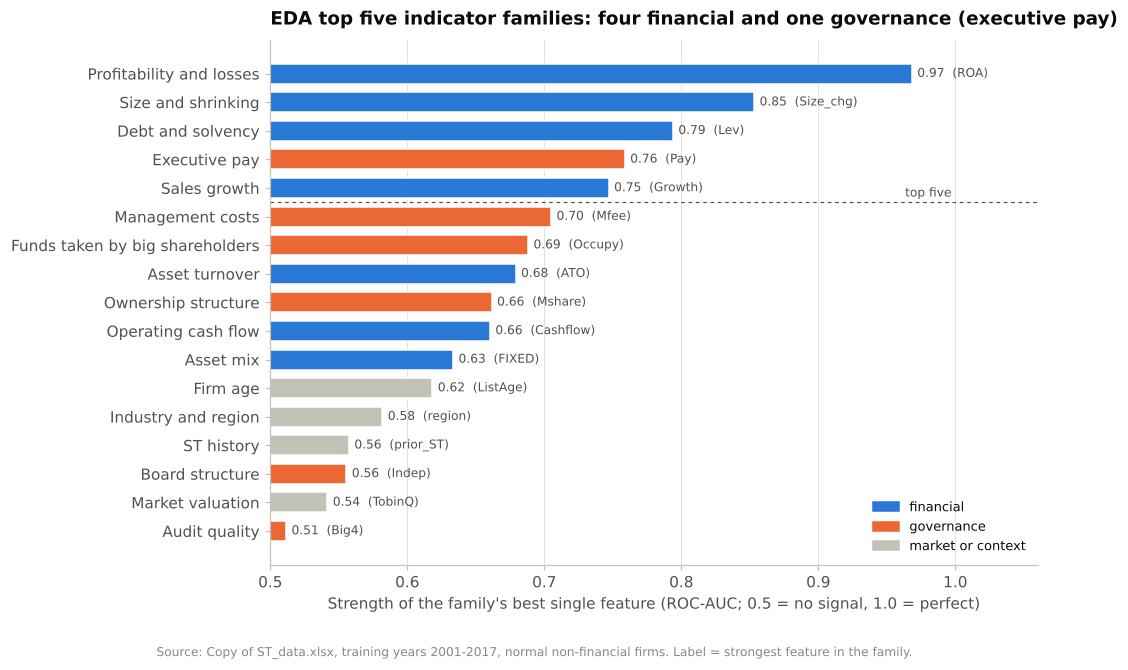

,EDA rank,family,type,strongest_feature,EDA_strength,direction,members
0,1,Profitability and losses,Financial,ROA,0.968,lower = riskier,"ROA, ROA_ind_rel, ROE, Loss, Loss_2yr, Loss_lag1, ROA_chg"
1,2,Size and shrinking,Financial,Size_chg,0.853,lower = riskier,"Size_chg, Size, Employ_ln"
2,3,Debt and solvency,Financial,Lev,0.794,higher = riskier,"Lev, Lev_ind_rel, Lev_chg, NegEquity"
3,4,Executive pay,Governance,Pay,0.759,lower = riskier,Pay
4,5,Sales growth,Financial,Growth,0.747,lower = riskier,Growth
5,6,Management costs,Governance,Mfee,0.705,higher = riskier,"Mfee, AgC1_2"
6,7,Funds taken by big shareholders,Governance,Occupy,0.688,higher = riskier,Occupy
7,8,Asset turnover,Financial,ATO,0.679,lower = riskier,"ATO, AgC1_3"
8,9,Ownership structure,Governance,Mshare,0.662,lower = riskier,"Mshare, Top10, Top5, Top1, INST, SOE, Balance1, Balance2"
9,10,Operating cash flow,Financial,Cashflow,0.660,lower = riskier,"Cashflow, NegCFO, Cashflow_chg"


In [41]:
# Each member's strength: the AUC from 7.4, and for the two category features the AUC of their group's ST rate
extra = []
for col in ["Industry", "region"]:
    group_rate = eda.groupby(col)["ST_next1"].mean()
    extra.append({"feature": col, "strength": roc_auc_score(eda["ST_next1"], eda[col].map(group_rate)),
                  "direction seen": "differs by group"})
member_signal = pd.concat([signal[["feature", "strength", "direction seen"]], pd.DataFrame(extra)], ignore_index=True)
member_signal["family"] = member_signal["feature"].map(FEATURE_FAMILY)
member_signal = member_signal.dropna(subset=["family"]).sort_values("strength", ascending=False)

# A family is as strong as its strongest member (the list is sorted, so the first member is the strongest)
eda_ranking = (member_signal.groupby("family", sort=False)
               .agg(strongest_feature=("feature", "first"), EDA_strength=("strength", "first"),
                    direction=("direction seen", "first"), members=("feature", ", ".join))
               .reset_index())
eda_ranking.insert(1, "type", eda_ranking["family"].map(FAMILY_TYPE))
eda_ranking.insert(0, "EDA rank", range(1, len(eda_ranking) + 1))
expect("Indicator families ranked", len(eda_ranking), len(FAMILIES))
eda_ranking.to_csv(OUT_DIR / "eda_indicator_ranking.csv", index=False)

TYPE_COLOR = {"Financial": ACCENT, "Governance": SECOND, "Market": CONTEXT, "Context": CONTEXT}
shown = eda_ranking[::-1]                                        # strongest at the top
fig, ax = plt.subplots(figsize=(9, 6.2))
ax.barh(shown["family"], shown["EDA_strength"] - 0.5, left=0.5, height=0.7, edgecolor="white", linewidth=1,
        color=[TYPE_COLOR[t] for t in shown["type"]])
for y, (v, f) in enumerate(zip(shown["EDA_strength"], shown["strongest_feature"])):
    ax.text(v + 0.004, y, f"{v:.2f}  ({f})", va="center", fontsize=8, color=INK2)
ax.axhline(len(shown) - 5.5, color=INK2, linewidth=0.8, linestyle=(0, (3, 3)))
ax.text(1.0, len(shown) - 5.4, "top five ", ha="right", va="bottom", fontsize=8, color=INK2)
ax.set_xlim(0.5, 1.06)
ax.set_xlabel("Strength of the family's best single feature (ROC-AUC; 0.5 = no signal, 1.0 = perfect)")
ax.grid(axis="y", visible=False)
ax.legend(handles=[Patch(color=ACCENT, label="financial"), Patch(color=SECOND, label="governance"),
                   Patch(color=CONTEXT, label="market or context")], loc="lower right", fontsize=8.5)

# The title names how many of the top five are financial and governance
top5 = eda_ranking.head(5)
n_fin = (top5["type"] == "Financial").sum()
n_gov = (top5["type"] == "Governance").sum()
gov_names = ", ".join(top5.loc[top5["type"] == "Governance", "family"].str.lower())
words = ["no", "one", "two", "three", "four", "five"]
ax.set_title(f"EDA top five indicator families: {words[n_fin]} financial and {words[n_gov]} governance"
             + (f" ({gov_names})" if n_gov else ""))
save(fig, "fig09_indicator_families_eda", "Source: Copy of ST_data.xlsx, training years 2001-2017, normal non-financial firms. Label = strongest feature in the family.")
eda_ranking.round(3)

**What the result shows.** The EDA top five indicator families are:
1. Profitability and losses (best single signal `ROA`, 0.97)
2. Size and shrinking (`Size_chg`, 0.85)
3. Debt and solvency (`Lev`, 0.79)
4. Executive pay (`Pay`, 0.76), the strongest governance signal
5. Sales growth (`Growth`, 0.75)

Two governance families follow closely: management costs (0.70) and funds taken by big shareholders (0.69). Board structure (0.56) and audit quality (0.51) are near the bottom.

In plain words: a year before ST, the typical firm is losing money, shrinking, carrying more debt, paying its managers less and selling less. These are associations, not causes. One caution: executive pay may partly stand in for firm size and profitability, because smaller and weaker firms pay less. Notebook 2's grouped importance judges each family alongside all the others and decides whether pay stays in the final top five.

## 8. Your EDA: add new analysis here

Every table below is already built by the steps above:

| Name | What it is | Use it for |
|---|---|---|
| `raw` | the file as loaded, 62,669 firm-years | checking a value against the source |
| `panel` | the cleaned full history with the 14 new features (all firms, ST ones included) | anything that needs a firm's history |
| `sample` | normal, non-financial firm-years with `split` (train, validation, test, out_of_time, latest) | the population the model ranks |
| `eda` | `sample` limited to the training years 2001-2017 with a known t+1 outcome | **new EDA goes here** |
| `FEATURES`, `FAMILIES` | the feature dictionary (5.7) and the 17 indicator families | names, meanings, groups |
| `signal`, `eda_ranking` | the single-signal strengths (7.4) and the family ranking (7.8) | comparing a new idea with the old ones |

Helpers: `expect()` for a self-check, `log_issue()` for the quality log, and `save(fig, "fig10_name", "Source: ...")` for charts in the house style (grey for context, `ACCENT` blue for what matters, a title that states the finding).

The two examples below show the usual patterns: a rate by group, and the strength of a new candidate signal. Copy a cell, change the column, and add one line under it saying what it shows.

             firm_years  ST_cases  ST rate %
Lev                                         
lowest 20%         5735        21       0.37
2nd                5734        35       0.61
3rd                5735        55       0.96
4th                5734        76       1.33
highest 20%        5735       328       5.72


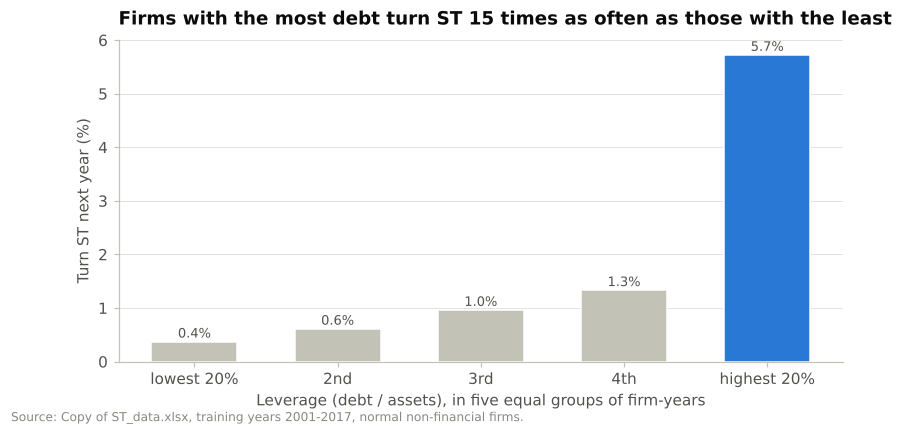

In [42]:
# Example 1: how the chance of turning ST next year rises with leverage (training years only)
col, label = "Lev", "Leverage (debt / assets)"
bins = pd.qcut(eda[col], 5, labels=["lowest 20%", "2nd", "3rd", "4th", "highest 20%"])
by_bin = eda.groupby(bins, observed=True)["ST_next1"].agg(firm_years="size", ST_cases="sum", rate="mean")
by_bin["ST_cases"] = by_bin["ST_cases"].astype(int)
by_bin["ST rate %"] = (100 * by_bin.pop("rate")).round(2)
print(by_bin.to_string())

fig, ax = plt.subplots(figsize=(8.5, 3.8))
top = by_bin["ST rate %"].idxmax()
ax.bar(by_bin.index.astype(str), by_bin["ST rate %"], width=0.6, edgecolor="white",
       color=[ACCENT if i == top else CONTEXT for i in by_bin.index])
for x, v in enumerate(by_bin["ST rate %"]):
    ax.text(x, v + 0.08, f"{v:.1f}%", ha="center", fontsize=8.5, color=INK2)
ax.set_xlabel(f"{label}, in five equal groups of firm-years")
ax.set_ylabel("Turn ST next year (%)")
ax.grid(axis="x", visible=False)
ratio = by_bin["ST rate %"].iloc[-1] / by_bin["ST rate %"].iloc[0]
ax.set_title(f"Firms with the most debt turn ST {ratio:.0f} times as often as those with the least")
save(fig, "fig10_example_rate_by_leverage", "Source: Copy of ST_data.xlsx, training years 2001-2017, normal non-financial firms.")

In [43]:
# Example 2: is a new candidate signal stronger than the ones we have? (training years only)
def signal_strength(values):
    """ROC-AUC folded so 0.5 = no signal and 1.0 = perfect, whichever direction the signal runs (as in 7.4)."""
    ok = values.notna() & eda["ST_next1"].notna()
    auc = roc_auc_score(eda.loc[ok, "ST_next1"], values[ok])
    direction = "higher = riskier" if auc >= 0.5 else "lower = riskier"
    blank_pct = round(100 * (1 - ok.mean()), 1)
    return max(auc, 1 - auc), direction, blank_pct

# A candidate: accruals = profit not backed by cash (ROA minus operating cash flow / assets)
candidate = eda["ROA"] - eda["Cashflow"]
strength, direction, blank_pct = signal_strength(candidate)
strength_of = signal.set_index("feature")["strength"]           # the single-signal strengths from 7.4
print(f"Candidate 'ROA minus cash flow': strength {strength:.3f} ({direction}), blank {blank_pct}%")
print(f"For comparison: ROA {strength_of['ROA']:.3f}, Cashflow {strength_of['Cashflow']:.3f}")
print("A candidate is worth adding to Notebook 1 (5.7) only if it is strong AND not just a copy of an existing feature:")
print(f"rank correlation with ROA: {candidate.corr(eda['ROA'], method='spearman'):.2f}")

Candidate 'ROA minus cash flow': strength 0.846 (lower = riskier), blank 0.0%
For comparison: ROA 0.968, Cashflow 0.660
A candidate is worth adding to Notebook 1 (5.7) only if it is strong AND not just a copy of an existing feature:
rank correlation with ROA: 0.35


**What the examples show.** - **Example 1 (debt).** The chance of turning ST next year climbs with leverage: 0.37% in the least indebted fifth of firm-years, then 0.61%, 0.96% and 1.33%, and 5.72% in the most indebted fifth, about 15 times the lowest. Most of the rise sits in the top fifth, so the risk is concentrated among the most indebted firms. This fits 7.8, where debt and solvency is one of the EDA top five families.
- **Example 2 (a new candidate signal).** "ROA minus cash flow" (profit that is not backed by operating cash) has a strength of 0.846, with lower values riskier. Its rank correlation with ROA is only 0.35, so it is not a copy of ROA, but it is weaker than ROA alone (0.968). A single-signal strength cannot say whether it adds anything on top of ROA. Only a model can (Notebook 2, permutation importance). Treat it as a worked example, not a recommendation.

## 9. Summary and saved files

**What this notebook did.** It read the 62,669 firm-years straight from `Copy of ST_data.xlsx` and ran the same audit, cleaning, feature building, sample and EDA steps as Notebook 1. All 38 self-checks pass, and each gives exactly the same number as in Notebook 1, which read the data from MySQL. The EDA ranking of the 17 indicator families is identical too.

**What the EDA found** (the same as Notebook 1). Turning ST is rare (1.7% of normal firms a year) and follows losses: two losses in a row is followed by ST in 45% of cases, and 94% of future-ST firms made a loss the year before. Profitability is the strongest single signal (AUC about 0.97), then shrinking assets, debt, executive pay and sales growth. These are the EDA top five for Objective 2. Board and auditor features carry almost no signal on their own. One firm in six has no governance data at all for 2024, and those firms turn ST more often (3.3). The market drifts over time (the share of loss-making firms rose from 8.6% in 2017 to 26.2% in 2024), which is why every model is judged on later years only.

**From the worked examples in section 8.** Risk climbs steeply in the most indebted fifth of firm-years (5.7% turn ST next year, against 0.4% in the least indebted fifth). A candidate signal, profit not backed by cash, is weaker than ROA on its own (0.85 against 0.97).

**Saved in `outputs/end_to_end/`:** the ten charts (fig01 to fig10), `eda_indicator_ranking.csv`, `feature_dictionary.csv`, `data_quality_log.csv` (31 findings) and `eda_checks.csv` (38 checks).

**To take a finding into the models,** add or change the feature in Notebook 1 (5.7), run Notebook 1 again so `model_ready.csv.gz` is refreshed, then run Notebook 2. Nothing saved here feeds the models.

In [44]:
checks = pd.DataFrame(CHECKS)
feature_dictionary.to_csv(OUT_DIR / "feature_dictionary.csv")
pd.DataFrame(QUALITY_LOG).to_csv(OUT_DIR / "data_quality_log.csv", index=False)
checks.to_csv(OUT_DIR / "eda_checks.csv", index=False)
for name in ["eda_indicator_ranking.csv", "feature_dictionary.csv", "data_quality_log.csv", "eda_checks.csv"]:
    print(f"saved outputs/end_to_end/{name:<26} {(OUT_DIR / name).stat().st_size / 1024:>6,.0f} KB")
figures = sorted(p.stem for p in FIG_DIR.glob("*.png"))
print(f"saved outputs/end_to_end/figures/: {', '.join(figures)}")
n_pass, n_check = (checks["result"] == "PASS").sum(), (checks["result"] == "CHECK").sum()
print(f"\nChecks in this notebook: {len(checks)}, PASS: {n_pass}, CHECK: {n_check}")

saved outputs/end_to_end/eda_indicator_ranking.csv       2 KB
saved outputs/end_to_end/feature_dictionary.csv          6 KB
saved outputs/end_to_end/data_quality_log.csv            5 KB
saved outputs/end_to_end/eda_checks.csv                  2 KB
saved outputs/end_to_end/figures/: fig01_missing_values, fig02_time_split_st_rate, fig03_st_rate_by_industry, fig04_key_ratios_by_outcome, fig05_single_feature_signal, fig06_loss_history, fig07_correlation_heatmap, fig08_drift_over_time, fig09_indicator_families_eda, fig10_example_rate_by_leverage

Checks in this notebook: 38, PASS: 38, CHECK: 0


In [45]:
if SAVE_CLEANED_XLSX:
    # Save the cleaned full history (all 62,669 firm-years) and the list of changes as one Excel file
    with pd.ExcelWriter(OUT_DIR / "cleaned_data.xlsx") as writer:
        panel.to_excel(writer, sheet_name="cleaned_data", index=False)                         # one row per firm-year
        pd.DataFrame(QUALITY_LOG).to_excel(writer, sheet_name="changes_made", index=False)     # every problem found and what was done
        feature_dictionary.to_excel(writer, sheet_name="column_meanings")                      # what each column means
    size_mb = (OUT_DIR / "cleaned_data.xlsx").stat().st_size / 1024 ** 2
    print(f"saved outputs/end_to_end/cleaned_data.xlsx ({size_mb:.1f} MB): {len(panel):,} rows x {panel.shape[1]} columns")

saved outputs/end_to_end/cleaned_data.xlsx (23.1 MB): 62,669 rows x 58 columns


# Part 2 · Modelling and evaluation (Notebook 2 v2)

Part 2 keeps Notebook 2's section numbers (2 to 17), so its text and cross-references stay correct. "Notebook 1b, step x" in Part 2 means Part 1, step x of this notebook.

## 2. Settings, helpers and the bridge from the EDA

### 2.1 Modelling settings

**What and why.** The modelling choices, each explained in the section that uses it. The data choices (sample, split, caps) were made in Part 1 and are not repeated.

In [46]:
MODEL_DIR = V2_DIR / "models" / "end_to_end"
MODEL_DIR.mkdir(parents=True, exist_ok=True)
EDA_DIR = OUT_DIR                            # Part 1 saved its EDA ranking here
V1_DIR = PROJECT_DIR / "outputs"            # v1 outputs, used only to prove the bridge gives the same table
EDA_CHECKS = list(CHECKS)                   # keep Part 1's checks; Part 2's helpers start a new list
DATA_SOURCE = "excel (Part 1 of this notebook)"

RANDOM_STATE = 42                           # same seed everywhere, so every run gives the same numbers
N_JOBS = int(os.environ.get("ST_N_JOBS", os.cpu_count() or 2))
MODEL_VERSION = "v2.0e"                      # e = trained straight from the Excel file

# The team's business targets
WATCHLIST_SHARE = 0.10        # Objective 3: review about 10% of firms each year (the High band)
MEDIUM_SHARE = 0.10           # the next 10% form the Medium band
TARGET_RECALL = 0.70          # Objective 1: catch at least 70% of next-year ST cases inside the top 10%
TOP_N_INDICATORS = 5          # Objective 2

# Validation design (section 6)
CV_FOLDS = [(2010, 2011), (2012, 2013), (2014, 2015), (2016, 2017)]   # time-ordered folds inside 2001-2017
T2_PURGE_YEARS = 1            # 6.3: the t+2 model never learns an outcome that was unknown at scoring time
TIE_MARGIN = 0.02             # 9.1: validation Recall@Top10% gaps below 2 points (about 3 of 140 cases) count as a tie

# Search size for step 8 (more iterations = slower, sometimes slightly better)
N_ITER = {"Logistic regression": 10, "Decision tree": 15, "Random forest": 8, "XGBoost": 15,
          "Neural network (MLP)": 4}
BOOTSTRAP_REPS = 1000         # resamples for the 95% intervals
USE_2025_STATUS = False       # 16: write the provisional 2025 status into the MySQL scores file?

FAST = os.environ.get("ST_FAST", "0") == "1"   # quick trial run with tiny searches
if FAST:
    N_ITER = {k: 2 for k in N_ITER}
    BOOTSTRAP_REPS = 100
print("Project folder:", PROJECT_DIR.resolve().name, "| cores used:", N_JOBS, "| fast trial run:", FAST)

Project folder: pal-breakdown | cores used: 2 | fast trial run: False


### 1.2 Libraries, helper functions and chart style

**What and why.** The helpers below are used all through the notebook:
- `expect()` prints `PASS` or `CHECK` against the number this guide expects, as in Notebook 1.
- `top_share_flags()` marks the firms in the riskiest 10% (or any share) **of their own year**. The watch-list is drawn up year by year, so the ranking is always within a year, never across years.
- `recall_at_top()` is the Objective 1 measure, explained in section 3.
- `report()` computes every yardstick for one set of scores at once.

In [47]:
import json, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from scipy import stats
from scipy.stats import loguniform, randint, uniform
import joblib, sklearn, xgboost, imblearn, statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, MinMaxScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import RandomizedSearchCV, train_test_split
from sklearn.base import clone
from sklearn.metrics import (average_precision_score, roc_auc_score, recall_score, precision_score, f1_score,
                             balanced_accuracy_score, brier_score_loss, confusion_matrix, precision_recall_curve,
                             roc_curve, accuracy_score)
from xgboost import XGBClassifier
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import RandomOverSampler, SMOTE
from imblearn.under_sampling import RandomUnderSampler

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 70)

CHECKS = []   # every expect() result (saved in 16)

def expect(label, actual, expected, tol=0.0):
    """PASS if a result equals the number this guide expects (within tol), otherwise CHECK."""
    ok = abs(float(actual) - float(expected)) <= tol
    CHECKS.append({"notebook": 2, "check": label, "actual": float(actual),
                   "expected": float(expected), "result": "PASS" if ok else "CHECK"})
    whole = float(expected).is_integer() and tol == 0
    show = (lambda v: f"{int(round(float(v))):,}") if whole else (lambda v: f"{float(v):.3f}")
    print(f"{'PASS ' if ok else 'CHECK'} | {label}: {show(actual)} (expected {show(expected)})")

def expect_text(label, actual, expected):
    ok = str(actual) == str(expected)
    CHECKS.append({"notebook": 2, "check": label, "actual": str(actual), "expected": str(expected),
                   "result": "PASS" if ok else "CHECK"})
    print(f"{'PASS ' if ok else 'CHECK'} | {label}: {actual} (expected {expected})")

def year_rank(df, score):
    """1 = riskiest firm of its year. Ties are broken by stock code so the order is repeatable."""
    tmp = pd.DataFrame({"year": df["year"].to_numpy(), "stkcd": df["stkcd"].to_numpy(),
                        "s": np.asarray(score, dtype=float)})
    order = tmp.sort_values(["year", "s", "stkcd"], ascending=[True, False, True])
    return (order.groupby("year").cumcount() + 1).sort_index().to_numpy()

def top_share_flags(df, score, share=WATCHLIST_SHARE):
    """1 for the firms in the riskiest `share` of their own year (rounded up), else 0."""
    rank = year_rank(df, score)
    n_year = df.groupby("year")["year"].transform("size").to_numpy()
    return (rank <= np.ceil(share * n_year)).astype(int)

def recall_at_top(df, score, target, share=WATCHLIST_SHARE):
    """Objective 1: share of all ST cases that sit inside the top `share` of firms of their year."""
    flags, y = top_share_flags(df, score, share), df[target].to_numpy()
    return (flags * y).sum() / y.sum()

def precision_at_top(df, score, target, share=WATCHLIST_SHARE):
    """Of the firms on the list, the share that really turn ST (the list's hit rate)."""
    flags = top_share_flags(df, score, share)
    return df[target].to_numpy()[flags == 1].mean()

def report(df, score, target, threshold=None):
    """Every yardstick from section 3 for one set of scores."""
    y, s = df[target].to_numpy().astype(int), np.asarray(score, dtype=float)
    out = {"Recall@Top10%": recall_at_top(df, s, target, 0.10),
           "Precision@Top10%": precision_at_top(df, s, target, 0.10),
           "Recall@Top5%": recall_at_top(df, s, target, 0.05),
           "PR-AUC": average_precision_score(y, s), "ROC-AUC": roc_auc_score(y, s)}
    if threshold is not None:
        pred = (s >= threshold).astype(int)
        out.update({"Recall": recall_score(y, pred, zero_division=0),
                    "Precision": precision_score(y, pred, zero_division=0),
                    "F1": f1_score(y, pred, zero_division=0),
                    "Balanced accuracy": balanced_accuracy_score(y, pred), "Flagged %": 100 * pred.mean()})
    return out

def bootstrap_recall_at_top(df, score, target, share=WATCHLIST_SHARE, reps=None, seed=RANDOM_STATE):
    """95% interval for Recall@Top: resample firms within each year, re-rank, recount."""
    reps = reps or BOOTSTRAP_REPS
    rng = np.random.default_rng(seed)
    years, y, s = df["year"].to_numpy(), df[target].to_numpy(), np.asarray(score, dtype=float)
    groups = [np.flatnonzero(years == yr) for yr in np.unique(years)]
    values = []
    for _ in range(reps):
        caught = cases = 0
        for idx in groups:
            pick = rng.choice(idx, size=len(idx), replace=True)
            k = int(np.ceil(share * len(pick)))
            top = pick[np.argsort(-s[pick], kind="stable")[:k]]
            caught += y[top].sum(); cases += y[pick].sum()
        values.append(caught / cases)
    return np.percentile(values, [2.5, 97.5])

# Chart style (same as Notebook 1): grey for context, one blue for what matters, titles state the finding
INK, INK2, MUTED, GRID, AXIS = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
ACCENT, CONTEXT, SECOND, DARKGREY = "#2a78d6", "#c3c2b7", "#eb6834", "#7d7c76"
plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white",
    "font.family": "DejaVu Sans", "font.size": 10, "text.color": INK,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.titlepad": 10,
    "axes.labelcolor": INK2, "axes.edgecolor": AXIS, "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "xtick.color": AXIS, "ytick.color": AXIS, "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "legend.frameon": False, "figure.dpi": 110,
})

def save(fig, name, source=None):
    """Save a chart for the slides (outputs/figures/<name>.png) and show it here."""
    if source:
        fig.text(0.01, -0.01, source, fontsize=8, color=MUTED, ha="left", va="top")
    fig.savefig(FIG_DIR / f"{name}.png", dpi=160, bbox_inches="tight")
    plt.show()

print("scikit-learn", sklearn.__version__, "| xgboost", xgboost.__version__, "| imbalanced-learn", imblearn.__version__)

scikit-learn 1.9.1 | xgboost 3.4.1 | imbalanced-learn 0.14.2


### 2.2 The bridge: from the EDA's cleaned table to the modelling table

**What and why.** Part 1 left two tables: `panel`, the cleaned full history with the new features, and `sample`, the normal non-financial firm-years with their split. The models need three more things, all learned from the **training years only**: the caps at the 1st and 99th percentiles (Part 1, 4.5 decided them, this step applies them), an uncapped `ROA_raw` for the ROA benchmark, and the 47 input lists with their 17 indicator families (Part 1, 5.7).

In [48]:
base = panel.copy()                                                   # Part 1's cleaned full history (all 62,669 firm-years)
NUMERIC = ["Size", "Employ_ln", "Lev", "ROA", "ROE", "ATO", "AgC1_3", "Cashflow", "INV", "FIXED", "Cap1", "Cap2",
           "Growth", "Mfee", "AgC1_2", "Board", "Indep", "Occupy", "Pay", "Top1", "Top5", "Top10", "Balance1",
           "Balance2", "INST", "Mshare", "TobinQ", "ListAge", "FirmAge", "ROA_chg", "Lev_chg", "Cashflow_chg",
           "Size_chg", "ROA_ind_rel", "Lev_ind_rel"]
BINARY = ["Loss", "Loss_lag1", "Loss_2yr", "NegEquity", "NegCFO", "prior_ST", "Dual", "SOE", "Big4", "regulated_industry"]
CATEGORICAL = ["Industry", "region"]
TARGETS = ["ST_next1", "ST_next2"]
ID_COLS = ["stkcd", "year", "split", "industry_code", "ST_source"]
SUBGROUP_COLS, BASELINE_COLS = ["listing_board"], ["ROA_raw"]

def split_of(year):
    if TRAIN_YEARS[0] <= year <= TRAIN_YEARS[1]: return "train"
    if VALID_YEARS[0] <= year <= VALID_YEARS[1]: return "validation"
    if TEST_YEARS[0] <= year <= TEST_YEARS[1]:   return "test"
    return {OUT_OF_TIME_YEAR: "out_of_time", LATEST_YEAR: "latest"}.get(year, "unused")

sample = base[base["ST"].eq(0)].copy()                               # 6.1 normal in year t (3 unknown rows drop out too)
if EXCLUDE_FINANCIAL:
    sample = sample[sample["Industry"].ne("J")]                       # 6.2 no financial firms
sample["split"] = sample["year"].map(split_of)
sample["ROA_raw"] = sample["ROA"]                                     # uncapped copy for the ROA benchmark
train_rows = sample["split"].eq("train")
bounds = {c: [float(sample.loc[train_rows, c].quantile(WINSOR_LIMITS[0])),
              float(sample.loc[train_rows, c].quantile(WINSOR_LIMITS[1]))] for c in NUMERIC}
for c, (lo, hi) in bounds.items():
    sample[c] = sample[c].clip(lo, hi)                                # 4.5 caps learned on training rows only

data = (sample[ID_COLS + TARGETS + CATEGORICAL + SUBGROUP_COLS + NUMERIC + BINARY + BASELINE_COLS]
        .sort_values(["year", "stkcd"]).reset_index(drop=True))

EDA_FAMILIES = FAMILIES                                               # Part 1, 5.7: {family: (type, members)}
FAMILIES = {fam: [f for f in members if f in NUMERIC + BINARY + CATEGORICAL] for fam, (_, members) in EDA_FAMILIES.items()}
FAMILY_TYPE = {fam: kind for fam, (kind, _) in EDA_FAMILIES.items()}
lists = {"split_years": {"train": list(TRAIN_YEARS), "validation": list(VALID_YEARS), "test": list(TEST_YEARS),
                         "out_of_time": OUT_OF_TIME_YEAR, "latest": LATEST_YEAR}}   # used by sections 13 and 15
FEATURES = NUMERIC + BINARY + CATEGORICAL
ID_KEEP = ["stkcd", "year"]                       # passed along so scores can be ranked within each year
FEATURE_FAMILY = {f: fam for fam, members in FAMILIES.items() for f in members}
print(f"Modelling table: {data.shape[0]:,} rows x {data.shape[1]} columns; {len(FAMILIES)} indicator families from Part 1, 5.7")
expect("Inputs without an indicator family", len(set(FEATURES) - set(FEATURE_FAMILY)), 0)


Modelling table: 59,204 rows x 56 columns; 17 indicator families from Part 1, 5.7
PASS  | Inputs without an indicator family: 0 (expected 0)


### 2.3 Is this exactly the data v1 was trained on? (the alignment check)

**What and why.** v1's models and numbers were built from `model_ready.csv.gz`, which Notebook 1 made from the *old* warehouse. Before re-running anything we compare the new table with it value by value: same firm-years, same split, same 47 inputs, same caps, same families. If every line says PASS, the new warehouse and the finished EDA feed the model exactly what v1 learned from, so any later difference would come from the code, not the data.

In [49]:
v1_file = V1_DIR / "model_ready.csv.gz"
if v1_file.exists():
    v1 = pd.read_csv(v1_file)
    v1_lists = json.loads((V1_DIR / "feature_lists.json").read_text())
    v1_bounds = json.loads((V1_DIR / "winsor_bounds.json").read_text())["bounds"]
    both = v1.merge(data, on=["stkcd", "year"], how="outer", suffixes=("_v1", "_v2"), indicator=True)
    expect("Firm-years in only one of v1 and v2", int((both["_merge"] != "both").sum()), 0)
    differing = {}
    for c in [c for c in v1.columns if c not in ("stkcd", "year")]:
        a, b = both[c + "_v1"], both[c + "_v2"]
        if a.dtype.kind in "fi" and b.dtype.kind in "fi":
            bad = ((a - b).abs() > 1e-6) | (a.isna() != b.isna())
        else:
            bad = a.astype(str) != b.astype(str)
        if bad.any():
            differing[c] = int(bad.sum())
    expect("Columns where any value differs from v1", len(differing), 0)
    expect("Input lists different from v1 (numeric, yes/no, categories)",
           int(v1_lists["numeric"] != NUMERIC) + int(v1_lists["binary"] != BINARY) + int(v1_lists["categorical"] != CATEGORICAL), 0)
    expect("Caps that differ from v1", sum(abs(v1_bounds[c][0] - bounds[c][0]) + abs(v1_bounds[c][1] - bounds[c][1]) > 1e-9
                                         for c in NUMERIC), 0)
    expect("Indicator families that differ from v1", sum(sorted(v1_lists["families"].get(f, [])) != sorted(m)
                                                         for f, m in FAMILIES.items()), 0)
    if differing:
        print("Differences by column:", differing)
else:
    print("v1 outputs not found, so the comparison with v1 is skipped")

(OUT_DIR / "winsor_bounds.json").write_text(json.dumps(
    {"limits": list(WINSOR_LIMITS), "fitted_on": f"train split, feature years {TRAIN_YEARS[0]}-{TRAIN_YEARS[1]}",
     "source": f"{DATA_SOURCE}: st_risk_dw.v_model_base", "bounds": bounds}, indent=2))
(OUT_DIR / "feature_lists.json").write_text(json.dumps(
    {"numeric": NUMERIC, "binary": BINARY, "categorical": CATEGORICAL, "targets": TARGETS, "id_columns": ID_COLS,
     "subgroup_columns": SUBGROUP_COLS + ["SOE", "region"], "baseline_columns": BASELINE_COLS,
     "families": FAMILIES, "family_type": FAMILY_TYPE, "rows": int(len(data)), "data_source": DATA_SOURCE}, indent=2))


PASS  | Firm-years in only one of v1 and v2: 0 (expected 0)
PASS  | Columns where any value differs from v1: 0 (expected 0)
PASS  | Input lists different from v1 (numeric, yes/no, categories): 0 (expected 0)
PASS  | Caps that differ from v1: 0 (expected 0)
PASS  | Indicator families that differ from v1: 0 (expected 0)


3042

### 2.4 The rows each model learns from

`part()` returns the rows of one target and one split, dropping rows whose outcome is unknown (Notebook 1b, step 6.4). The counts must equal Notebook 1b's split table.

In [50]:
def part(target, split=None, years=None):
    """Rows with a known outcome for `target`, optionally limited to a split or a range of feature years."""
    d = data[data[target].notna()]
    if split is not None:
        d = d[d["split"].isin([split] if isinstance(split, str) else split)]
    if years is not None:
        d = d[d["year"].between(*years)]
    d = d.reset_index(drop=True)
    d[target] = d[target].astype(int)
    return d

def X(df):
    return df[FEATURES + ID_KEEP]

print(f"Loaded {data.shape[0]:,} rows x {data.shape[1]} columns; inputs: {len(NUMERIC)} numeric, "
      f"{len(BINARY)} yes/no, {len(CATEGORICAL)} categories ({', '.join(CATEGORICAL)}); {len(FAMILIES)} indicator families")
expect("Rows in the modelling table", len(data), 59204)
expect("Model inputs before encoding", len(FEATURES), 47)
summary = []
for target in ["ST_next1", "ST_next2"]:
    for sp in ["train", "validation", "test", "out_of_time", "latest"]:
        d = part(target, sp)
        if len(d):
            summary.append({"target": target, "split": sp, "years": f"{d.year.min()}-{d.year.max()}",
                            "rows": len(d), "ST cases": int(d[target].sum()), "ST rate %": round(100 * d[target].mean(), 2)})
summary = pd.DataFrame(summary)
print(summary.to_string(index=False))
for (target, sp), (n, k) in {("ST_next1", "train"): (28673, 515), ("ST_next1", "validation"): (6803, 140),
                             ("ST_next1", "test"): (12997, 154)}.items():
    r = summary[(summary.target == target) & (summary.split == sp)].iloc[0]
    expect(f"{target} {sp} rows (same as Notebook 1b)", r["rows"], n)
    expect(f"{target} {sp} ST cases (same as Notebook 1b)", r["ST cases"], k)

Loaded 59,204 rows x 56 columns; inputs: 35 numeric, 10 yes/no, 2 categories (Industry, region); 17 indicator families
PASS  | Rows in the modelling table: 59,204 (expected 59,204)
PASS  | Model inputs before encoding: 47 (expected 47)


  target       split     years  rows  ST cases  ST rate %
ST_next1       train 2001-2017 28673       515       1.80
ST_next1  validation 2018-2019  6803       140       2.06
ST_next1        test 2020-2022 12997       154       1.18
ST_next1 out_of_time 2023-2023  5082        92       1.81
ST_next1      latest 2024-2024  5016       115       2.29
ST_next2       train 2001-2017 28636       765       2.67
ST_next2  validation 2018-2019  6801       210       3.09
ST_next2        test 2020-2022 12962       247       1.91
ST_next2 out_of_time 2023-2023  5052       144       2.85
PASS  | ST_next1 train rows (same as Notebook 1b): 28,673 (expected 28,673)
PASS  | ST_next1 train ST cases (same as Notebook 1b): 515 (expected 515)
PASS  | ST_next1 validation rows (same as Notebook 1b): 6,803 (expected 6,803)
PASS  | ST_next1 validation ST cases (same as Notebook 1b): 140 (expected 140)
PASS  | ST_next1 test rows (same as Notebook 1b): 12,997 (expected 12,997)
PASS  | ST_next1 test ST cases (same 

In [51]:
TARGET = "ST_next1"                       # sections 3-13 build the main t+1 model; section 14 repeats for t+2
train, valid, test = part(TARGET, "train"), part(TARGET, "validation"), part(TARGET, "test")
print(f"t+1 model: train {len(train):,} rows ({train[TARGET].sum()} cases) | validation {len(valid):,} "
      f"({valid[TARGET].sum()}) | test {len(test):,} ({test[TARGET].sum()}), kept aside until section 10")

t+1 model: train 28,673 rows (515 cases) | validation 6,803 (140) | test 12,997 (154), kept aside until section 10


**What the result shows.** The table read from the new star schema is exactly the one v1 was trained on (every line in 2.1-2.4 says PASS). For the t+1 model, 515 of the 28,673 training firm-years turn ST the next year (1.80%), the validation years hold 140 cases (2.06%) and the test years 154 (1.18%).

Two things to keep in mind when reading later sections:
- **The test years have the lowest ST rate.** Even a perfect ranking would make a 10% list only about 12% correct in 2020-2022 (154 cases for about 1,300 places), so precision always looks lower on the test than on validation. Recall@Top10% does not have this problem, which is one more reason it is the Objective 1 yardstick.
- **Two later years sit outside the test.** The 2023 accounts (92 cases in 2024) are a second, later check, and the 2024 accounts (115 cases in 2025, provisional) are the 2025 forward check. Neither is used for any choice.

For t+2 the same years hold more cases (765 training, 210 validation, 247 test), because the t+2 target counts every firm that is ST two years on, including firms that turned ST after one year and stayed ST (Notebook 1, 6.3). The t+2 model learns from 2001-2016 only; section 6.3 explains the one-year gap.

## 3. How we score a model (the yardsticks)

**What and why.** Before training anything we agree how a model will be judged, the same way an exam's marking scheme is fixed before the exam. Only about 1.7% of normal firms turn ST in a year, so **accuracy is useless**: a "model" that calls every firm normal is 98% accurate and catches nobody. The rule is to pick the yardstick from the costlier mistake. For a lender, missing a firm that is about to fail (a false negative) costs far more than reviewing a healthy firm (a false positive), so we lead with measures of **how many ST cases are caught**.

| Yardstick | Plain meaning | Formula | Why we use it |
|---|---|---|---|
| **Recall@Top10%** | of all firms that turn ST next year, the share inside the 10% of firms ranked riskiest in their year | ST cases on the list ÷ all ST cases | **Objective 1**, and exactly how the watch-list is used |
| Precision@Top10% | of the firms on the list, the share that really turn ST | ST cases on the list ÷ firms on the list | how much reviewing effort each catch costs |
| Recall@Top5% | the same as Recall@Top10%, with a list half as long | | shows whether the model puts the real cases near the very top |
| PR-AUC | how clean the list stays as it grows, over every list length | area under the precision-recall curve; a random order scores the ST rate (about 0.02) | the standard yardstick for rare events |
| ROC-AUC | the chance a random future-ST firm is ranked above a random normal firm | area under the ROC curve; 0.5 = random | ranking ability; looks flattering for rare events |
| Recall, precision, F1 at a cut-off | the yes/no view at one probability cut-off | F1 = 2PR ÷ (P + R) | the standard threshold step |

**A worked example.** A year has 1,000 normal firms and 20 of them turn ST the next year. The watch-list is the 100 firms the model ranks riskiest. If 15 of the 20 are on it, Recall@Top10% = 15 ÷ 20 = **75%** and Precision@Top10% = 15 ÷ 100 = **15%**. Over several years we add up the caught cases and divide by all cases (pooled), so a year with many cases counts more than a quiet year.


## 4. Baselines: simple rules a model must beat

**What and why.** A model is only worth deploying if it beats a free, obvious rule. We set up four such rules and score them on the **validation years** (none of them learns anything, so none can overfit):
1. **Always "stays normal"**: the accuracy trap from section 3.
2. **Random order**: what a list drawn by lottery would catch (about 10% at a 10% list).
3. **Loss-history rule**: firms with two losses in a row first, then firms with a loss this year, then everyone else (random order inside each group). Notebook 1, step 7.5 showed this rule is strong.
4. **ROA ranking**: rank firms from the lowest return on assets up (the 3 firm-years with no ROA get the training median). Notebook 1, step 7.4 showed ROA alone separates the groups best (AUC 0.97 in training years). It uses `ROA_raw`, the value **before** Notebook 1's cap (8.2): the cap gives the worst 2-3% of firms in a year the same ROA, which would leave their order to chance and make this benchmark look weaker than it is.

The ROA ranking is the real bar. If a model cannot beat a one-column ranking, the extra complexity is not worth it.

In [52]:
ROA_FILL = float(train["ROA_raw"].median())   # the 3 firm-years with no ROA get the training median

def baseline_scores(df):
    """Scores for the rules (higher = riskier)."""
    rng = np.random.default_rng(RANDOM_STATE)
    return {
        "Random order": rng.random(len(df)),
        "Loss-history rule": 2 * df["Loss_2yr"].fillna(0).to_numpy() + df["Loss"].to_numpy() + 0.001 * rng.random(len(df)),
        "ROA ranking": -df["ROA_raw"].fillna(ROA_FILL).to_numpy(),   # uncapped, so the worst firms are not tied
    }

y_val = valid[TARGET].to_numpy()
always_normal = np.zeros(len(valid), dtype=int)
print(f"Always 'stays normal' on the validation years: accuracy {accuracy_score(y_val, always_normal):.1%}, "
      f"ST cases caught {int((always_normal * y_val).sum())} of {y_val.sum()} (recall 0%)")
two_loss_flag = valid["Loss_2yr"].fillna(0).to_numpy().astype(int)
print(f"Two-loss rule as a yes/no flag: flags {two_loss_flag.mean():.1%} of firms, recall "
      f"{recall_score(y_val, two_loss_flag):.1%}, precision {precision_score(y_val, two_loss_flag):.1%}\n")

base_val = pd.DataFrame({name: report(valid, s, TARGET) for name, s in baseline_scores(valid).items()}).T
base_val.round(3)

Always 'stays normal' on the validation years: accuracy 97.9%, ST cases caught 0 of 140 (recall 0%)
Two-loss rule as a yes/no flag: flags 4.1% of firms, recall 56.4%, precision 28.1%



,Recall@Top10%,Precision@Top10%,Recall@Top5%,PR-AUC,ROC-AUC
Random order,0.079,0.016,0.050,0.019,0.474
Loss-history rule,0.700,0.144,0.571,0.242,0.877
ROA ranking,0.836,0.172,0.600,0.264,0.912


**What the result shows.** **Accuracy really is useless here.** Calling every firm normal is 97.9% accurate on the validation years and catches none of the 140 ST cases. A list drawn at random catches 7.9%, close to the 10% chance level.

**Both simple rules are strong.**
- The **loss-history rule** already reaches the 70% target at a 10% list (70.0%). Used as a plain yes/no flag, "two losses in a row" flags 4.1% of firms and catches 56.4% of the cases, with 28.1% of its flags right.
- The **ROA ranking** catches **83.6%** of the cases in its top 10%, with PR-AUC 0.264 (random: 0.019) and ROC-AUC 0.912.

**What this means for the models.** One column is enough to meet Objective 1's 70% on these years, so meeting it does not by itself justify a model. A model earns its place only if, on years it has never seen, it catches more cases than the ROA ranking inside the top 10%, or keeps the list cleaner (higher PR-AUC and Recall@Top5%). Sections 9 and 10 test exactly that.

## 5. The preprocessing pipeline

**What and why.** Models cannot read blanks or text, so each kind of input gets its own preparation, exactly as Notebook 1, step 8.1 planned:
- **Numeric** (35 inputs): fill blanks with the median of the training rows, add a 0/1 "was blank" column (Notebook 1, 3.3 showed blanks can be a warning sign), then standardise (mean 0, spread 1) so the logistic regression treats all inputs on one scale. The neural network gets a 0-1 scaling instead, as is usual for networks. Tree models skip scaling; they do not need it.
- **Yes/no flags** (10 inputs): fill blanks with the most common value and add a "was blank" column. A blank `Loss_lag1` means the firm has no usable last year, and Notebook 1, 7.5 showed those firms turn ST far more often.
- **Categories** (industry group, region): one 0/1 column per level; levels with fewer than 50 training rows are pooled into one "rare" column, and a level never seen in training is simply all zeros.

Everything is wrapped in a scikit-learn `Pipeline`, so the medians, scales and levels are **learned from the training rows only** and then applied unchanged to validation, test and future years. That is the standard leakage rule: fit every imputer, scaler, sampler and threshold on training data only, and it also means the deployment script can reuse the fitted pipeline as one object.

In [53]:
def make_preprocessor(scaler="standard", categorical=None):
    """The ColumnTransformer every model uses; `scaler` is 'standard', 'minmax' or None (trees)."""
    categorical = CATEGORICAL if categorical is None else categorical
    scale = {"standard": StandardScaler(), "minmax": MinMaxScaler(), None: "passthrough"}[scaler]
    numeric = Pipeline([("fill", SimpleImputer(strategy="median", add_indicator=True)), ("scale", scale)])
    flags = SimpleImputer(strategy="most_frequent", add_indicator=True)
    cats = OneHotEncoder(handle_unknown="ignore", min_frequency=50, sparse_output=False)
    return ColumnTransformer([("numeric", numeric, NUMERIC), ("flag", flags, BINARY), ("category", cats, categorical)],
                             sparse_threshold=0, verbose_feature_names_out=False)

prep = make_preprocessor().fit(X(train))
names = list(prep.get_feature_names_out())
print(f"{len(FEATURES)} inputs become {len(names)} model columns:")
print(f"  {len(NUMERIC)} numeric + {sum(n.startswith('missingindicator_') and n[17:] in NUMERIC for n in names)} 'was blank' columns for them")
print(f"  {len(BINARY)} flags + {sum(n.startswith('missingindicator_') and n[17:] in BINARY for n in names)} 'was blank' columns for them")
print(f"  {sum(n.startswith(tuple(c + '_' for c in CATEGORICAL)) for n in names)} category columns:",
      [n for n in names if n.startswith(tuple(c + '_' for c in CATEGORICAL))][:8], "...")
expect("Identifiers that leak into the model columns", sum(n in ("stkcd", "year", "split") for n in names), 0)

47 inputs become 100 model columns:
  35 numeric + 29 'was blank' columns for them
  10 flags + 3 'was blank' columns for them
  23 category columns: ['Industry_A', 'Industry_B', 'Industry_C1', 'Industry_C2', 'Industry_C3', 'Industry_C4', 'Industry_D', 'Industry_E'] ...
PASS  | Identifiers that leak into the model columns: 0 (expected 0)


## 6. Validation design: folds that respect time

### 6.1 Why not shuffle?

**What and why.** A typical churn model splits customers at random, keeping the churn rate equal in both parts (stratified split). Our data run through time, and the model will always be used on a year it has not seen, so the project fixed a **time split**: train 2001-2017, tune 2018-2019, test 2020-2022 (Notebook 1, 6.5). Section 13 measures how much a random split would flatter the result.

### 6.2 Cross-validation inside the training years

To tune settings we still need practice exams inside 2001-2017. We use **forward-chaining folds**: learn from the years up to a point, test on the next two years, then move the point forward. Each fold only ever predicts the future, never the past. This is the time-respecting version of k-fold cross-validation.

### 6.3 The purge gap for t+2

A t+2 outcome is only known two years after the accounts. When the 2018 accounts are scored in early 2019, the outcome of the 2017 rows (ST status at the end of 2019) has not happened yet, so a model scoring 2018 must not have learned from 2017 rows. For t+2 every training window therefore stops **one extra year** before the years it predicts (`T2_PURGE_YEARS = 1`). This removes any look-ahead for t+2. For t+1 no gap is needed: the outcome of 2017 rows (status at the end of 2018) is known when the 2018 accounts are scored.

In [54]:
def time_folds(df, target, folds=CV_FOLDS):
    """(training positions, validation positions) for each forward-chaining fold."""
    gap = T2_PURGE_YEARS if target == "ST_next2" else 0
    years = df["year"].to_numpy()
    return [(np.flatnonzero(years <= a - 1 - gap), np.flatnonzero((years >= a) & (years <= b))) for a, b in folds]

def fold_table(df, target):
    rows = []
    for i, (tr, va) in enumerate(time_folds(df, target), 1):
        rows.append({"fold": i, "learn from": f"{df.year.iloc[tr].min()}-{df.year.iloc[tr].max()}",
                     "predict": f"{df.year.iloc[va].min()}-{df.year.iloc[va].max()}", "learning rows": len(tr),
                     "learning ST cases": int(df[target].iloc[tr].sum()), "predicted rows": len(va),
                     "predicted ST cases": int(df[target].iloc[va].sum())})
    return pd.DataFrame(rows)

FOLDS = time_folds(train, TARGET)
print("t+1 folds inside the training years:")
print(fold_table(train, TARGET).to_string(index=False))
print("\nt+2 folds (one-year purge gap):")
print(fold_table(part("ST_next2", "train"), "ST_next2").to_string(index=False))

t+1 folds inside the training years:
 fold learn from   predict  learning rows  learning ST cases  predicted rows  predicted ST cases
    1  2001-2009 2010-2011          10361                302            3753                  31
    2  2001-2011 2012-2013          14114                333            4300                  43
    3  2001-2013 2014-2015          18414                376            4525                  68
    4  2001-2015 2016-2017          22939                444            5734                  71

t+2 folds (one-year purge gap):
 fold learn from   predict  learning rows  learning ST cases  predicted rows  predicted ST cases
    1  2001-2008 2010-2011           8878                433            3726                  42
    2  2001-2010 2012-2013          12040                489            4203                  56
    3  2001-2012 2014-2015          16139                535            4570                  79
    4  2001-2014 2016-2017          20435                

## 7. Class imbalance: which fix?

**What and why.** With about 1 ST case per 55 normal firms, a model can look good by mostly ignoring the rare class. There are four common fixes:
- **class weights**: mistakes on the rare class count more during learning (`class_weight="balanced"`; for XGBoost `scale_pos_weight` = normal ÷ ST rows);
- **random over-sampling (ROS)**: copy ST rows until the classes are even;
- **random under-sampling (RUS)**: drop normal rows until the classes are even;
- **SMOTE**: create new, in-between ST rows from neighbouring ST rows.

All resampling happens **inside the pipeline, on the learning folds only**, so the scored rows are never copied or invented. We compare the fixes with the same logistic regression on the four folds. We also record the **average predicted probability**: weighting and resampling make a model over-predict on purpose, so scores must be used to rank, not read as exact chances.

In [55]:
def imbalance_pipe(sampler=None, weighted=False):
    lr = LogisticRegression(C=0.1, class_weight="balanced" if weighted else None, max_iter=5000)
    steps = [("prep", make_preprocessor())] + ([("resample", sampler)] if sampler is not None else []) + [("model", lr)]
    return ImbPipeline(steps)

FIXES = {"No fix": imbalance_pipe(), "Class weights": imbalance_pipe(weighted=True),
         "Random over-sampling": imbalance_pipe(RandomOverSampler(random_state=RANDOM_STATE)),
         "Random under-sampling": imbalance_pipe(RandomUnderSampler(random_state=RANDOM_STATE)),
         "SMOTE": imbalance_pipe(SMOTE(random_state=RANDOM_STATE))}

rows = []
for name, pipe in FIXES.items():
    t0, fold_scores = time.time(), []
    for tr, va in FOLDS:
        m = clone(pipe).fit(X(train.iloc[tr]), train[TARGET].iloc[tr])
        s = m.predict_proba(X(train.iloc[va]))[:, 1]
        sub = train.iloc[va]
        fold_scores.append({"PR-AUC": average_precision_score(sub[TARGET], s),
                            "Recall@Top10%": recall_at_top(sub, s, TARGET),
                            "average predicted probability": s.mean(), "actual ST rate": sub[TARGET].mean()})
    r = pd.DataFrame(fold_scores).mean()
    rows.append({"fix": name, **r.round(4).to_dict(), "seconds": round(time.time() - t0, 1)})
imbalance = pd.DataFrame(rows).set_index("fix")
imbalance

,PR-AUC,Recall@Top10%,average predicted probability,actual ST rate,seconds
fix,,,,,
No fix,0.6999,0.9527,0.0124,0.0114,9.0
Class weights,0.6529,0.9469,0.0515,0.0114,13.3
Random over-sampling,0.6408,0.9330,0.0502,0.0114,16.3
Random under-sampling,0.6457,0.9504,0.0740,0.0114,1.7
SMOTE,0.6557,0.9432,0.0400,0.0114,14.7


**What the result shows.** **No fix won.** Without any imbalance fix the logistic regression had the best PR-AUC on the four folds (0.700) and the best Recall@Top10% (0.953), and its average predicted probability (1.24%) was close to the real ST rate in those years (1.14%). Every fix made the ranking slightly worse (PR-AUC 0.641 to 0.656) and pushed the average probability 3.5 to 6.5 times above the real rate, exactly the expected over-prediction.

**Why.** The watch-list only needs a good *ordering* of firms. Weighting and resampling mainly move all probabilities up; they do not add information, and SMOTE's invented rows and under-sampling's discarded rows can blur the ordering a little.

**What we do with it.** One family's result is not proof for all five, so section 8 lets every search choose between "no fix" and its own family's fix (class weights for the logistic regression, the tree, the forest and XGBoost; over-sampling for the neural network, which cannot take weights). The searches agreed with this test: every family chose no fix except the decision tree, which chose class weights.

## 8. Train and tune five model families (t+1)

**What and why.** We compare a handful of model families, each with a reason it might win: XGBoost or a random forest often performs best, while logistic regression remains the easiest to explain. We train one of each:

| Model | How it works, in plain words | Settings we tune |
|---|---|---|
| Logistic regression | adds up weighted inputs and turns the total into a probability; each weight has a readable meaning (odds ratio) | `C` (how strongly weights are shrunk) and the penalty type: `l2` = Ridge, `l1` = LASSO, which can drop inputs entirely |
| Decision tree | a flow chart of yes/no questions ("is ROA below -2%?") | depth, smallest leaf, pruning strength `ccp_alpha` |
| Random forest | hundreds of trees, each grown on a random sample of rows and columns; their votes are averaged | depth, smallest leaf, share of columns per split |
| XGBoost | trees built one after another, each fixing the previous trees' mistakes | learning rate, depth, row and column sampling, minimum leaf weight, L2 penalty |
| Neural network (MLP) | layers of small weighted sums with a bend in between; can learn curved patterns | layer sizes, penalty `alpha`, learning rate |

**How the tuning works.** For each family, `RandomizedSearchCV` tries a number of setting combinations (section 1.1) on the four time-ordered folds from 6.2 and keeps the combination with the best average **PR-AUC**. We tune on PR-AUC rather than Recall@Top10% because it uses the whole ranking, so it is steadier from fold to fold; Recall@Top10% is recorded for every combination too. The winning settings are then refitted on all training years 2001-2017. Section 7 showed that the imbalance fix barely changes the ranking for a logistic regression, and the answer can differ by model family, so every search also tries both **no fix** and **class weights** (for XGBoost, `scale_pos_weight` 1 or normal ÷ ST rows; the MLP has no weight option, so it tries with and without random over-sampling inside its pipeline).

**Overfitting check.** For each family we compare the PR-AUC on the folds it learned from with the PR-AUC on the folds it predicted. A large gap means it memorised the training rows instead of learning patterns that carry over.

In [56]:
SCALER_FOR = {"Logistic regression": "standard", "Decision tree": None, "Random forest": None,
              "XGBoost": None, "Neural network (MLP)": "minmax"}

def candidate_models(spw):
    """(pipeline, settings to try) for each family; spw = normal rows / ST rows, for XGBoost."""
    return {
        "Logistic regression": (
            Pipeline([("prep", make_preprocessor("standard")),
                      ("model", LogisticRegression(class_weight="balanced", solver="liblinear", max_iter=5000))]),
            {"model__penalty": ["l1", "l2"], "model__C": loguniform(0.003, 3), "model__class_weight": [None, "balanced"]}),
        "Decision tree": (
            Pipeline([("prep", make_preprocessor(None)),
                      ("model", DecisionTreeClassifier(class_weight="balanced", random_state=RANDOM_STATE))]),
            {"model__max_depth": randint(3, 11), "model__min_samples_leaf": randint(20, 300),
             "model__ccp_alpha": loguniform(1e-6, 1e-3), "model__class_weight": [None, "balanced"]}),
        "Random forest": (
            Pipeline([("prep", make_preprocessor(None)),
                      ("model", RandomForestClassifier(n_estimators=300, class_weight="balanced_subsample",
                                                       n_jobs=N_JOBS, random_state=RANDOM_STATE))]),
            {"model__max_depth": [6, 10, 16, None], "model__min_samples_leaf": randint(5, 60),
             "model__max_features": ["sqrt", 0.3, 0.5], "model__class_weight": [None, "balanced_subsample"]}),
        "XGBoost": (
            Pipeline([("prep", make_preprocessor(None)),
                      ("model", XGBClassifier(n_estimators=400, scale_pos_weight=spw, eval_metric="aucpr",
                                              tree_method="hist", n_jobs=N_JOBS, random_state=RANDOM_STATE))]),
            {"model__learning_rate": loguniform(0.02, 0.2), "model__max_depth": randint(2, 7),
             "model__subsample": uniform(0.6, 0.4), "model__colsample_bytree": uniform(0.5, 0.5),
             "model__min_child_weight": loguniform(1, 50), "model__reg_lambda": loguniform(0.5, 20),
             "model__scale_pos_weight": [1, spw]}),
        "Neural network (MLP)": (
            ImbPipeline([("prep", make_preprocessor("minmax")),
                         ("oversample", RandomOverSampler(random_state=RANDOM_STATE)),
                         ("model", MLPClassifier(early_stopping=True, max_iter=300, random_state=RANDOM_STATE))]),
            {"model__hidden_layer_sizes": [(16,), (32,), (32, 16), (64, 32)],
             "model__alpha": loguniform(1e-5, 1e-2), "model__learning_rate_init": loguniform(5e-4, 5e-3),
             "oversample": [RandomOverSampler(random_state=RANDOM_STATE), "passthrough"]}),
    }

def recall_top10_scorer(estimator, X_part, y_part):
    """Recall@Top10% as a scikit-learn scorer (X_part carries stkcd and year for the yearly ranking)."""
    s = estimator.predict_proba(X_part)[:, 1]
    return recall_at_top(X_part[ID_KEEP].assign(_y=np.asarray(y_part)), s, "_y", 0.10)

spw = (1 - train[TARGET].mean()) / train[TARGET].mean()
print(f"scale_pos_weight for XGBoost = normal rows / ST rows = {spw:.1f}")
tuned, search_rows = {}, []
for name, (pipe, grid) in candidate_models(spw).items():
    t0 = time.time()
    search = RandomizedSearchCV(pipe, grid, n_iter=N_ITER[name], cv=FOLDS, refit="PR-AUC",
                                scoring={"PR-AUC": "average_precision", "Recall@Top10%": recall_top10_scorer},
                                n_jobs=1 if name in ("Random forest", "XGBoost") else N_JOBS,
                                random_state=RANDOM_STATE, return_train_score=True)
    search.fit(X(train), train[TARGET])
    i, cv = search.best_index_, search.cv_results_
    tuned[name] = search.best_estimator_
    best = {k.replace("model__", ""): (float(round(v, 4)) if isinstance(v, float) else v if isinstance(v, (int, str, tuple, type(None)))
            else type(v).__name__) for k, v in search.best_params_.items()}
    search_rows.append({"model": name, "combinations tried": N_ITER[name], "best settings": best,
                        "CV PR-AUC": cv["mean_test_PR-AUC"][i], "CV Recall@Top10%": cv["mean_test_Recall@Top10%"][i],
                        "learning-fold PR-AUC": cv["mean_train_PR-AUC"][i], "minutes": (time.time() - t0) / 60})
    print(f"{name:<22} done in {(time.time() - t0) / 60:4.1f} min | best settings: {best}")

search_table = pd.DataFrame(search_rows).set_index("model")
search_table["overfit gap"] = search_table["learning-fold PR-AUC"] - search_table["CV PR-AUC"]
search_table.drop(columns="best settings").round(3)

scale_pos_weight for XGBoost = normal rows / ST rows = 54.7


Logistic regression    done in  0.5 min | best settings: {'C': 0.0593, 'class_weight': None, 'penalty': 'l1'}


Decision tree          done in  0.3 min | best settings: {'ccp_alpha': 0.0, 'class_weight': 'balanced', 'max_depth': 6, 'min_samples_leaf': 111}


Random forest          done in  6.5 min | best settings: {'class_weight': None, 'max_depth': 10, 'max_features': 0.5, 'min_samples_leaf': 27}


XGBoost                done in  1.5 min | best settings: {'colsample_bytree': 0.5994, 'learning_rate': 0.1029, 'max_depth': 4, 'min_child_weight': 20.4346, 'reg_lambda': 0.657, 'scale_pos_weight': 1, 'subsample': 0.8604}


Neural network (MLP)   done in  1.4 min | best settings: {'alpha': 0.0, 'hidden_layer_sizes': (64, 32), 'learning_rate_init': 0.0011, 'oversample': 'passthrough'}


,combinations tried,CV PR-AUC,CV Recall@Top10%,learning-fold PR-AUC,minutes,overfit gap
model,,,,,,
Logistic regression,10,0.709,0.964,0.858,0.472,0.149
Decision tree,15,0.566,0.938,0.790,0.313,0.225
Random forest,8,0.717,0.954,0.904,6.525,0.187
XGBoost,15,0.764,0.968,0.953,1.520,0.189
Neural network (MLP),4,0.628,0.929,0.837,1.361,0.208


**What the result shows.** | Model | CV PR-AUC | CV Recall@Top10% | Overfit gap (learning folds minus unseen folds) |
|---|---|---|---|
| XGBoost | **0.764** | 0.968 | 0.189 |
| Random forest | 0.717 | 0.954 | 0.187 |
| Logistic regression (LASSO, C = 0.059) | 0.709 | 0.964 | 0.149 |
| Neural network (64 and 32 units) | 0.628 | 0.929 | 0.208 |
| Decision tree (depth 6, class weights) | 0.566 | 0.938 | 0.225 |

**What this means.**
- **XGBoost ranks best inside the training years**, as expected. The logistic regression comes close to the forest, which matters because it is the easiest to explain.
- **Every model catches 93-97% of the fold cases inside its top 10%.** That is far above what the later years give (section 9: 85%; section 10: 70%). The reason is in the data, not the code: in 2001-2017, 80% of the firms that turned ST had two losses in a row; in the test years only 53% did (the "two losses" share of ST cases by year, from `model_ready.csv.gz`). The early cases are easy to spot; the later ones are not.
- **The overfit gap of 0.15-0.23** says every model fits the years it learned from better than unseen years. The logistic regression has the smallest gap, the single tree the largest. This is why the choice is made on the validation years (section 9), never on the learning folds.

## 9. Choose the model and the cut-off on the validation years

### 9.1 Pick one model

**What and why.** Each tuned model now scores the validation years 2018-2019, which none of them has seen. The rule, fixed before looking: **pick the highest validation Recall@Top10%** (Objective 1). Differences below 2 points (`TIE_MARGIN`, about 3 of the 140 cases) are treated as a tie, and a tie goes to the higher PR-AUC, the steadier measure. The baselines from section 4 are shown alongside.


In [57]:
val_scores = {name: m.predict_proba(X(valid))[:, 1] for name, m in tuned.items()}
comparison_val = pd.DataFrame({name: report(valid, s, TARGET) for name, s in val_scores.items()}).T
models_only = comparison_val.copy()
best_r10 = models_only["Recall@Top10%"].max()
tied = models_only[models_only["Recall@Top10%"] >= best_r10 - TIE_MARGIN]
CHOSEN = tied["PR-AUC"].idxmax()
comparison_val = pd.concat([comparison_val, base_val])
comparison_val["chosen"] = np.where(comparison_val.index == CHOSEN, "<- chosen", "")
print(f"Models within {TIE_MARGIN:.2f} of the best validation Recall@Top10% ({best_r10:.3f}): {list(tied.index)}")
print(f"Chosen model: {CHOSEN} (highest PR-AUC among them)\n")
expect_text("Chosen t+1 model (full run, 17 Oct 2026)", CHOSEN, "XGBoost")
comparison_val.round(3)

Models within 0.02 of the best validation Recall@Top10% (0.850): ['Decision tree', 'Random forest', 'XGBoost']
Chosen model: XGBoost (highest PR-AUC among them)

PASS  | Chosen t+1 model (full run, 17 Oct 2026): XGBoost (expected XGBoost)


,Recall@Top10%,Precision@Top10%,Recall@Top5%,PR-AUC,ROC-AUC,chosen
Logistic regression,0.829,0.170,0.743,0.467,0.929,
Decision tree,0.836,0.172,0.743,0.437,0.878,
Random forest,0.850,0.175,0.800,0.513,0.934,
XGBoost,0.850,0.175,0.757,0.532,0.928,<- chosen
Neural network (MLP),0.786,0.162,0.714,0.499,0.931,
Random order,0.079,0.016,0.050,0.019,0.474,
Loss-history rule,0.700,0.144,0.571,0.242,0.877,
ROA ranking,0.836,0.172,0.600,0.264,0.912,


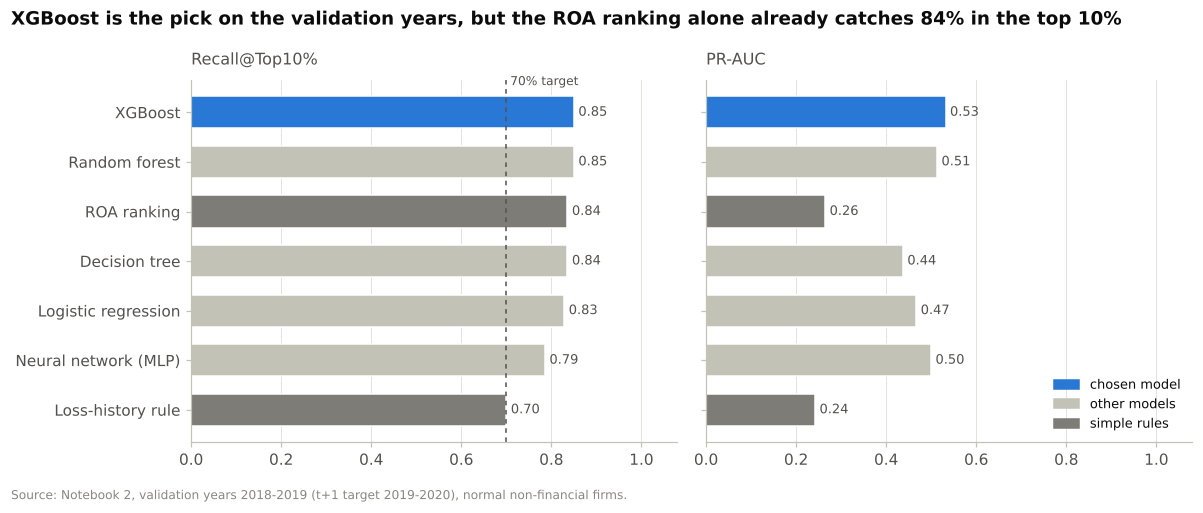

In [58]:
order = list(comparison_val.drop(index="Random order").sort_values("Recall@Top10%").index)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4), sharey=True)
for ax, col in zip(axes, ["Recall@Top10%", "PR-AUC"]):
    vals = comparison_val.loc[order, col]
    colors = [ACCENT if n == CHOSEN else (DARKGREY if n in base_val.index else CONTEXT) for n in order]
    ax.barh(order, vals, color=colors, height=0.65, edgecolor="white", linewidth=1)
    for yy, v in enumerate(vals):
        ax.text(v + 0.01, yy, f"{v:.2f}", va="center", fontsize=8.5, color=INK2)
    ax.set_xlim(0, 1.08)
    ax.set_title(col, fontsize=10.5, fontweight="normal", color=INK2)
    ax.grid(axis="y", visible=False)
axes[0].axvline(TARGET_RECALL, color=INK2, linewidth=1, linestyle=(0, (3, 3)))
axes[0].text(TARGET_RECALL, len(order) - 0.45, " 70% target", fontsize=8, color=INK2)
axes[1].legend(handles=[Patch(color=ACCENT, label="chosen model"), Patch(color=CONTEXT, label="other models"),
                        Patch(color=DARKGREY, label="simple rules")], loc="lower right", fontsize=8.5)
roa_r10 = comparison_val.loc["ROA ranking", "Recall@Top10%"]
fig.suptitle(f"{CHOSEN} is the pick on the validation years, but the ROA ranking alone already "
             f"catches {roa_r10:.0%} in the top 10%", x=0.01, ha="left", fontsize=12, fontweight="bold")
fig.tight_layout()
save(fig, "fig11_model_comparison_validation", "Source: Notebook 2, validation years 2018-2019 (t+1 target 2019-2020), normal non-financial firms.")

### 9.2 Choose the probability cut-off

**What and why.** The watch-list uses a **rank** rule: the riskiest 10% of firms each year, whatever their probabilities. That is the team's business rule, and the preferred way to fix a cut-off, because it is fixed before the test set is touched. We also set a **probability cut-off** for yes/no predictions, chosen where F1 is highest. We pick it on the validation years and apply it, unchanged, to the test years. It is stored in MySQL as `dim_model.decision_threshold` and drives `fact_risk_score.predicted_flag`.

Best-F1 cut-off on the validation years: 0.40 -> flags 2.1% of firms, recall 60.0%, precision 60.0%, F1 0.600
For comparison, the top-10% watch-list starts at a score of about 0.00445 in these years.


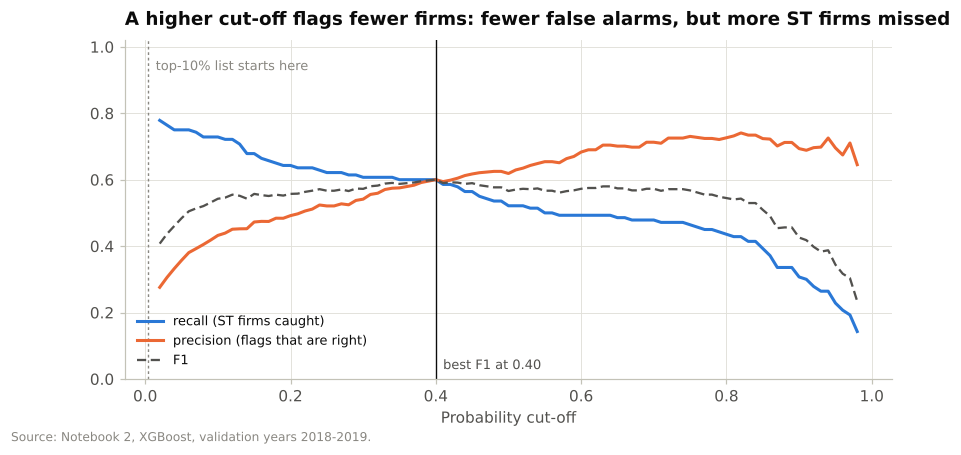

In [59]:
y_val, s_val = valid[TARGET].to_numpy(), val_scores[CHOSEN]
grid = np.round(np.arange(0.02, 0.99, 0.01), 2)
curve = pd.DataFrame([{"cut-off": t, "recall": recall_score(y_val, s_val >= t, zero_division=0),
                       "precision": precision_score(y_val, s_val >= t, zero_division=0),
                       "F1": f1_score(y_val, s_val >= t, zero_division=0), "flagged %": 100 * (s_val >= t).mean()}
                      for t in grid])
BEST_THRESHOLD = float(curve.loc[curve["F1"].idxmax(), "cut-off"])
watch_cut = np.mean([np.sort(s_val[valid.year.to_numpy() == yr])[::-1][int(np.ceil(WATCHLIST_SHARE * (valid.year == yr).sum())) - 1]
                     for yr in valid.year.unique()])
best = curve.loc[curve["F1"].idxmax()]
print(f"Best-F1 cut-off on the validation years: {BEST_THRESHOLD:.2f} -> flags {best['flagged %']:.1f}% of firms, "
      f"recall {best['recall']:.1%}, precision {best['precision']:.1%}, F1 {best['F1']:.3f}")
print(f"For comparison, the top-10% watch-list starts at a score of about {watch_cut:.3g} in these years.")

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(curve["cut-off"], curve["recall"], color=ACCENT, linewidth=2, label="recall (ST firms caught)")
ax.plot(curve["cut-off"], curve["precision"], color=SECOND, linewidth=2, label="precision (flags that are right)")
ax.plot(curve["cut-off"], curve["F1"], color=INK2, linewidth=1.5, linestyle=(0, (4, 2)), label="F1")
ax.axvline(BEST_THRESHOLD, color=INK, linewidth=0.9)
ax.text(BEST_THRESHOLD + 0.01, 0.03, f"best F1 at {BEST_THRESHOLD:.2f}", fontsize=8.5, color=INK2)
ax.axvline(watch_cut, color=MUTED, linewidth=0.9, linestyle=(0, (2, 2)))
ax.text(watch_cut + 0.01, 0.93, "top-10% list starts here", fontsize=8.5, color=MUTED)
ax.set_xlabel("Probability cut-off")
ax.set_ylim(0, 1.02)
ax.legend(loc="lower left", fontsize=8.5)
ax.set_title("A higher cut-off flags fewer firms: fewer false alarms, but more ST firms missed")
save(fig, "fig12_threshold_tradeoff", f"Source: Notebook 2, {CHOSEN}, validation years 2018-2019.")

**What the result shows.** **The choice.** Three models came within 0.02 of the best validation Recall@Top10% (0.850): XGBoost and the random forest (both 0.850) and the decision tree (0.836). Among them XGBoost has the highest PR-AUC (0.532, against 0.513 for the forest and 0.437 for the tree), so **XGBoost is the t+1 model**. The rule was fixed in section 1.1 before any result was seen, which keeps the choice honest.

**Against the bar.** On these years XGBoost catches 85.0% of the cases in its top 10%, against 83.6% for the ROA ranking: 2 more of the 140 cases. The bigger difference is the order inside the list: PR-AUC 0.532 against 0.264, and 75.7% of the cases inside the top 5% against 60.0%. The model puts the real cases nearer the top.

**The cut-off.** The best F1 comes at a probability of **0.40**: it flags 2.1% of firms and catches 60% of the cases, with 60% of its flags right. This is the yes/no rule for a reviewer who can only take a short list, and it is stored in `dim_model` as `decision_threshold`. The watch-list itself is the top 10% by rank, which in these years starts at a score of only about 0.004, because most firms score close to zero. A list defined by rank gives the reviewers the same workload every year (Objective 3), whatever happens to the scores.

## 10. The final test, once (Objective 1)

### 10.1 Test-year scores

**What and why.** Only now do we open the test years 2020-2022 (t+1 outcomes 2021-2023). The chosen model, its settings and its cut-off were all fixed before this point, so this is the fair, one-time exam. We show every model and rule for transparency, but the verdict is on the chosen model only; picking a different model now because it happens to score better on the test would turn the test into another validation round. The 95% interval comes from 1,000 resamples of the firms in each test year.

In [60]:
test_scores = {name: m.predict_proba(X(test))[:, 1] for name, m in tuned.items()}
test_scores.update(baseline_scores(test))
comparison_test = pd.DataFrame({name: report(test, s, TARGET, BEST_THRESHOLD if name == CHOSEN else None)
                                for name, s in test_scores.items()}).T
comparison_test["chosen"] = np.where(comparison_test.index == CHOSEN, "<- chosen", "")

def bootstrap_recalls(df, scores, target, share=WATCHLIST_SHARE, reps=None, seed=RANDOM_STATE):
    """Recall@Top for several score sets on the same resamples, so differences are paired."""
    reps = reps or BOOTSTRAP_REPS
    rng = np.random.default_rng(seed)
    years, y = df["year"].to_numpy(), df[target].to_numpy()
    S = np.column_stack([np.asarray(s, dtype=float) for s in scores])
    groups = [np.flatnonzero(years == yr) for yr in np.unique(years)]
    out = np.zeros((reps, S.shape[1]))
    for r in range(reps):
        caught, cases = np.zeros(S.shape[1]), 0
        for idx in groups:
            pick = rng.choice(idx, size=len(idx), replace=True)
            k = int(np.ceil(share * len(pick)))
            cases += y[pick].sum()
            for j in range(S.shape[1]):
                caught[j] += y[pick[np.argsort(-S[pick, j], kind="stable")[:k]]].sum()
        out[r] = caught / cases
    return out

boot = bootstrap_recalls(test, [test_scores[CHOSEN], test_scores["ROA ranking"]], TARGET)
ci_model, ci_roa = np.percentile(boot[:, 0], [2.5, 97.5]), np.percentile(boot[:, 1], [2.5, 97.5])
diff = boot[:, 0] - boot[:, 1]
r10 = comparison_test.loc[CHOSEN, "Recall@Top10%"]
r10_roa = comparison_test.loc["ROA ranking", "Recall@Top10%"]
print(f"OBJECTIVE 1 - test years 2020-2022, t+1 outcomes 2021-2023, {CHOSEN}:")
print(f"  Recall@Top10% = {r10:.1%} (95% interval {ci_model[0]:.1%} to {ci_model[1]:.1%}); target {TARGET_RECALL:.0%} "
      f"-> {'MET' if r10 >= TARGET_RECALL else 'NOT MET'}")
print(f"  ROA ranking   = {r10_roa:.1%} (95% interval {ci_roa[0]:.1%} to {ci_roa[1]:.1%})")
print(f"  Model minus ROA ranking: {100 * (r10 - r10_roa):+.1f} percentage points (95% interval "
      f"{100 * np.percentile(diff, 2.5):+.1f} to {100 * np.percentile(diff, 97.5):+.1f}); "
      f"the model is ahead in {np.mean(diff > 0):.0%} of resamples\n")
expect("Test Recall@Top10%, chosen model (full run)", r10, 108 / 154, tol=1e-9)
expect("Test Recall@Top10%, ROA ranking (full run)", r10_roa, 114 / 154, tol=1e-9)
comparison_test.round(3)

OBJECTIVE 1 - test years 2020-2022, t+1 outcomes 2021-2023, XGBoost:
  Recall@Top10% = 70.1% (95% interval 63.2% to 77.4%); target 70% -> MET
  ROA ranking   = 74.0% (95% interval 66.0% to 79.5%)
  Model minus ROA ranking: -3.9 percentage points (95% interval -9.6 to +3.7); the model is ahead in 19% of resamples

PASS  | Test Recall@Top10%, chosen model (full run): 0.701 (expected 0.701)
PASS  | Test Recall@Top10%, ROA ranking (full run): 0.740 (expected 0.740)


,Recall@Top10%,Precision@Top10%,Recall@Top5%,PR-AUC,ROC-AUC,Recall,Precision,F1,Balanced accuracy,Flagged %,chosen
Logistic regression,0.669,0.079,0.519,0.181,0.899,NaN,NaN,NaN,NaN,NaN,
Decision tree,0.662,0.078,0.513,0.087,0.776,NaN,NaN,NaN,NaN,NaN,
Random forest,0.740,0.088,0.526,0.176,0.920,NaN,NaN,NaN,NaN,NaN,
XGBoost,0.701,0.083,0.532,0.153,0.900,0.487,0.133,0.209,0.725,4.324,<- chosen
Neural network (MLP),0.701,0.083,0.545,0.273,0.911,NaN,NaN,NaN,NaN,NaN,
Random order,0.097,0.012,0.039,0.012,0.490,NaN,NaN,NaN,NaN,NaN,
Loss-history rule,0.630,0.075,0.351,0.073,0.868,NaN,NaN,NaN,NaN,NaN,
ROA ranking,0.740,0.088,0.500,0.147,0.904,NaN,NaN,NaN,NaN,NaN,


In [61]:
per_year = []
for yr, g in test.groupby("year"):
    idx = g.index.to_numpy()
    flags_m = top_share_flags(g, test_scores[CHOSEN][idx])
    flags_r = top_share_flags(g, test_scores["ROA ranking"][idx])
    per_year.append({"feature year": yr, "outcome year": yr + 1, "firms": len(g), "list size (10%)": int(flags_m.sum()),
                     "ST cases": int(g[TARGET].sum()), "caught by model": int((flags_m * g[TARGET]).sum()),
                     "Recall@Top10% model": (flags_m * g[TARGET]).sum() / g[TARGET].sum(),
                     "Recall@Top10% ROA ranking": (flags_r * g[TARGET]).sum() / g[TARGET].sum()})
per_year = pd.DataFrame(per_year)
per_year.round(3)

,feature year,outcome year,firms,list size (10%),ST cases,caught by model,Recall@Top10% model,Recall@Top10% ROA ranking
0,2020,2021,3826,383,55,37,0.673,0.691
1,2021,2022,4379,438,53,41,0.774,0.792
2,2022,2023,4792,480,46,30,0.652,0.739


### 10.2 How much of the problem does each list size catch? (the gains chart)

**What and why.** The gains chart answers the question a credit team actually asks: *if we review the riskiest x% of firms each year, what share of next year's ST cases do we catch?* The steeper the curve near the left, the better the ranking. The marked point is Objective 1: 70% of cases within 10% of firms.

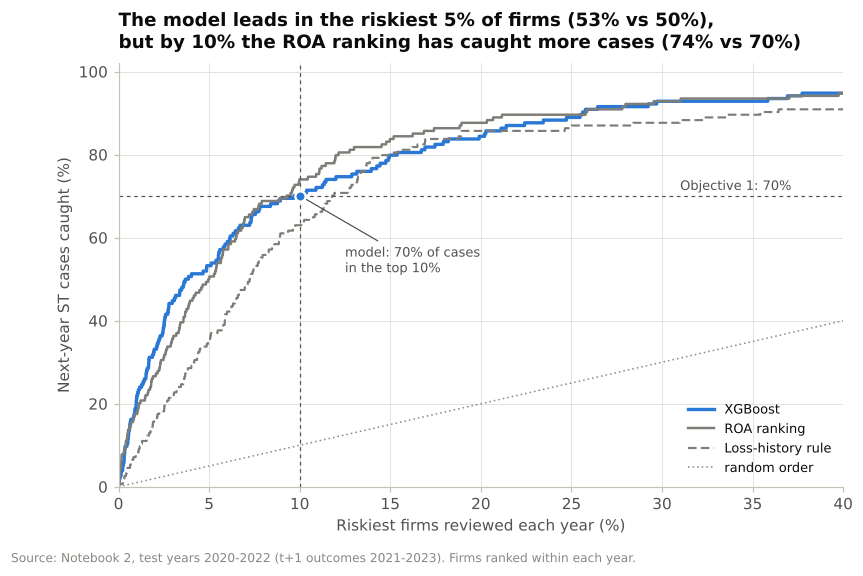

In [62]:
def gains(df, score, target):
    rank = year_rank(df, score)
    pct = rank / df.groupby("year")["year"].transform("size").to_numpy()
    y = df[target].to_numpy()[np.argsort(pct, kind="stable")]
    return np.arange(1, len(y) + 1) / len(y), np.cumsum(y) / y.sum()

fig, ax = plt.subplots(figsize=(8.5, 5))
for name, color, style, width in [(CHOSEN, ACCENT, "-", 2.2), ("ROA ranking", DARKGREY, "-", 1.6),
                                  ("Loss-history rule", DARKGREY, (0, (4, 2)), 1.4)]:
    gx, gy = gains(test, test_scores[name], TARGET)
    ax.plot(100 * gx, 100 * gy, color=color, linestyle=style, linewidth=width, label=name)
ax.plot([0, 100], [0, 100], color=MUTED, linewidth=1, linestyle=(0, (1, 2)), label="random order")
ax.axvline(100 * WATCHLIST_SHARE, color=INK2, linewidth=0.8, linestyle=(0, (3, 3)))
ax.axhline(100 * TARGET_RECALL, color=INK2, linewidth=0.8, linestyle=(0, (3, 3)))
ax.scatter([100 * WATCHLIST_SHARE], [100 * r10], color=ACCENT, s=45, zorder=5, edgecolor="white", linewidth=1.5)
ax.annotate(f"model: {r10:.0%} of cases\nin the top 10%", xy=(100 * WATCHLIST_SHARE, 100 * r10),
            xytext=(100 * WATCHLIST_SHARE + 2.5, 100 * r10 - 12), va="top", fontsize=8.5, color=INK2,
            arrowprops=dict(arrowstyle="-", color=INK2, linewidth=0.8))
ax.text(31, 100 * TARGET_RECALL + 1.5, "Objective 1: 70%", fontsize=8.5, color=INK2)
ax.set_xlim(0, 40); ax.set_ylim(0, 102)
ax.set_xlabel("Riskiest firms reviewed each year (%)")
ax.set_ylabel("Next-year ST cases caught (%)")
ax.legend(loc="lower right", fontsize=8.5)
r5, r5_roa = comparison_test.loc[CHOSEN, "Recall@Top5%"], comparison_test.loc["ROA ranking", "Recall@Top5%"]
if r10 >= r10_roa:
    ax.set_title(f"The model catches {r10:.0%} of next-year ST cases in its top 10%,\nagainst {r10_roa:.0%} for the ROA ranking")
elif r5 > r5_roa:
    ax.set_title(f"The model leads in the riskiest 5% of firms ({r5:.0%} vs {r5_roa:.0%}),\n"
                 f"but by 10% the ROA ranking has caught more cases ({r10_roa:.0%} vs {r10:.0%})")
else:
    ax.set_title(f"The ROA ranking catches as many cases as the model or more,\n"
                 f"in the top 5% ({r5_roa:.0%} vs {r5:.0%}) and the top 10% ({r10_roa:.0%} vs {r10:.0%})")
save(fig, "fig13_gains_test", "Source: Notebook 2, test years 2020-2022 (t+1 outcomes 2021-2023). Firms ranked within each year.")

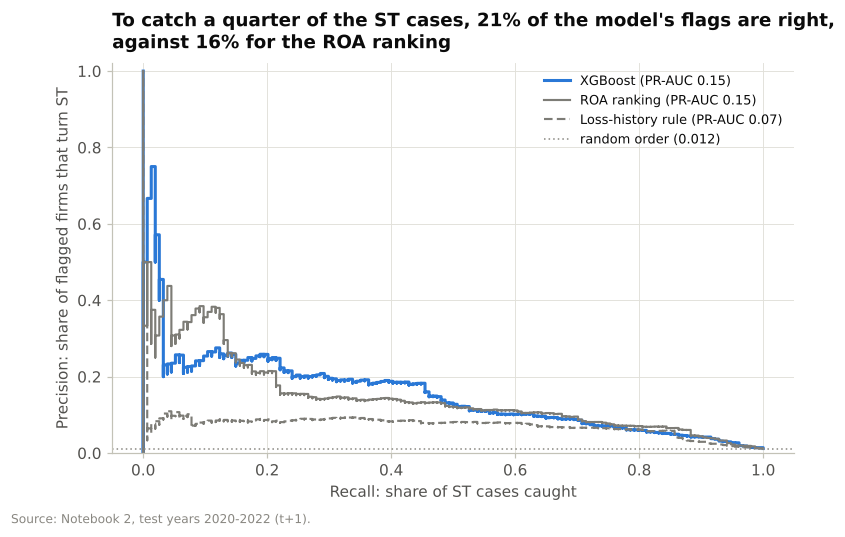

In [63]:
def precision_at_recall(y, s, level):
    """Best precision reached while catching at least `level` of the cases (interpolated precision)."""
    p, r, _ = precision_recall_curve(y, s)
    return p[r >= level].max()

fig, ax = plt.subplots(figsize=(8, 4.6))
for name, color, style in [(CHOSEN, ACCENT, "-"), ("ROA ranking", DARKGREY, "-"), ("Loss-history rule", DARKGREY, (0, (4, 2)))]:
    p, r, _ = precision_recall_curve(test[TARGET], test_scores[name])
    ax.plot(r, p, color=color, linestyle=style, linewidth=2 if name == CHOSEN else 1.4, drawstyle="steps-post",
            label=f"{name} (PR-AUC {average_precision_score(test[TARGET], test_scores[name]):.2f})")
ax.axhline(test[TARGET].mean(), color=MUTED, linewidth=1, linestyle=(0, (1, 2)), label=f"random order ({test[TARGET].mean():.3f})")
ax.set_xlabel("Recall: share of ST cases caught"); ax.set_ylabel("Precision: share of flagged firms that turn ST")
ax.set_ylim(0, 1.02); ax.legend(fontsize=8.5, loc="upper right")
p_m, p_r = (precision_at_recall(test[TARGET], test_scores[n], 0.25) for n in (CHOSEN, "ROA ranking"))
ax.set_title(f"To catch a quarter of the ST cases, {p_m:.0%} of the model's flags are right,\n"
             f"against {p_r:.0%} for the ROA ranking")
save(fig, "fig14_precision_recall_test", "Source: Notebook 2, test years 2020-2022 (t+1).")

### 10.3 Confusion matrices and risk bands

**What and why.** Two yes/no views of the same test scores, laid out the usual way (rows = actual, columns = predicted): the **watch-list rule** (top 10% of each year) and the **best-F1 cut-off** from 9.2. Then the three risk bands stored in MySQL: High = top 10% (the watch-list), Medium = next 10%, Low = the rest. The reading check for risk segments is that the actual rate must rise from Low to Medium to High.

Watch-list rule (top 10% of each year):
                      predicted: normal  predicted: ST risk
actual: stays normal              11650                1193
actual: turns ST                     46                 108

Best-F1 cut-off 0.40:
                      predicted: normal  predicted: ST risk
actual: stays normal              12356                 487
actual: turns ST                     79                  75

        firms  ST_cases  actual ST rate %  share of all ST cases %
band                                                              
High     1301       108              8.30                     70.1
Medium   1300        22              1.69                     14.3
Low     10396        24              0.23                     15.6


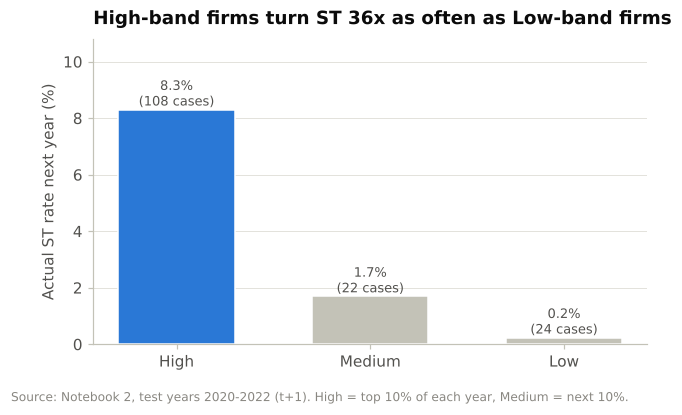

In [64]:
def confusion_table(y, pred):
    cm = confusion_matrix(y, pred, labels=[0, 1])
    return pd.DataFrame(cm, index=["actual: stays normal", "actual: turns ST"],
                        columns=["predicted: normal", "predicted: ST risk"])

y_test = test[TARGET].to_numpy()
flags_test = top_share_flags(test, test_scores[CHOSEN])
print("Watch-list rule (top 10% of each year):")
print(confusion_table(y_test, flags_test).to_string())
print(f"\nBest-F1 cut-off {BEST_THRESHOLD:.2f}:")
print(confusion_table(y_test, (test_scores[CHOSEN] >= BEST_THRESHOLD).astype(int)).to_string())

def band(df, score):
    rank = year_rank(df, score)
    n = df.groupby("year")["year"].transform("size").to_numpy()
    return np.where(rank <= np.ceil(WATCHLIST_SHARE * n), "High",
                    np.where(rank <= np.ceil((WATCHLIST_SHARE + MEDIUM_SHARE) * n), "Medium", "Low"))

bands = pd.DataFrame({"band": band(test, test_scores[CHOSEN]), "y": y_test})
band_table = bands.groupby("band")["y"].agg(firms="size", ST_cases="sum").reindex(["High", "Medium", "Low"])
band_table["actual ST rate %"] = (100 * band_table["ST_cases"] / band_table["firms"]).round(2)
band_table["share of all ST cases %"] = (100 * band_table["ST_cases"] / band_table["ST_cases"].sum()).round(1)
print()
print(band_table.to_string())

fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.bar(band_table.index, band_table["actual ST rate %"], color=[ACCENT, CONTEXT, CONTEXT], width=0.6, edgecolor="white")
for xx, (v, k) in enumerate(zip(band_table["actual ST rate %"], band_table["ST_cases"])):
    ax.text(xx, v + 0.15, f"{v:.1f}%\n({k} cases)", ha="center", fontsize=8.5, color=INK2)
ax.set_ylabel("Actual ST rate next year (%)"); ax.grid(axis="x", visible=False)
ax.set_ylim(0, band_table["actual ST rate %"].max() * 1.3)
ax.set_title(f"High-band firms turn ST {band_table.loc['High', 'actual ST rate %'] / max(band_table.loc['Low', 'actual ST rate %'], 0.01):.0f}x as often as Low-band firms")
save(fig, "fig15_risk_bands_test", "Source: Notebook 2, test years 2020-2022 (t+1). High = top 10% of each year, Medium = next 10%.")

**What the result shows.** **Objective 1 is met, narrowly.** In the test years 2020-2022, XGBoost puts 108 of the 154 next-year ST cases inside its top 10% of each year: **70.1%** (95% interval 63.2% to 77.4%). The interval reaches below 70%, so with other years the result could just as easily fall short. Present it as "met, at the edge".

**The ROA ranking does at least as well at a 10% list.** It catches 114 of the 154 cases (74.0%, interval 66.0% to 79.5%). The 3.9-point gap in its favour is within chance (interval -9.6 to +3.7 points; the model is ahead in only 19% of the resamples), so the honest reading is "no clear difference at 10%". The ROA ranking is ahead in each test year (2020: 69.1% against 67.3%; 2021: 79.2% against 77.4%; 2022: 73.9% against 65.2%). The random forest matches the ROA ranking (74.0%) and the neural network matches XGBoost (70.1%), but they were not the validation choice, and switching now would mean choosing on the test.

**Where the model is better: the top of the list.** In the riskiest 5% of firms it catches 53.2% of the cases against 50.0% (gains chart), and to catch a quarter of the cases 21% of its flags are right against 16% for the ROA ranking (precision-recall chart). Over the whole list the two have almost the same PR-AUC (0.153 against 0.147). A reviewer who reads only the first few hundred names gets a cleaner list from the model.

**What the list means in practice.**
- Of the 1,301 firms on the three yearly lists, 108 turned ST (8.3%, about 1 in 12) and 46 ST firms were missed (confusion matrix). The list is long because ST is rare.
- The bands still concentrate the risk. High-band firms turned ST at 8.30%, Medium at 1.69% and Low at 0.23%, so a High-band firm was 36 times as likely to turn ST as a Low-band firm. The top two bands (20% of firms) held 84% of the cases.

**The yes/no cut-off travels less well.** At 0.40 it caught 60% of the cases with 60% precision on validation, but 48.7% with 13.3% precision on the test, while flagging twice the share of firms (4.3% against 2.1%). A probability cut-off drifts when the ST rate changes (1.18% in the test years against 2.06% in validation); a list defined by rank keeps the same size every year, which is why the watch-list uses rank.

## 11. Evaluate deeply: who is missed, and are errors fair?

### 11.1 Which ST firms does the model miss?

**What and why.** A single overall number can hide a weak spot. We compare the test-year ST firms the watch-list **caught** with the ones it **missed**. If the misses look healthy on paper (profitable, low debt), no model built on these accounts could have caught them, and that is worth saying.

In [65]:
cases = test[y_test == 1].copy()
cases["caught"] = np.where(flags_test[y_test == 1] == 1, "caught", "missed")
profile = cases.groupby("caught").agg(
    firms=("stkcd", "size"), loss_this_year_pct=("Loss", lambda s: 100 * s.mean()),
    two_losses_pct=("Loss_2yr", lambda s: 100 * s.mean()), debts_exceed_assets_pct=("NegEquity", lambda s: 100 * s.mean()),
    was_ST_before_pct=("prior_ST", lambda s: 100 * s.mean()), median_ROA=("ROA", "median"), median_leverage=("Lev", "median"),
    median_asset_change=("Size_chg", "median"), median_sales_growth=("Growth", "median")).T
profile.round(3)

caught,caught,missed
firms,108.000,46.000
loss_this_year_pct,97.222,58.696
two_losses_pct,75.701,0.000
debts_exceed_assets_pct,23.148,0.000
was_ST_before_pct,19.444,32.609
median_ROA,-0.139,-0.012
median_leverage,0.809,0.414
median_asset_change,-0.152,-0.026
median_sales_growth,-0.247,-0.124


### 11.2 Where do the misses concentrate? (error tree)

**What and why.** An "error tree" is a shallow decision tree trained to predict *was the model wrong?* Its leaves show where mistakes cluster. We grow one on all ST cases of the validation and test years (more cases than the test alone), with a handful of readable inputs, and read its rules.

In [66]:
both = pd.concat([valid.assign(score=val_scores[CHOSEN], flag=top_share_flags(valid, val_scores[CHOSEN])),
                  test.assign(score=test_scores[CHOSEN], flag=flags_test)], ignore_index=True)
st_cases = both[both[TARGET] == 1].copy()
st_cases["missed"] = 1 - st_cases["flag"]
tree_inputs = ["ROA", "Loss", "Loss_2yr", "Lev", "Size_chg", "Growth", "Cashflow", "Pay"]
Xe = st_cases[tree_inputs].fillna(st_cases[tree_inputs].median())
error_tree = DecisionTreeClassifier(max_depth=2, min_samples_leaf=15, random_state=RANDOM_STATE).fit(Xe, st_cases["missed"])
print(f"ST cases in validation + test years: {len(st_cases)}; missed by the watch-list: {int(st_cases['missed'].sum())} "
      f"({st_cases['missed'].mean():.0%})\n")
print(export_text(error_tree, feature_names=tree_inputs, show_weights=True))
leaf = error_tree.apply(Xe)
leaves = st_cases.assign(leaf=leaf).groupby("leaf").agg(ST_cases=("missed", "size"), missed=("missed", "sum"),
                                                         median_ROA=("ROA", "median"), loss_pct=("Loss", lambda s: 100 * s.mean()))
leaves["missed %"] = (100 * leaves["missed"] / leaves["ST_cases"]).round(1)
leaves.round(3)

ST cases in validation + test years: 294; missed by the watch-list: 67 (23%)

|--- ROA <= -0.01
|   |--- Loss_2yr <= 0.50
|   |   |--- weights: [57.00, 27.00] class: 0
|   |--- Loss_2yr >  0.50
|   |   |--- weights: [166.00, 0.00] class: 0
|--- ROA >  -0.01
|   |--- Growth <= -0.07
|   |   |--- weights: [4.00, 14.00] class: 1
|   |--- Growth >  -0.07
|   |   |--- weights: [0.00, 26.00] class: 1



,ST_cases,missed,median_ROA,loss_pct,missed %
leaf,,,,,
2,84,27,-0.110,89.286,32.1
3,166,0,-0.159,100.000,0.0
5,18,14,0.020,16.667,77.8
6,26,26,0.024,7.692,100.0


### 11.3 Are the errors spread fairly across groups?

**What and why.** The model card asks for error rates per group with 95% intervals. We check listing board, ownership (state-owned or private) and region, at the watch-list rule:
- **FNR** (miss rate) = ST firms *not* on the list ÷ all ST firms in the group. A high FNR means the group's failing firms slip through.
- **FPR** (false-alarm rate) = normal firms on the list ÷ all normal firms in the group. A high FPR means the group's healthy firms get extra scrutiny.
- **FDR** = share of the group's flags that are wrong; **FOR** = share of the group's unflagged firms that do turn ST.

A group with fewer than 20 ST cases gives intervals too wide to judge, so it is marked rather than interpreted. Listing board was kept out of the inputs (Notebook 1, 8.1), but checking errors by board is exactly why the column was kept.

In [67]:
def error_rates(y, flag):
    tp, fp = int(((flag == 1) & (y == 1)).sum()), int(((flag == 1) & (y == 0)).sum())
    fn, tn = int(((flag == 0) & (y == 1)).sum()), int(((flag == 0) & (y == 0)).sum())
    div = lambda a, b: a / b if b else np.nan
    return {"FPR": div(fp, fp + tn), "FNR": div(fn, fn + tp), "FDR": div(fp, fp + tp), "FOR": div(fn, fn + tn)}

rng = np.random.default_rng(RANDOM_STATE)
groups = {"listing board": test["listing_board"], "ownership": test["SOE"].map({1: "State-owned", 0: "Private"}),
          "region": test["region"]}
rows = []
for gname, labels in groups.items():
    for level in labels.dropna().unique():
        idx = np.flatnonzero(labels.to_numpy() == level)
        y_g, f_g = y_test[idx], flags_test[idx]
        point = error_rates(y_g, f_g)
        reps = [error_rates(y_g[s], f_g[s]) for s in (rng.choice(len(idx), len(idx)) for _ in range(500))]
        row = {"factor": gname, "group": level, "firms": len(idx), "ST cases": int(y_g.sum()),
               "flagged %": round(100 * f_g.mean(), 1)}
        for k in ["FNR", "FPR", "FDR", "FOR"]:
            vals = np.array([r[k] for r in reps], dtype=float)
            vals = vals[~np.isnan(vals)]
            row[k] = round(point[k], 3) if not np.isnan(point[k]) else np.nan
            lo_k, hi_k = np.percentile(vals, [2.5, 97.5]) if len(vals) else (np.nan, np.nan)
            row[f"{k} 95% interval"] = "n/a" if len(vals) == 0 else f"{lo_k:.2f}-{hi_k:.2f}"
            row[f"{k} low"], row[f"{k} high"] = lo_k, hi_k
        row["judgeable"] = "yes" if y_g.sum() >= 20 else "too few ST cases"
        rows.append(row)
subgroups = pd.DataFrame(rows)
overall = error_rates(y_test, flags_test)
print("Whole test set: " + ", ".join(f"{k} {v:.3f}" for k, v in overall.items()))
subgroups[["factor", "group", "firms", "ST cases", "flagged %", "FNR", "FNR 95% interval", "FPR", "FPR 95% interval",
           "FDR", "FOR", "judgeable"]]

Whole test set: FPR 0.093, FNR 0.299, FDR 0.917, FOR 0.004


,factor,group,firms,ST cases,flagged %,FNR,FNR 95% interval,FPR,FPR 95% interval,FDR,FOR,judgeable
0,listing board,Main board,8469,115,10.2,0.313,0.24-0.40,0.094,0.09-0.10,0.909,0.005,yes
1,listing board,B-share,35,1,34.3,0.000,0.00-0.00,0.324,0.18-0.49,0.917,0.000,too few ST cases
2,listing board,ChiNext,3146,35,10.8,0.229,0.09-0.38,0.101,0.09-0.11,0.921,0.003,yes
3,listing board,Beijing,261,0,1.9,NaN,n/a,0.019,0.00-0.04,1.000,0.000,too few ST cases
4,listing board,STAR Market,1086,3,6.9,0.667,0.00-1.00,0.068,0.05-0.08,0.987,0.002,too few ST cases
5,ownership,State-owned,3678,35,11.0,0.371,0.21-0.53,0.105,0.10-0.12,0.945,0.004,yes
6,ownership,Private,9319,119,9.6,0.277,0.20-0.36,0.088,0.08-0.09,0.904,0.004,yes
7,region,East,9636,106,9.6,0.330,0.25-0.43,0.089,0.08-0.09,0.923,0.004,yes
8,region,Central,1989,25,11.2,0.120,0.00-0.28,0.102,0.09-0.12,0.901,0.002,yes
9,region,West,1356,23,11.3,0.348,0.16-0.55,0.104,0.09-0.12,0.902,0.007,yes


Groups whose interval misses the whole-test-set rate: ['Central region (fewer misses)', 'State-owned firms (more false alarms)']


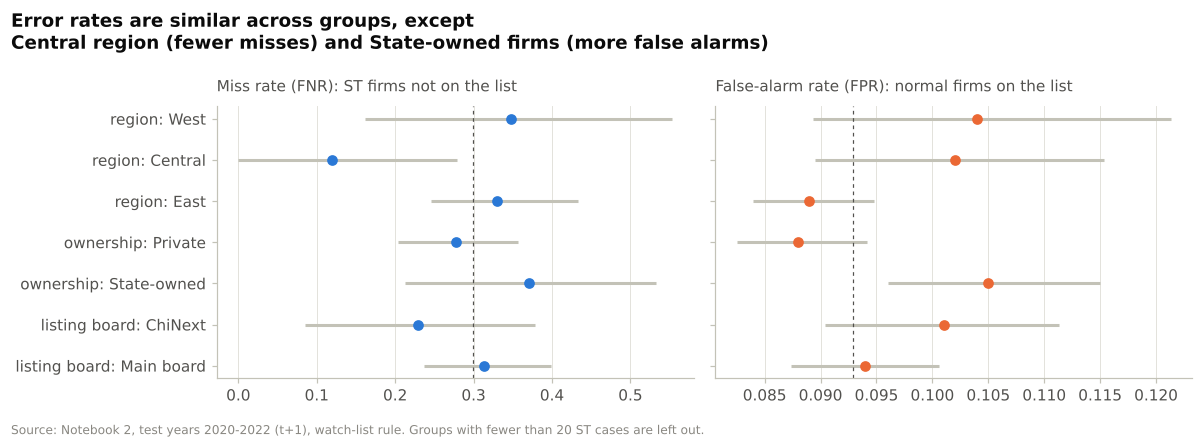

In [68]:
ok = subgroups[subgroups["judgeable"] == "yes"].reset_index(drop=True)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
labels_ = ok["factor"] + ": " + ok["group"].astype(str)
for ax, k, color in [(axes[0], "FNR", ACCENT), (axes[1], "FPR", SECOND)]:
    lo, hi = ok[f"{k} low"], ok[f"{k} high"]
    ax.errorbar(ok[k], range(len(ok)), xerr=[ok[k] - lo, hi - ok[k]], fmt="o", color=color, ecolor=AXIS,
                elinewidth=2, capsize=0, markersize=6)
    ax.axvline(overall[k], color=INK2, linewidth=0.8, linestyle=(0, (3, 3)))
    ax.set_yticks(range(len(ok)), labels_)
    ax.set_title({"FNR": "Miss rate (FNR): ST firms not on the list", "FPR": "False-alarm rate (FPR): normal firms on the list"}[k],
                 fontsize=10, fontweight="normal", color=INK2)
    ax.grid(axis="y", visible=False)
# A rough screen, not a formal test: does a group's 95% interval miss the whole-test-set rate?
NAME = {"region": "{} region", "ownership": "{} firms", "listing board": "{} firms"}
stand_out = []
for k, fewer, more in [("FNR", "fewer misses", "more misses"), ("FPR", "fewer false alarms", "more false alarms")]:
    for _, r in ok.iterrows():
        if r[f"{k} high"] < overall[k] or r[f"{k} low"] > overall[k]:
            stand_out.append(f"{NAME[r['factor']].format(r['group'])} ({fewer if r[f'{k} high'] < overall[k] else more})")
if stand_out:
    listed = " and ".join([", ".join(stand_out[:-1]), stand_out[-1]]) if len(stand_out) > 1 else stand_out[0]
    title16 = "Error rates are similar across groups, except " + listed
    if len(title16) > 95:
        title16 = title16.replace(" except ", " except\n", 1)
else:
    title16 = "No group's miss or false-alarm rate stands out from the whole test set (dashed line)"
fig.suptitle(title16, x=0.01, ha="left", fontsize=12, fontweight="bold")
print("Groups whose interval misses the whole-test-set rate:", stand_out if stand_out else "none")
fig.tight_layout()
save(fig, "fig16_subgroup_error_rates", "Source: Notebook 2, test years 2020-2022 (t+1), watch-list rule. Groups with fewer than 20 ST cases are left out.")

**What the result shows.** **Who is missed.** The 46 missed ST firms looked healthy on paper a year before. Only 59% made a loss (97% of the caught firms did), none had two losses in a row (76% of the caught firms did), none had debts above assets (23%), and their median ROA was -1.2% against -13.9%. One in three missed firms had been ST before, more than among the caught firms (33% against 19%).

**Where the misses concentrate** (error tree on the validation and test years: 294 cases, 67 missed):

| Group of ST firms, one year before | ST cases | Missed |
|---|---|---|
| ROA at or below -1% and two losses in a row | 166 | 0 (0%) |
| ROA at or below -1%, no two losses in a row | 84 | 27 (32%) |
| ROA above -1% and sales down by more than 7% | 18 | 14 (78%) |
| ROA above -1% and sales not down by that much | 26 | 26 (100%) |

The model never misses a loss-making firm with two straight losses, and it misses every case among firms that were profitable with steady sales. Whatever put those firms under ST is not visible in the year-t ratios this dataset holds; finding it would need information the dataset does not have, such as the stated reason for each ST designation. Section 13e measures how the model and the ROA ranking do on these harder cases.

**Are the errors fair across groups?** Over the whole test set the list misses 29.9% of the cases (FNR) and puts 9.3% of normal firms on the list (FPR). Two groups differ by more than chance:
- Firms in the **Central region** are missed less often (FNR 12%, interval 0% to 28%, from 25 cases).
- **State-owned firms** are put on the list a little more often (FPR 10.5%, interval 10% to 12%, against 9.3%). For a lender this means slightly more review work on state-owned borrowers, not more missed risk; their miss rate (37%, interval 21% to 53%) is within chance of the whole set.

Every other group with enough cases sits within chance of the whole set. B-share, Beijing, STAR Market and unknown-region firms have too few ST cases in the test years (0 to 3) to judge.

## 12. Which indicators matter? (Objective 2)

**What and why.** Notebook 1 ranked the 17 indicator families by how well each separates future-ST firms **on its own** (EDA, `eda_indicator_ranking.csv`). That view cannot tell whether two families say the same thing. Here we add three model-based views and then combine them:
1. **Grouped permutation importance** (main view): scramble all columns of one family at once on the validation years and measure how much the chosen model's PR-AUC and Recall@Top10% drop. A big drop means the model relies on that family and the others cannot stand in for it. Scrambling the whole family together side-steps the problem that correlated columns share credit.
2. **Logistic regression with odds ratios** (the explainable view): one representative input per family, so the coefficients are stable, with the variance inflation factor (VIF) as the multicollinearity check.
3. **The chosen model's built-in importance**, summed by family.

**The final top five** = the families with the best average of their EDA rank and their permutation rank. Both halves of the objective's wording ("through EDA and model-based feature importance") get equal weight.

In [69]:
def permutation_by_family(model, df, target, repeats=10, seed=RANDOM_STATE):
    """Drop in PR-AUC and Recall@Top10% when one family's columns are shuffled together."""
    rng = np.random.default_rng(seed)
    base = model.predict_proba(X(df))[:, 1]
    base_pr, base_r10 = average_precision_score(df[target], base), recall_at_top(df, base, target)
    rows = []
    for fam, members in FAMILIES.items():
        d_pr, d_r10 = [], []
        for _ in range(repeats):
            perm, shuffled = rng.permutation(len(df)), df.copy()
            for c in members:
                shuffled[c] = df[c].to_numpy()[perm]
            s = model.predict_proba(X(shuffled))[:, 1]
            d_pr.append(base_pr - average_precision_score(df[target], s))
            d_r10.append(base_r10 - recall_at_top(df, s, target))
        rows.append({"family": fam, "type": FAMILY_TYPE[fam], "PR-AUC drop": np.mean(d_pr),
                     "PR-AUC drop sd": np.std(d_pr), "Recall@Top10% drop": np.mean(d_r10)})
    return pd.DataFrame(rows).sort_values("PR-AUC drop", ascending=False).reset_index(drop=True)

t0 = time.time()
perm = permutation_by_family(tuned[CHOSEN], valid, TARGET, repeats=3 if FAST else 10)
perm.insert(0, "model rank", range(1, len(perm) + 1))
print(f"Permutation importance by family on the validation years ({time.time() - t0:.0f} s):")
perm.round(4)

Permutation importance by family on the validation years (7 s):


,model rank,family,type,PR-AUC drop,PR-AUC drop sd,Recall@Top10% drop
0,1,Profitability and losses,Financial,0.4477,0.0068,0.3593
1,2,Debt and solvency,Financial,0.0347,0.0086,0.0150
2,3,Ownership structure,Governance,0.0194,0.0081,0.0014
3,4,Asset mix,Financial,0.0146,0.0054,0.0007
4,5,Funds taken by big shareholders,Governance,0.0115,0.0034,0.0243
5,6,Management costs,Governance,0.0062,0.0045,-0.0036
6,7,Sales growth,Financial,0.0059,0.0015,-0.0007
7,8,Size and shrinking,Financial,0.0054,0.0060,0.0136
8,9,Asset turnover,Financial,0.0050,0.0048,0.0007
9,10,Firm age,Context,0.0030,0.0042,0.0000


In [70]:
eda_rank = pd.read_csv(EDA_DIR / "eda_indicator_ranking.csv")   # the finished EDA (Notebook 1b v2)
REPRESENTATIVE = {r.family: r.strongest_feature for r in eda_rank.itertuples() if r.strongest_feature in NUMERIC + BINARY}
logit_cols = list(REPRESENTATIVE.values())
num_cols = [c for c in logit_cols if c in NUMERIC]
fill = train[logit_cols].median()
mu, sd = train[num_cols].fillna(fill[num_cols]).mean(), train[num_cols].fillna(fill[num_cols]).std()

def logit_design(df):
    Z = df[logit_cols].fillna(fill).astype(float)
    Z[num_cols] = (Z[num_cols] - mu) / sd
    return sm.add_constant(Z)

logit = sm.Logit(train[TARGET], logit_design(train)).fit(disp=0, maxiter=200)
ci = logit.conf_int()
logit_table = pd.DataFrame({
    "family": [next(f for f, c in REPRESENTATIVE.items() if c == col) for col in logit_cols],
    "input": logit_cols,
    "coef": logit.params[logit_cols].to_numpy(),
    "odds ratio": np.exp(logit.params[logit_cols]).to_numpy(),
    "OR 95% CI": [f"{np.exp(ci.loc[c, 0]):.2f}-{np.exp(ci.loc[c, 1]):.2f}" for c in logit_cols],
    "p-value": logit.pvalues[logit_cols].to_numpy(),
    "unit": ["+1 standard deviation" if c in num_cols else "yes vs no" for c in logit_cols]})
logit_table["significant (p < 0.05)"] = np.where(logit_table["p-value"] < 0.05, "yes", "no")
D = logit_design(train)
logit_table["VIF"] = [variance_inflation_factor(D.to_numpy(), list(D.columns).index(c)) for c in logit_cols]
print(f"Model fit: LLR p-value {logit.llr_pvalue:.1e} (beats an intercept-only model if < 0.05), "
      f"pseudo R-squared {logit.prsquared:.3f}; {len(train):,} training rows")
print(f"Validation PR-AUC of this compact logit: {average_precision_score(valid[TARGET], logit.predict(logit_design(valid))):.3f}; "
      f"largest VIF {logit_table['VIF'].max():.1f} (above 5 would be a concern)\n")
logit_table.sort_values("p-value").round(4)

Model fit: LLR p-value 0.0e+00 (beats an intercept-only model if < 0.05), pseudo R-squared 0.524; 28,673 training rows
Validation PR-AUC of this compact logit: 0.425; largest VIF 1.9 (above 5 would be a concern)



,family,input,coef,odds ratio,OR 95% CI,p-value,unit,significant (p < 0.05),VIF
0,Profitability and losses,ROA,-1.3599,0.2567,0.23-0.29,0.0000,+1 standard deviation,yes,1.9131
2,Debt and solvency,Lev,0.5959,1.8147,1.59-2.08,0.0000,+1 standard deviation,yes,1.7329
3,Executive pay,Pay,-0.2499,0.7789,0.70-0.87,0.0000,+1 standard deviation,yes,1.1819
10,Asset mix,FIXED,0.1968,1.2175,1.08-1.37,0.0009,+1 standard deviation,yes,1.2979
1,Size and shrinking,Size_chg,-0.2690,0.7641,0.65-0.90,0.0009,+1 standard deviation,yes,1.4102
7,Asset turnover,ATO,-0.2450,0.7827,0.67-0.91,0.0015,+1 standard deviation,yes,1.1195
6,Funds taken by big shareholders,Occupy,0.0923,1.0967,1.02-1.18,0.0090,+1 standard deviation,yes,1.2000
13,Board structure,Indep,-0.1345,0.8741,0.79-0.97,0.0101,+1 standard deviation,yes,1.1182
14,Market valuation,TobinQ,0.1206,1.1281,1.02-1.25,0.0175,+1 standard deviation,yes,1.1935
8,Ownership structure,Mshare,-0.3341,0.7160,0.52-0.99,0.0416,+1 standard deviation,yes,1.5480


In [71]:
def raw_input(col):
    """Map a model column back to its input (was-blank flags and category levels belong to their input)."""
    if col.startswith("missingindicator_"):
        return col[len("missingindicator_"):]
    for c in CATEGORICAL:
        if col.startswith(c + "_"):
            return c
    return col

final_est = tuned[CHOSEN].named_steps["model"]
cols = tuned[CHOSEN].named_steps["prep"].get_feature_names_out()
if hasattr(final_est, "feature_importances_"):
    weights = pd.Series(final_est.feature_importances_, index=cols)
    weight_kind = "built-in importance (share of total)"
elif hasattr(final_est, "coef_"):
    weights = pd.Series(np.abs(final_est.coef_[0]), index=cols)
    weight_kind = "sum of absolute standardised coefficients"
else:
    weights = None
if weights is not None:
    builtin = (weights.groupby(weights.index.map(lambda c: FEATURE_FAMILY.get(raw_input(c), "other"))).sum()
               .sort_values(ascending=False))
    builtin = (builtin / builtin.sum()).rename("built-in share")
    print(f"{CHOSEN}: {weight_kind}, summed by family")
    display(builtin.round(3).to_frame())
else:
    builtin = pd.Series(dtype=float, name="built-in share")
    print(f"{CHOSEN} has no built-in importance; the permutation view above is used on its own.")

XGBoost: built-in importance (share of total), summed by family


,built-in share
Profitability and losses,0.824
Ownership structure,0.032
Debt and solvency,0.025
Asset mix,0.016
Size and shrinking,0.016
Industry and region,0.012
Operating cash flow,0.011
Executive pay,0.010
Funds taken by big shareholders,0.009
Firm age,0.009


In [72]:
FAMILY_PLAIN = {
    "Profitability and losses": "earns little or loses money on its assets, often two years running",
    "Size and shrinking": "is small, and its assets are shrinking",
    "Debt and solvency": "carries a large and rising share of debt; at worst debts exceed assets",
    "Operating cash flow": "brings in little cash from day-to-day operations",
    "Sales growth": "has falling revenue",
    "Asset turnover": "makes little revenue per unit of assets",
    "Asset mix": "has assets tied up in plant and equipment",
    "Management costs": "spends a large share of revenue on admin and selling costs (Type-I agency cost)",
    "Funds taken by big shareholders": "has money tied up by large shareholders as other receivables (Type-II agency cost)",
    "Executive pay": "pays its top managers less in total",
    "Ownership structure": "has a less concentrated ownership with fewer institutional and manager shareholders",
    "Board structure": "differs in board size, independence or CEO duality",
    "Audit quality": "is not audited by a Big Four firm",
    "Market valuation": "has a different market-to-book value (Tobin's Q)",
    "Firm age": "has been listed for longer",
    "ST history": "was under ST before",
    "Industry and region": "sits in a higher-risk industry or region",
}
ranking = (perm[["family", "type", "model rank", "PR-AUC drop", "Recall@Top10% drop"]]
           .merge(eda_rank[["family", "EDA rank", "EDA_strength", "strongest_feature", "direction"]], on="family"))
ranking["built-in share"] = ranking["family"].map(builtin).fillna(0)
ranking["average rank"] = (ranking["EDA rank"] + ranking["model rank"]) / 2
ranking = ranking.sort_values(["average rank", "model rank"]).reset_index(drop=True)
ranking.insert(0, "final rank", range(1, len(ranking) + 1))
ranking["a riskier firm..."] = ranking["family"].map(FAMILY_PLAIN)
logit_sig = logit_table.set_index("family")["significant (p < 0.05)"]
ranking["logit: significant?"] = ranking["family"].map(logit_sig).fillna("(category, not in logit)")
TOP5 = ranking.head(TOP_N_INDICATORS)
edge = ranking.loc[TOP_N_INDICATORS - 1, "average rank"]
tied_at_edge = ranking[ranking["average rank"] == edge]
ranking.to_csv(OUT_DIR / "indicator_ranking_final.csv", index=False)
print(f"OBJECTIVE 2 - the top {TOP_N_INDICATORS} indicator families (average of EDA rank and model rank):")
for r in TOP5.itertuples():
    print(f"  {r[1]}. {r.family} ({r.type.lower()}): EDA rank {r[ranking.columns.get_loc('EDA rank') + 1]}, "
          f"model rank {r[ranking.columns.get_loc('model rank') + 1]}; a riskier firm {FAMILY_PLAIN[r.family]}")
if tied_at_edge["final rank"].max() > TOP_N_INDICATORS:
    print(f"\nNote: {len(tied_at_edge)} families share the average rank {edge:g} at the edge of the top {TOP_N_INDICATORS} "
          f"({', '.join(tied_at_edge['family'])}); the better model rank breaks the tie.")
expect_text("Final top five families (full run)", ", ".join(TOP5["family"]),
            "Profitability and losses, Debt and solvency, Size and shrinking, Ownership structure, Funds taken by big shareholders")
ranking[["final rank", "family", "type", "EDA rank", "model rank", "average rank", "PR-AUC drop", "Recall@Top10% drop",
         "built-in share", "logit: significant?", "strongest_feature", "direction"]].round(4)

OBJECTIVE 2 - the top 5 indicator families (average of EDA rank and model rank):
  1. Profitability and losses (financial): EDA rank 1, model rank 1; a riskier firm earns little or loses money on its assets, often two years running
  2. Debt and solvency (financial): EDA rank 3, model rank 2; a riskier firm carries a large and rising share of debt; at worst debts exceed assets
  3. Size and shrinking (financial): EDA rank 2, model rank 8; a riskier firm is small, and its assets are shrinking
  4. Ownership structure (governance): EDA rank 9, model rank 3; a riskier firm has a less concentrated ownership with fewer institutional and manager shareholders
  5. Funds taken by big shareholders (governance): EDA rank 7, model rank 5; a riskier firm has money tied up by large shareholders as other receivables (Type-II agency cost)

Note: 4 families share the average rank 6 at the edge of the top 5 (Ownership structure, Funds taken by big shareholders, Management costs, Sales growth); the bett

,final rank,family,type,EDA rank,model rank,average rank,PR-AUC drop,Recall@Top10% drop,built-in share,logit: significant?,strongest_feature,direction
0,1,Profitability and losses,Financial,1,1,1.0,0.4477,0.3593,0.8237,yes,ROA,lower = riskier
1,2,Debt and solvency,Financial,3,2,2.5,0.0347,0.0150,0.0254,yes,Lev,higher = riskier
2,3,Size and shrinking,Financial,2,8,5.0,0.0054,0.0136,0.0159,yes,Size_chg,lower = riskier
3,4,Ownership structure,Governance,9,3,6.0,0.0194,0.0014,0.0319,yes,Mshare,lower = riskier
4,5,Funds taken by big shareholders,Governance,7,5,6.0,0.0115,0.0243,0.0095,yes,Occupy,higher = riskier
5,6,Management costs,Governance,6,6,6.0,0.0062,-0.0036,0.0087,no,Mfee,higher = riskier
6,7,Sales growth,Financial,5,7,6.0,0.0059,-0.0007,0.0036,no,Growth,lower = riskier
7,8,Asset mix,Financial,11,4,7.5,0.0146,0.0007,0.0162,yes,FIXED,higher = riskier
8,9,Executive pay,Governance,4,11,7.5,0.0023,0.0071,0.0098,yes,Pay,lower = riskier
9,10,Asset turnover,Financial,8,9,8.5,0.0050,0.0007,0.0071,yes,ATO,lower = riskier


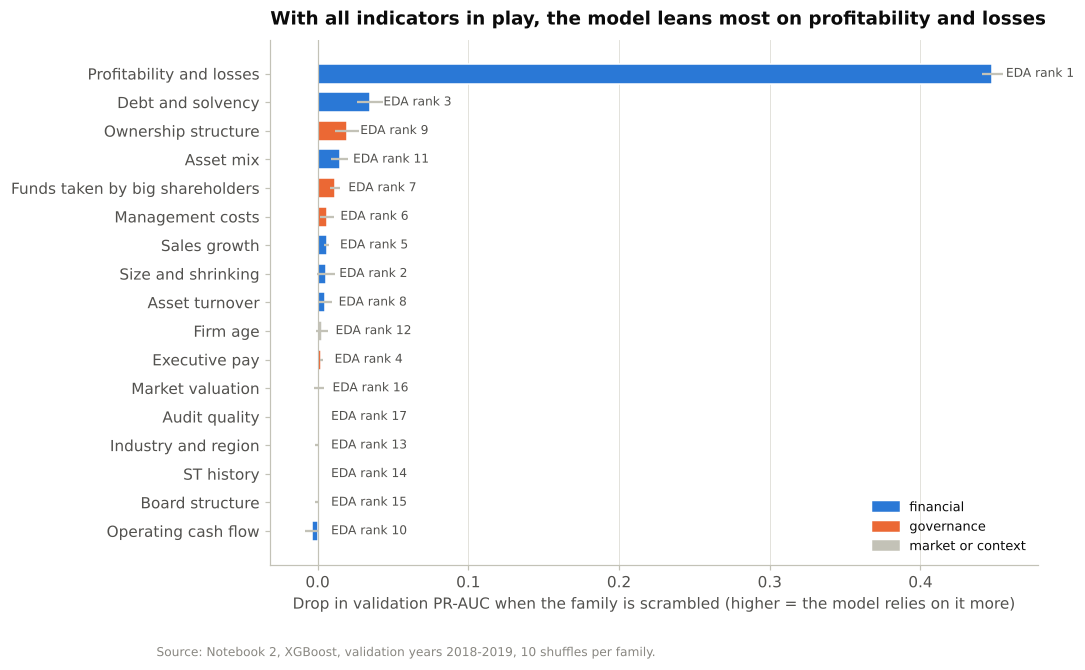

In [73]:
TYPE_COLOR = {"Financial": ACCENT, "Governance": SECOND, "Market": CONTEXT, "Context": CONTEXT}
shown = perm.sort_values("PR-AUC drop")
fig, ax = plt.subplots(figsize=(9, 6.2))
ax.barh(shown["family"], shown["PR-AUC drop"], color=[TYPE_COLOR[t] for t in shown["type"]], height=0.7,
        edgecolor="white", linewidth=1, xerr=shown["PR-AUC drop sd"], error_kw={"ecolor": AXIS, "elinewidth": 1.5})
eda_lookup = eda_rank.set_index("family")["EDA rank"]
for yy, (v, fam) in enumerate(zip(shown["PR-AUC drop"], shown["family"])):
    ax.text(max(v, 0) + shown["PR-AUC drop"].max() * 0.02, yy, f"EDA rank {eda_lookup[fam]}", va="center", fontsize=8, color=INK2)
ax.axvline(0, color=AXIS, linewidth=0.8)
ax.set_xlabel("Drop in validation PR-AUC when the family is scrambled (higher = the model relies on it more)")
ax.grid(axis="y", visible=False)
ax.legend(handles=[Patch(color=ACCENT, label="financial"), Patch(color=SECOND, label="governance"),
                   Patch(color=CONTEXT, label="market or context")], loc="lower right", fontsize=8.5)
top_names = ", ".join(TOP5["family"].str.lower().tolist()[:3])
ax.set_title(f"With all indicators in play, the model leans most on {perm['family'].iloc[0].lower()}")
save(fig, "fig17_family_importance", f"Source: Notebook 2, {CHOSEN}, validation years 2018-2019, 10 shuffles per family.")

**What the result shows.** **One family dominates.** Scrambling the profitability-and-losses inputs cuts the model's validation PR-AUC by 0.448 (from 0.532 to about 0.08); no other family costs more than 0.035. XGBoost's built-in importance agrees, giving that family 82% of the total. Every other family adds a little on top.

**The logistic regression agrees on direction.** With one input per family (largest VIF 1.9, so no input is a near-copy of another), 10 of the 16 inputs are significant. Per one standard deviation:
- **Lower odds of turning ST:** higher ROA (odds ratio 0.26, the odds fall by about three quarters), higher executive pay (0.78), a growing asset base (0.76), faster asset turnover (0.78), a more independent board (0.87) and more management ownership (0.72).
- **Higher odds:** more debt (1.81), more fixed assets (1.22), more funds taken by big shareholders (1.10) and a higher Tobin's Q (1.13).

These are associations, not causes.

**The final top five (Objective 2)**, ranked by the average of the EDA rank and the model rank:
1. **Profitability and losses** (financial): EDA 1, model 1.
2. **Debt and solvency** (financial): EDA 3, model 2.
3. **Size and shrinking** (financial): EDA 2, model 8.
4. **Ownership structure** (governance): EDA 9, model 3.
5. **Funds taken by big shareholders** (governance): EDA 7, model 5.

**Two cautions.**
- **Places 4 and 5 come out of a four-way tie** (average rank 6.0) with management costs (EDA 6, model 6) and sales growth (EDA 5, model 7). Breaking the tie by the model rank is a rule we chose; one may prefer to report "a clear top three, then four close candidates".
- **Beyond the first two families the differences are small.** The PR-AUC drops for places 3 to 9 run from 0.005 to 0.019, with shuffle-to-shuffle spreads of 0.002 to 0.008, so read them as a group, not a strict order.

Executive pay, fourth in the EDA, falls to 11th in the model. It stays significant in the logistic regression (odds ratio 0.78), but XGBoost finds little in it that the other families do not already carry.

## 13. Robustness checks

**What and why.** Each check changes one choice and asks whether the conclusion survives. They answer the questions a reviewer is likely to ask:

| Check | The question it answers |
|---|---|
| a. Random split instead of time split | how much would shuffling the years flatter the result? |
| b. Shuffled labels | does the pipeline find signal where there is none? (it should not) |
| c. Walk-forward, year by year | is performance stable, and what if the model is refitted every year? |
| d. Without the loss flags | how much do the other indicators carry on their own? |
| e. Firms without two straight losses | can the model find the less obvious cases? |
| f. With `listing_board` as an input | was it right to leave the board out (Notebook 1, 8.1)? |
| g. Calibration | can the scores be read as real probabilities? |

All checks reuse the chosen model's settings; only the one named choice changes.

In [74]:
def with_prep(pipe, prep):
    """A copy of a pipeline with its preprocessing step swapped."""
    p = clone(pipe)
    p.steps[0] = ("prep", prep)
    return p

base_pipe = clone(tuned[CHOSEN])
robust = []

# a. random 80/20 split over all labelled years 2001-2022 (churn-model style)
pool = part(TARGET, ["train", "validation", "test"])
tr_r, te_r = train_test_split(pool, test_size=0.2, stratify=pool[TARGET], random_state=RANDOM_STATE)
tr_r, te_r = tr_r.reset_index(drop=True), te_r.reset_index(drop=True)
s = clone(base_pipe).fit(X(tr_r), tr_r[TARGET]).predict_proba(X(te_r))[:, 1]
robust.append({"check": "a. random 80/20 split (years shuffled)", "scored on": "random 20% of 2001-2022",
               "Recall@Top10%": recall_at_top(te_r, s, TARGET), "PR-AUC": average_precision_score(te_r[TARGET], s)})

# b. shuffled labels
shuffled = train.copy()
shuffled[TARGET] = np.random.default_rng(RANDOM_STATE).permutation(shuffled[TARGET].to_numpy())
s = clone(base_pipe).fit(X(shuffled), shuffled[TARGET]).predict_proba(X(valid))[:, 1]
robust.append({"check": "b. shuffled training labels", "scored on": "validation 2018-2019",
               "Recall@Top10%": recall_at_top(valid, s, TARGET), "PR-AUC": average_precision_score(valid[TARGET], s)})

# d. without the loss flags (set to a constant, so the model cannot use them)
no_loss = lambda d: d.assign(Loss=0, Loss_lag1=0, Loss_2yr=0)
s = clone(base_pipe).fit(X(no_loss(train)), train[TARGET]).predict_proba(X(no_loss(test)))[:, 1]
robust.append({"check": "d. without Loss, Loss_lag1, Loss_2yr", "scored on": "test 2020-2022",
               "Recall@Top10%": recall_at_top(test, s, TARGET), "PR-AUC": average_precision_score(test[TARGET], s)})

# e. the less obvious cases: ST firms without two straight losses
hard = (y_test == 1) & (test["Loss_2yr"].fillna(0).to_numpy() == 0)
flags_roa = top_share_flags(test, test_scores["ROA ranking"])
robust.append({"check": "e. ST firms without two straight losses", "scored on": f"test 2020-2022 ({hard.sum()} cases)",
               "Recall@Top10%": flags_test[hard].mean(), "PR-AUC": np.nan,
               "note": f"ROA ranking catches {flags_roa[hard].mean():.1%} of the same cases"})

# f. listing_board added back as an input
board_pipe = with_prep(base_pipe, make_preprocessor(SCALER_FOR[CHOSEN], CATEGORICAL + ["listing_board"]))
Xb = lambda d: d[FEATURES + ["listing_board"] + ID_KEEP]
board_model = board_pipe.fit(Xb(train), train[TARGET])
for nm, d in [("validation 2018-2019", valid), ("test 2020-2022", test)]:
    s = board_model.predict_proba(Xb(d))[:, 1]
    robust.append({"check": "f. with listing_board as an input", "scored on": nm,
                   "Recall@Top10%": recall_at_top(d, s, TARGET), "PR-AUC": average_precision_score(d[TARGET], s)})

reference = [{"check": "main result (chosen model)", "scored on": "validation 2018-2019",
              "Recall@Top10%": comparison_val.loc[CHOSEN, "Recall@Top10%"], "PR-AUC": comparison_val.loc[CHOSEN, "PR-AUC"]},
             {"check": "main result (chosen model)", "scored on": "test 2020-2022", "Recall@Top10%": r10,
              "PR-AUC": comparison_test.loc[CHOSEN, "PR-AUC"]}]
robust_table = pd.DataFrame(reference + robust)
robust_table.round(3)

,check,scored on,Recall@Top10%,PR-AUC,note
0,main result (chosen model),validation 2018-2019,0.850,0.532,NaN
1,main result (chosen model),test 2020-2022,0.701,0.153,NaN
2,a. random 80/20 split (years shuffled),random 20% of 2001-2022,0.889,0.621,NaN
3,b. shuffled training labels,validation 2018-2019,0.079,0.021,NaN
4,"d. without Loss, Loss_lag1, Loss_2yr",test 2020-2022,0.727,0.159,NaN
5,e. ST firms without two straight losses,test 2020-2022 (73 cases),0.370,NaN,ROA ranking catches 54.8% of the same cases
6,f. with listing_board as an input,validation 2018-2019,0.843,0.530,NaN
7,f. with listing_board as an input,test 2020-2022,0.721,0.154,NaN


Walk-forward refits: 19 s; model ahead of the ROA ranking on Recall@Top10% in 6 of 11 years, and on PR-AUC in 11 of 11
Test years 2020-2022 pooled, refitted every year: model 77.9%, ROA ranking 74.0% of 154 cases


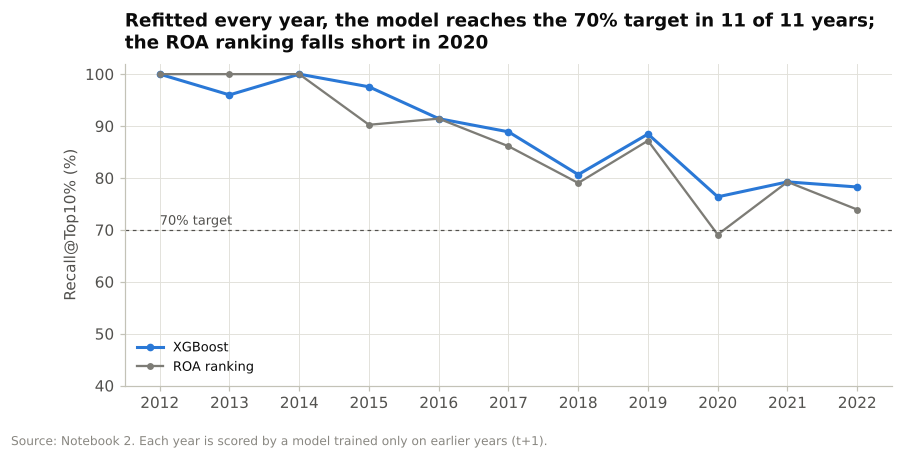

,year scored,ST cases,model,ROA ranking,caught by model,caught by ROA,model PR-AUC,ROA PR-AUC
0,2012,18,1.000,1.000,18,18,0.954,0.351
1,2013,25,0.960,1.000,24,25,0.620,0.292
2,2014,27,1.000,1.000,27,27,0.813,0.588
3,2015,41,0.976,0.902,40,37,0.722,0.253
4,2016,35,0.914,0.914,32,32,0.813,0.408
5,2017,36,0.889,0.861,32,31,0.729,0.325
6,2018,62,0.806,0.790,50,49,0.516,0.191
7,2019,78,0.885,0.872,69,68,0.597,0.385
8,2020,55,0.764,0.691,42,38,0.205,0.134
9,2021,53,0.792,0.792,42,42,0.266,0.185


In [75]:
# c. walk-forward: refit on every year before y, score year y
walk = []
t0 = time.time()
for yr in range(2012, 2023):
    past, now = part(TARGET, years=(2001, yr - 1)), part(TARGET, years=(yr, yr))
    s = clone(base_pipe).fit(X(past), past[TARGET]).predict_proba(X(now))[:, 1]
    roa_now = baseline_scores(now)["ROA ranking"]
    walk.append({"year scored": yr, "ST cases": int(now[TARGET].sum()), "model": recall_at_top(now, s, TARGET),
                 "ROA ranking": recall_at_top(now, roa_now, TARGET),
                 "caught by model": int((top_share_flags(now, s) * now[TARGET]).sum()),
                 "caught by ROA": int((top_share_flags(now, roa_now) * now[TARGET]).sum()),
                 "model PR-AUC": average_precision_score(now[TARGET], s),
                 "ROA PR-AUC": average_precision_score(now[TARGET], roa_now)})
walk = pd.DataFrame(walk)
print(f"Walk-forward refits: {time.time() - t0:.0f} s; model ahead of the ROA ranking on Recall@Top10% in "
      f"{(walk['model'] > walk['ROA ranking']).sum()} of {len(walk)} years, and on PR-AUC in "
      f"{(walk['model PR-AUC'] > walk['ROA PR-AUC']).sum()} of {len(walk)}")
TEST_YEARS = tuple(lists["split_years"]["test"])   # (2020, 2022)
tw = walk[walk["year scored"].between(*TEST_YEARS)]
walk_test_model, walk_test_roa = tw["caught by model"].sum() / tw["ST cases"].sum(), tw["caught by ROA"].sum() / tw["ST cases"].sum()
print(f"Test years {TEST_YEARS[0]}-{TEST_YEARS[1]} pooled, refitted every year: model {walk_test_model:.1%}, "
      f"ROA ranking {walk_test_roa:.1%} of {int(tw['ST cases'].sum())} cases")

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(walk["year scored"], 100 * walk["model"], color=ACCENT, linewidth=2, marker="o", markersize=4, label=CHOSEN)
ax.plot(walk["year scored"], 100 * walk["ROA ranking"], color=DARKGREY, linewidth=1.5, marker="o", markersize=3.5, label="ROA ranking")
ax.axhline(100 * TARGET_RECALL, color=INK2, linewidth=0.8, linestyle=(0, (3, 3)))
ax.text(2012, 100 * TARGET_RECALL + 1, "70% target", fontsize=8.5, color=INK2)
ax.set_ylim(40, 102); ax.set_ylabel("Recall@Top10% (%)"); ax.set_xticks(walk["year scored"])
ax.legend(loc="lower left", fontsize=8.5)
n_ok = int((walk["model"] >= TARGET_RECALL).sum())
roa_short = walk.loc[walk["ROA ranking"] < TARGET_RECALL, "year scored"].astype(str).tolist()
ax.set_title(f"Refitted every year, the model reaches the 70% target in {n_ok} of {len(walk)} years"
             + (f";\nthe ROA ranking falls short in {', '.join(roa_short)}" if roa_short else ""))
save(fig, "fig18_walk_forward", "Source: Notebook 2. Each year is scored by a model trained only on earlier years (t+1).")
walk.round(3)

Brier score 0.0328 (always predicting the average rate would score 0.0117); average score 0.042 vs actual ST rate 0.012


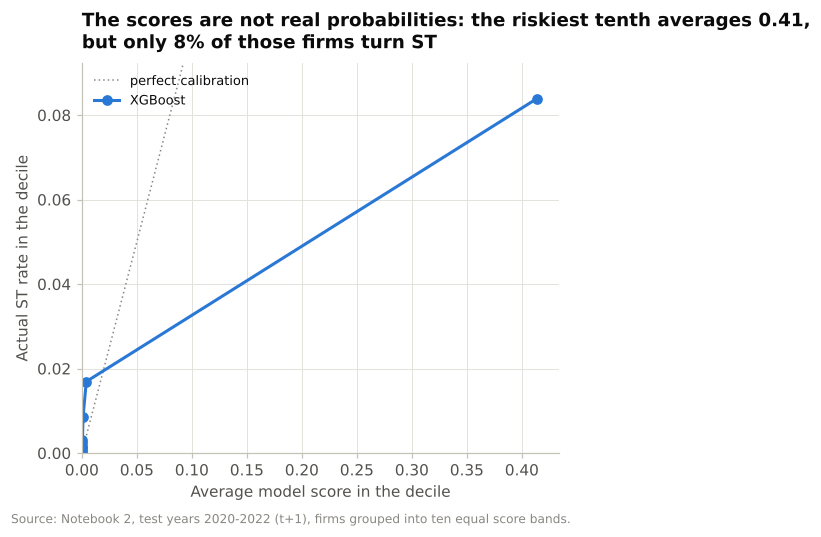

,firms,mean_score,actual_rate
decile,,,
1,1300,0.0000,0.0000
2,1300,0.0001,0.0023
3,1299,0.0001,0.0000
4,1300,0.0002,0.0015
5,1300,0.0003,0.0008
6,1299,0.0004,0.0015
7,1300,0.0006,0.0031
8,1299,0.0011,0.0085
9,1300,0.0041,0.0169


In [76]:
# g. calibration: do the scores match real rates?
cal = pd.DataFrame({"score": test_scores[CHOSEN], "y": y_test})
cal["decile"] = pd.qcut(cal["score"].rank(method="first"), 10, labels=range(1, 11))
cal_table = cal.groupby("decile", observed=True).agg(firms=("y", "size"), mean_score=("score", "mean"), actual_rate=("y", "mean"))
brier = brier_score_loss(y_test, test_scores[CHOSEN])
print(f"Brier score {brier:.4f} (always predicting the average rate would score {brier_score_loss(y_test, np.full(len(y_test), y_test.mean())):.4f}); "
      f"average score {cal['score'].mean():.3f} vs actual ST rate {y_test.mean():.3f}")

fig, ax = plt.subplots(figsize=(5.6, 4.6))
ax.plot([0, 1], [0, 1], color=MUTED, linewidth=1, linestyle=(0, (1, 2)), label="perfect calibration")
ax.plot(cal_table["mean_score"], cal_table["actual_rate"], color=ACCENT, marker="o", linewidth=2, label=CHOSEN)
ax.set_xlabel("Average model score in the decile"); ax.set_ylabel("Actual ST rate in the decile")
ax.set_xlim(0, max(1e-3, cal_table["mean_score"].max()) * 1.05); ax.set_ylim(0, max(cal_table["actual_rate"].max(), 0.05) * 1.1)
ax.legend(fontsize=8.5, loc="upper left")
top_dec = cal_table.iloc[-1]
ax.set_title(f"The scores are not real probabilities: the riskiest tenth averages {top_dec.mean_score:.2f},\n"
             f"but only {top_dec.actual_rate:.0%} of those firms turn ST"
             if abs(top_dec.mean_score - top_dec.actual_rate) > 0.5 * top_dec.actual_rate else
             "The scores are close to real rates, even in the riskiest tenth")
save(fig, "fig19_calibration_test", "Source: Notebook 2, test years 2020-2022 (t+1), firms grouped into ten equal score bands.")
cal_table.round(4)

**What the result shows.** | Check | Result | What it tells us |
|---|---|---|
| a. Random 80/20 split | Recall@Top10% 88.9%, PR-AUC 0.621 | Shuffling the years makes the model look far better than the honest time split (70.1% and 0.153 on the test years), because a random test is full of easy early-year cases. The time split is the right one. |
| b. Shuffled labels | 7.9%, PR-AUC 0.021 | Chance level, as it should be: the pipeline does not invent signal. |
| c. Refit every year (walk-forward, 2012-2022) | At least 70% in all 11 years; ahead of the ROA ranking in 6 years, level in 4, behind in 1; higher PR-AUC in all 11. Test years pooled: 77.9% against 74.0% of 154 cases | Refitted on all earlier years before scoring each year, as it would be in use, the model clears the target every year and catches more than the ROA ranking in the test years. Frozen at 2017 (section 10), it loses ground as the market changes, so the yearly refit matters. |
| d. Without the three loss flags | test 72.7%, PR-AUC 0.159 | No worse than with them (70.1%, 0.153): ROA and the other ratios carry the same information, so the flags are not essential. |
| e. ST firms without two straight losses (73 test cases) | model 37.0%, ROA ranking 54.8% | The model is weaker than the ROA ranking on the less obvious cases. It learned from 2001-2017, when 80% of the cases had two losses in a row; in the test years only about half did. This is the main reason the ROA ranking catches more at a 10% list in section 10. |
| f. `listing_board` as an input | validation 84.3%, test 72.1% | A small, mixed change (0.7 points lower on validation, 2.0 points higher on the test), so leaving it out (Notebook 1, decision 3) costs little. |
| g. Calibration | average score 0.042 against a real rate of 0.012; riskiest tenth 0.41 against 8.4%; Brier score 0.0328, worse than always predicting the average rate (0.0117) | The scores rank well but are not chances: they overstate the risk at the top and understate it just below. Use them to rank, and calibrate them on the validation years before quoting any score as a probability. |

**Overall.** The time split, the shuffled labels and the walk-forward support the result. Checks d and e show the model leans on the loss pattern of the early years, which is why it should be refitted every year and why the ROA ranking stays as the benchmark.

## 14. The t+2 model

**What and why.** t+2 is a separate question with its own model, not "ST at any time within two years". The t+2 target is `ST_next2` = ST at the end of year t+2, whatever happened in t+1. We reuse each family's tuned settings from step 8 (re-tuning would double the run time for little gain; the team can switch it on by repeating step 8 with `TARGET = "ST_next2"`), train on 2001-2016 because of the one-year purge gap (6.3), choose on the validation years with the same rule as 9.1, and test once on 2020-2022 (t+2 outcomes 2022-2024). Two years ahead is harder, so lower numbers are expected; Objective 1's 70% target is set for next-year cases only.

In [77]:
T2 = "ST_next2"
TRAIN_END = lists["split_years"]["train"][1]
train2 = part(T2, years=(2001, TRAIN_END - T2_PURGE_YEARS))
valid2, test2 = part(T2, "validation"), part(T2, "test")
spw2 = (1 - train2[T2].mean()) / train2[T2].mean()
print(f"t+2 model: train {train2.year.min()}-{train2.year.max()} ({len(train2):,} rows, {train2[T2].sum()} cases) | "
      f"validation {len(valid2):,} ({valid2[T2].sum()}) | test {len(test2):,} ({test2[T2].sum()})")

def retarget(pipe, spw_new):
    p = clone(pipe)
    if isinstance(p.named_steps["model"], XGBClassifier) and p.named_steps["model"].get_params()["scale_pos_weight"] > 1:
        p.set_params(model__scale_pos_weight=spw_new)   # weights were chosen: recompute them for the new rows
    return p

tuned2 = {name: retarget(m, spw2).fit(X(train2), train2[T2]) for name, m in tuned.items()}
val2_scores = {name: m.predict_proba(X(valid2))[:, 1] for name, m in tuned2.items()}
comparison_val2 = pd.DataFrame({n: report(valid2, s, T2) for n, s in val2_scores.items()}).T
best2 = comparison_val2["Recall@Top10%"].max()
CHOSEN2 = comparison_val2[comparison_val2["Recall@Top10%"] >= best2 - TIE_MARGIN]["PR-AUC"].idxmax()
comparison_val2 = pd.concat([comparison_val2, pd.DataFrame({n: report(valid2, s, T2) for n, s in baseline_scores(valid2).items()}).T])

y_val2, s_val2 = valid2[T2].to_numpy(), val2_scores[CHOSEN2]
f1s = [f1_score(y_val2, s_val2 >= t, zero_division=0) for t in grid]
BEST_THRESHOLD2 = float(grid[int(np.argmax(f1s))])
print(f"Chosen t+2 model: {CHOSEN2}; best-F1 cut-off on validation {BEST_THRESHOLD2:.2f}\n")
comparison_val2.round(3)

t+2 model: train 2001-2016 (25,509 rows, 690 cases) | validation 6,801 (210) | test 12,962 (247)


Chosen t+2 model: Random forest; best-F1 cut-off on validation 0.23



,Recall@Top10%,Precision@Top10%,Recall@Top5%,PR-AUC,ROC-AUC
Logistic regression,0.662,0.204,0.452,0.297,0.881
Decision tree,0.671,0.207,0.414,0.237,0.835
Random forest,0.671,0.207,0.495,0.311,0.894
XGBoost,0.671,0.207,0.481,0.309,0.894
Neural network (MLP),0.643,0.198,0.400,0.230,0.864
Random order,0.129,0.040,0.067,0.036,0.529
Loss-history rule,0.510,0.157,0.281,0.133,0.777
ROA ranking,0.648,0.200,0.395,0.225,0.855


In [78]:
test2_scores = {name: m.predict_proba(X(test2))[:, 1] for name, m in tuned2.items()}
test2_scores.update(baseline_scores(test2))
comparison_test2 = pd.DataFrame({n: report(test2, s, T2, BEST_THRESHOLD2 if n == CHOSEN2 else None)
                                 for n, s in test2_scores.items()}).T
comparison_test2["chosen"] = np.where(comparison_test2.index == CHOSEN2, "<- chosen", "")
boot2 = bootstrap_recalls(test2, [test2_scores[CHOSEN2], test2_scores["ROA ranking"]], T2)
r10_2, r10_2_roa = comparison_test2.loc[CHOSEN2, "Recall@Top10%"], comparison_test2.loc["ROA ranking", "Recall@Top10%"]
ci2 = np.percentile(boot2[:, 0], [2.5, 97.5])
print(f"t+2 test (2020-2022 accounts, outcomes 2022-2024), {CHOSEN2}: Recall@Top10% {r10_2:.1%} "
      f"(95% interval {ci2[0]:.1%} to {ci2[1]:.1%}); ROA ranking {r10_2_roa:.1%}; model ahead in {np.mean(boot2[:, 0] > boot2[:, 1]):.0%} of resamples")
expect_text("Chosen t+2 model (full run)", CHOSEN2, "Random forest")
expect("t+2 test Recall@Top10%, chosen model (full run)", r10_2, 148 / 247, tol=1e-9)

# robustness: the same model without the purge gap (trained on 2001-2017)
nopurge = part(T2, "train")
m_np = retarget(tuned2[CHOSEN2], (1 - nopurge[T2].mean()) / nopurge[T2].mean()).fit(X(nopurge), nopurge[T2])
for nm, d in [("validation", valid2), ("test", test2)]:
    s = m_np.predict_proba(X(d))[:, 1]
    print(f"  without the purge gap (train 2001-2017), {nm}: Recall@Top10% {recall_at_top(d, s, T2):.1%}, "
          f"PR-AUC {average_precision_score(d[T2], s):.3f}")
print()
comparison_test2.round(3)

t+2 test (2020-2022 accounts, outcomes 2022-2024), Random forest: Recall@Top10% 59.9% (95% interval 53.5% to 66.2%); ROA ranking 54.7%; model ahead in 100% of resamples
PASS  | Chosen t+2 model (full run): Random forest (expected Random forest)
PASS  | t+2 test Recall@Top10%, chosen model (full run): 0.599 (expected 0.599)


  without the purge gap (train 2001-2017), validation: Recall@Top10% 68.1%, PR-AUC 0.319
  without the purge gap (train 2001-2017), test: Recall@Top10% 59.1%, PR-AUC 0.174



,Recall@Top10%,Precision@Top10%,Recall@Top5%,PR-AUC,ROC-AUC,Recall,Precision,F1,Balanced accuracy,Flagged %,chosen
Logistic regression,0.615,0.117,0.433,0.173,0.863,NaN,NaN,NaN,NaN,NaN,
Decision tree,0.595,0.113,0.401,0.116,0.822,NaN,NaN,NaN,NaN,NaN,
Random forest,0.599,0.114,0.437,0.171,0.868,0.381,0.2,0.263,0.676,3.618,<- chosen
XGBoost,0.551,0.105,0.385,0.152,0.860,NaN,NaN,NaN,NaN,NaN,
Neural network (MLP),0.522,0.099,0.304,0.090,0.830,NaN,NaN,NaN,NaN,NaN,
Random order,0.121,0.023,0.057,0.020,0.500,NaN,NaN,NaN,NaN,NaN,
Loss-history rule,0.538,0.102,0.271,0.080,0.784,NaN,NaN,NaN,NaN,NaN,
ROA ranking,0.547,0.104,0.389,0.132,0.850,NaN,NaN,NaN,NaN,NaN,


**What the result shows.** **The choice.** On the validation years (2018-2019 accounts, outcomes 2020-2021) four models came within 0.02 of the best Recall@Top10%: the decision tree, the random forest and XGBoost (all 67.1%) and the logistic regression (66.2%). Of these the random forest has the highest PR-AUC (0.311), so by the rule in 9.1 **the random forest is the t+2 model**, with a best-F1 cut-off of 0.23. On validation every model is only a little ahead of the ROA ranking (64.8%).

**The test, once (2020-2022 accounts, outcomes 2022-2024).** The random forest puts 148 of the 247 t+2 cases inside its top 10%: **59.9%** (95% interval 53.5% to 66.2%).
- That is below the 70% set for next-year cases, as expected one year further out; Objective 1 is set for t+1 only.
- It is ahead of the ROA ranking (54.7%, 135 cases) in over 99% of the resamples, and ahead of the loss-history rule (53.8%). Its list is also cleaner: PR-AUC 0.171 against 0.132, and 43.7% of the cases inside the top 5% against 38.9%. Unlike t+1, the model beats the one-column rule here; a likely reason is that two years out no single ratio says enough on its own.
- The logistic regression would have caught slightly more on the test (61.5%) and XGBoost less (55.1%). The choice was made on validation and stays.

**The yes/no cut-off.** At 0.23 the forest flags 3.6% of the test firms and catches 38.1% of the cases, with 20.0% of its flags right.

**The purge gap costs nothing.** The same model trained on 2001-2017 without the gap scores 59.1% on the test (PR-AUC 0.174), no better than with it (59.9%, 0.171). The gap keeps the test honest (6.3) at no cost in accuracy.

**What this means.** The t+2 list is an earlier, rougher warning that sits beside the t+1 list rather than replacing it: it catches about 6 in 10 of the firms that will be ST two years later. Re-tuning on the t+2 target (step 8 with `TARGET = "ST_next2"`) is the first thing to try to raise it.

## 15. The 2023 check, the 2025 forward check and the watch-list (Objective 3)

### 15.1 Refit on everything known, then check on later years

**What and why.** A deployed model is refitted on all years whose outcomes are known, with the settings chosen above. We imitate that twice, each time scoring a year the refitted model has not seen:
- **2023 check (t+1):** refit on 2001-2022, score the 2023 accounts, compare with the 2024 status (refreshed from CNINFO).
- **2025 forward check (t+1):** refit on 2001-2023, score the 2024 accounts, compare with the 2025 status. This is exactly the watch-list a credit team would have received for 2025. The 2025 status has no documented source, so this check is **provisional**.
- **2025 forward check (t+2):** refit on 2001-2021 (purge gap), score the 2023 accounts, compare with the 2025 status. Also provisional.

Each check reports Recall@Top10% with its 95% interval, next to the ROA ranking. Every firm of the year is ranked, as it would be in real use; a firm whose later status is unknown (for example it left the market) keeps its place on the list but does not count as a case. The same rule is used when MySQL recomputes these numbers (`04_olap_queries.sql`, Q4d).

In [79]:
def refit(target, last_year, pipe):
    past = part(target, years=(2001, last_year))
    return retarget(pipe, (1 - past[target].mean()) / past[target].mean()).fit(X(past), past[target])

year_rows = lambda yr: data[data["year"] == yr].reset_index(drop=True)      # every normal firm of that year
prod_t1_2022 = refit(TARGET, 2022, tuned[CHOSEN])
prod_t1_2023 = refit(TARGET, 2023, tuned[CHOSEN])
prod_t2_2021 = refit(T2, 2021, tuned2[CHOSEN2])
prod_t2_2022 = refit(T2, 2022, tuned2[CHOSEN2])

rows_2023, rows_2024 = year_rows(2023), year_rows(2024)
score_t1_2023 = prod_t1_2022.predict_proba(X(rows_2023))[:, 1]
score_t1_2024 = prod_t1_2023.predict_proba(X(rows_2024))[:, 1]
score_t2_2023 = prod_t2_2021.predict_proba(X(rows_2023))[:, 1]
score_t2_2024 = prod_t2_2022.predict_proba(X(rows_2024))[:, 1]

checks = []
for label, rows, score, target, note in [
        ("2023 accounts -> 2024 status (t+1)", rows_2023, score_t1_2023, TARGET, "refit 2001-2022"),
        ("2024 accounts -> 2025 status (t+1)", rows_2024, score_t1_2024, TARGET, "refit 2001-2023; provisional"),
        ("2023 accounts -> 2025 status (t+2)", rows_2023, score_t2_2023, T2, "refit 2001-2021; provisional")]:
    # Every firm of the year is ranked, as in real use. A firm whose later status is unknown keeps its place
    # on the list but is not counted as a case; PR-AUC uses the firms whose outcome is known.
    known = rows[target].notna().to_numpy()
    d = rows.assign(**{target: rows[target].fillna(0).astype(int)})
    roa = baseline_scores(rows)["ROA ranking"]
    flags = top_share_flags(rows, score)
    b = bootstrap_recalls(d, [score, roa], target)
    lo, hi = np.percentile(b[:, 0], [2.5, 97.5])
    checks.append({"check": label, "model": note, "firms ranked": len(rows), "outcome known": int(known.sum()),
                   "ST cases": int(d[target].sum()), "Recall@Top10%": recall_at_top(d, score, target),
                   "95% interval": f"{lo:.2f}-{hi:.2f}", "ROA ranking": recall_at_top(d, roa, target),
                   "model ahead of ROA in % of resamples": round(100 * np.mean(b[:, 0] > b[:, 1])),
                   "Precision@Top10%": d[target].to_numpy()[(flags == 1) & known].mean(),
                   "Recall@Top5%": recall_at_top(d, score, target, 0.05),
                   "PR-AUC": average_precision_score(rows.loc[known, target], score[known]),
                   "ROA PR-AUC": average_precision_score(rows.loc[known, target], roa[known])})
forward = pd.DataFrame(checks)
expect("2023 accounts -> 2024 status, Recall@Top10% (full run)", forward.loc[0, "Recall@Top10%"], 58 / 92, tol=1e-9)
expect("2024 accounts -> 2025 status, Recall@Top10% (full run)", forward.loc[1, "Recall@Top10%"], 76 / 115, tol=1e-9)
forward.round(3)

PASS  | 2023 accounts -> 2024 status, Recall@Top10% (full run): 0.630 (expected 0.630)
PASS  | 2024 accounts -> 2025 status, Recall@Top10% (full run): 0.661 (expected 0.661)


,check,model,firms ranked,outcome known,ST cases,Recall@Top10%,95% interval,ROA ranking,model ahead of ROA in % of resamples,Precision@Top10%,Recall@Top5%,PR-AUC,ROA PR-AUC
0,2023 accounts -> 2024 status (t+1),refit 2001-2022,5084,5082,92,0.630,0.53-0.72,0.543,97,0.114,0.489,0.264,0.178
1,2024 accounts -> 2025 status (t+1),refit 2001-2023; provisional,5017,5016,115,0.661,0.58-0.74,0.609,86,0.151,0.461,0.271,0.204
2,2023 accounts -> 2025 status (t+2),refit 2001-2021; provisional,5084,5052,144,0.549,0.46-0.63,0.535,53,0.163,0.396,0.234,0.144


### 15.2 The 2024 watch-list, with the main reasons for each firm

**What and why.** Objective 3 asks for an annually updated, ranked list of about 10% of firms. The list below ranks every normal non-financial firm of 2024 with the refitted t+1 model and keeps the top 10% (the High band). A list is only useful if an analyst can see *why* a firm is on it. For each firm we ask, family by family: *how much would its risk score fall if this family looked like a typical healthy firm's?* The three families with the biggest fall are its **main reasons**. "Typical healthy" means the median (or most common value) among firms that stayed normal in 2001-2023. These what-if reasons are a plain-language guide, not an exact split of the score: families interact, so the falls do not add up to the total.

The firm names are not in this table; `sql/04_olap_queries.sql` Q4a joins them from `dim_firm` once the scores are loaded into MySQL. ROA and leverage are shown as the model sees them, after Notebook 1's caps (8.2): leverage is capped at 0.89 and ROA at -0.17, so a firm whose debts exceed its assets shows leverage 0.89 with `NegEquity` = 1.

In [80]:
normal_ref = part(TARGET, years=(2001, 2023))
normal_ref = normal_ref[normal_ref[TARGET] == 0]
TYPICAL = {c: float(normal_ref[c].median()) for c in NUMERIC}
TYPICAL.update({c: normal_ref[c].mode().iloc[0] for c in BINARY + CATEGORICAL})
TYPICAL = {k: (v.item() if hasattr(v, "item") else v) for k, v in TYPICAL.items()}

def family_reasons(model, df):
    """Fall in the risk score when each family is set to typical healthy values (higher = stronger reason)."""
    base = model.predict_proba(X(df))[:, 1]
    out = pd.DataFrame(index=df.index)
    for fam, members in FAMILIES.items():
        what_if = df.copy()
        for c in members:
            what_if[c] = TYPICAL[c]
        out[fam] = base - model.predict_proba(X(what_if))[:, 1]
    return out

latest = rows_2024.copy()
latest["risk_score"] = score_t1_2024
latest["risk_rank"] = year_rank(latest, score_t1_2024)
latest["risk_band"] = band(latest, score_t1_2024)
latest["t2_rank_for_2026"] = year_rank(latest, score_t2_2024)
watch = latest[latest["risk_band"] == "High"].sort_values("risk_rank").copy()
contrib = family_reasons(prod_t1_2023, watch)
top3 = contrib.apply(lambda r: [f for f in r.sort_values(ascending=False).index[:3] if r[f] > 0.005], axis=1)
for i in range(3):
    watch[f"reason {i + 1}"] = top3.apply(lambda lst: lst[i] if len(lst) > i else "")
watch["stock_code"] = watch["stkcd"].astype(int).astype(str).str.zfill(6)
watch["ST in 2025 (provisional)"] = watch["ST_next1"].map({1.0: "yes", 0.0: "no"}).fillna("unknown")
for c in ["Loss", "Loss_2yr", "NegEquity"]:
    watch[c] = watch[c].round().astype("Int64")
cols_out = ["risk_rank", "stock_code", "Industry", "region", "listing_board", "risk_score", "reason 1", "reason 2",
            "reason 3", "Loss", "Loss_2yr", "ROA", "Lev", "NegEquity", "t2_rank_for_2026", "ST in 2025 (provisional)"]
watch[cols_out].to_csv(OUT_DIR / "watchlist_2024.csv", index=False, float_format="%.4f")
expect("Firms on the 2024 watch-list (10% of the year, rounded up)", len(watch), int(np.ceil(WATCHLIST_SHARE * len(latest))))
print(f"2024 firms scored: {len(latest):,}; on the watch-list: {len(watch)}; with two straight losses: "
      f"{watch['Loss_2yr'].eq(1).mean():.0%}; profitable in 2024: {watch['Loss'].eq(0).mean():.0%}; "
      f"also in the t+2 top 10%: {(watch['t2_rank_for_2026'] <= np.ceil(WATCHLIST_SHARE * len(latest))).mean():.0%}")
watch[cols_out].head(15).round(3)

PASS  | Firms on the 2024 watch-list (10% of the year, rounded up): 502 (expected 502)
2024 firms scored: 5,017; on the watch-list: 502; with two straight losses: 86%; profitable in 2024: 2%; also in the t+2 top 10%: 70%


[Output removed in this repository: it shows firm-level rows from the ZxData dataset, which is licensed for academic use only. Run the notebook with your own copy of the data to see it.]


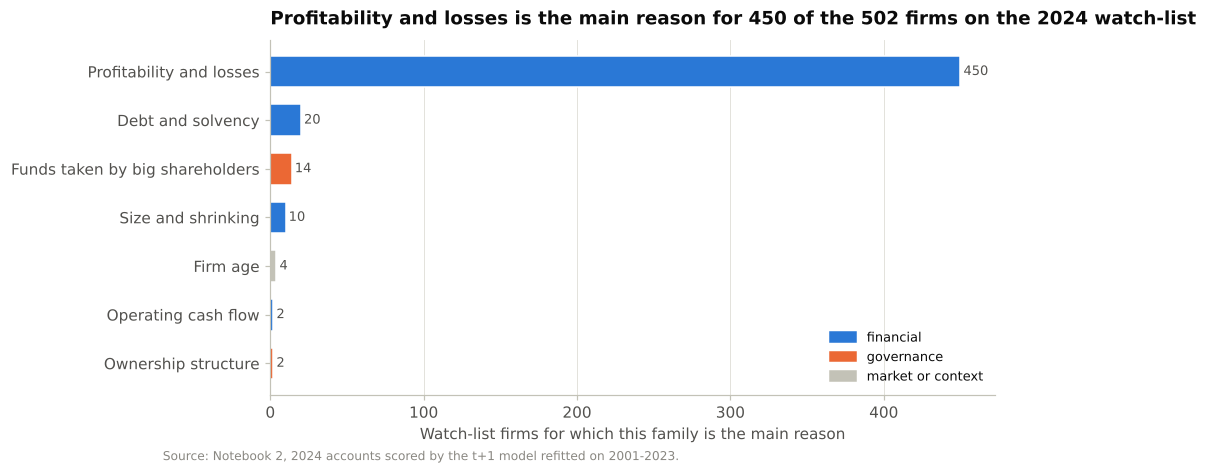

In [81]:
first = watch["reason 1"].replace("", "No single family stands out").value_counts()   # blank = no what-if drop above 0.005
fig, ax = plt.subplots(figsize=(8.5, 4.2))
shown = first.sort_values()
ax.barh(shown.index, shown.values, color=[TYPE_COLOR[FAMILY_TYPE[f]] if f in FAMILY_TYPE else MUTED for f in shown.index], height=0.65, edgecolor="white")
for yy, v in enumerate(shown.values):
    ax.text(v + 2, yy, f"{v}", va="center", fontsize=8.5, color=INK2)
ax.set_xlabel("Watch-list firms for which this family is the main reason")
ax.grid(axis="y", visible=False)
ax.legend(handles=[Patch(color=ACCENT, label="financial"), Patch(color=SECOND, label="governance"),
                   Patch(color=CONTEXT, label="market or context")], loc="lower right", fontsize=8.5)
ax.set_title(f"{first.index[0]} is the main reason for {first.iloc[0]} of the {len(watch)} firms on the 2024 watch-list")
save(fig, "fig20_watchlist_reasons", "Source: Notebook 2, 2024 accounts scored by the t+1 model refitted on 2001-2023.")

**What the result shows.** **The later-year checks.** Each refitted model scores a year it has never seen:

| Check | ST cases | Model: Recall@Top10% (95% interval) | ROA ranking | Model ahead of ROA, share of resamples | PR-AUC: model, ROA |
|---|---|---|---|---|---|
| 2023 accounts, 2024 status (t+1, refit 2001-2022) | 92 | 63.0% (53% to 72%) | 54.3% | 97% | 0.264, 0.178 |
| 2024 accounts, 2025 status (t+1, refit 2001-2023), provisional | 115 | 66.1% (58% to 74%) | 60.9% | 86% | 0.271, 0.204 |
| 2023 accounts, 2025 status (t+2, refit 2001-2021), provisional | 144 | 54.9% (46% to 63%) | 53.5% | 53% | 0.234, 0.144 |

- **Below the 70% target, but ahead of the ROA ranking.** The refitted t+1 model catches 58 of the 92 cases of 2024 and 76 of the 115 cases of 2025; the ROA ranking catches 50 and 70. Both intervals still reach 70%, so the target is within reach in these years but not shown. The ROA ranking was ahead on the test years (section 10); the model is ahead here, as in the walk-forward check (13c), because a model refitted every year keeps up with the market and a model frozen at 2017 does not.
- **The t+2 check** catches about as many cases as the ROA ranking (79 against 77 of 144), with a cleaner list (PR-AUC 0.234 against 0.144).
- **Both 2025 checks are provisional.** The 2025 status has no documented source, so it is used here only and kept out of MySQL (`actual_flag` is left blank for those rows) until the team confirms it.

**The 2024 watch-list (Objective 3).** The refitted t+1 model ranks all 5,017 normal non-financial firms of 2024 and keeps the riskiest 502 (10%, rounded up) in `outputs/watchlist_2024.csv`, with up to three main reasons for each firm.
- **Nearly all are loss-makers:** 98% made a loss in 2024 and 86% made two losses in a row.
- **Profitability is the main reason for 450 of the 502 firms** (chart above). For the others the main reason is debt and solvency (20), funds taken by big shareholders (14), size and shrinking (10), firm age (4), operating cash flow (2) or ownership structure (2). Five firms show fewer than three reasons, because no other family would lower their score by more than 0.005.
- **The list worked in 2025 (provisional):** 76 of the 502 firms turned ST in 2025 (15%, about 1 in 7, against 2.3% of all firms), and those 76 are two thirds of the year's 115 cases.
- **Most stay at risk two years out:** 70% of the list is also in the t+2 model's top 10% for 2026.
- **160 of the 502 firms have no governance data for 2024** (Notebook 1, 3.3). Ownership, board and pay reasons almost never appear for them (14 of 160), because their figures are missing and were filled in with typical values. 30 of the 160 turned ST in 2025 (19%, against 13% for the rest of the list; provisional).
- **Reading the values:** ROA and leverage are shown after Notebook 1's caps, so -0.174 and 0.893 mean "at or beyond the cap" (82 and 70 firms). Q4a in `04_olap_queries.sql` adds the firm names from `dim_firm`.

**Each year**, `deployment/batch_score.py --year <new year>` scores the newest accounts with the active models and writes the new list in the same shape. Once that year's ST status is confirmed, re-running Notebooks 1 and 2 refits the models on one more year.

## 16. Save the models, the scores for MySQL and the model card

### 16.1 Models and scores

**What and why.** Four fitted pipelines are saved with everything the deployment script needs (input lists, cut-off, list share, the "typical healthy" values for the reasons): the two evaluation models (t+1 and t+2, as tested) and the two active models refitted on all known years, which score the 2024 accounts. The scores go to `risk_scores_for_mysql.csv` in the exact shape of `fact_risk_score`, and one row per model version goes to `dim_model_rows.csv`; `v2_star/sql/04_load_risk_scores.sql` loads both. The provisional 2025 status is written as blank unless `USE_2025_STATUS = True`.


In [82]:
created = time.strftime("%Y-%m-%d")

def weighting_text(pipe):
    """Which imbalance fix the search picked for this pipeline (section 8)."""
    m = pipe.named_steps["model"]
    if "oversample" in pipe.named_steps:
        return "no imbalance fix" if pipe.named_steps["oversample"] == "passthrough" else "random over-sampling"
    if isinstance(m, XGBClassifier):
        return "class weights" if m.get_params()["scale_pos_weight"] > 1 else "no imbalance fix"
    return "no imbalance fix" if m.get_params().get("class_weight") is None else "class weights"

def settings_text(name):
    p = tuned[name].named_steps["model"].get_params()
    keep = {"Logistic regression": ["penalty", "C"], "Decision tree": ["max_depth", "min_samples_leaf", "ccp_alpha"],
            "Random forest": ["n_estimators", "max_depth", "min_samples_leaf", "max_features"],
            "XGBoost": ["n_estimators", "learning_rate", "max_depth"], "Neural network (MLP)": ["hidden_layer_sizes", "alpha"]}[name]
    return ", ".join(f"{k}={round(p[k], 4) if isinstance(p[k], float) else p[k]}" for k in keep)

def bundle(model, target, train_years, threshold, version, algorithm, active):
    return {"model": model, "target": target, "features": FEATURES, "id_columns": ID_KEEP, "numeric": NUMERIC,
            "binary": BINARY, "categorical": CATEGORICAL, "families": FAMILIES, "family_type": FAMILY_TYPE,
            "typical_values": TYPICAL, "train_years": train_years, "decision_threshold": threshold,
            "watchlist_share": WATCHLIST_SHARE, "medium_share": MEDIUM_SHARE, "version": version,
            "algorithm": algorithm, "is_active": active, "created": created,
            "library_versions": {"scikit-learn": sklearn.__version__, "xgboost": xgboost.__version__,
                                 "imbalanced-learn": imblearn.__version__}}

saved = {
    f"st_t1_{MODEL_VERSION}-eval": bundle(tuned[CHOSEN], TARGET, "2001-2017", BEST_THRESHOLD, f"{MODEL_VERSION}-eval", CHOSEN, 0),
    f"st_t1_{MODEL_VERSION}-2023": bundle(prod_t1_2023, TARGET, "2001-2023", BEST_THRESHOLD, f"{MODEL_VERSION}-2023", CHOSEN, 1),
    f"st_t2_{MODEL_VERSION}-eval": bundle(tuned2[CHOSEN2], T2, f"2001-{TRAIN_END - T2_PURGE_YEARS}", BEST_THRESHOLD2, f"{MODEL_VERSION}-eval", CHOSEN2, 0),
    f"st_t2_{MODEL_VERSION}-2022": bundle(prod_t2_2022, T2, "2001-2022", BEST_THRESHOLD2, f"{MODEL_VERSION}-2022", CHOSEN2, 1),
}
for name, b in saved.items():
    joblib.dump(b, MODEL_DIR / f"{name}.joblib", compress=3)
    print(f"saved models/{name}.joblib  {(MODEL_DIR / f'{name}.joblib').stat().st_size / 1e6:6.1f} MB")

def score_rows(df, score, offset, model_name, version, threshold, actual):
    out = pd.DataFrame({"stkcd": df["stkcd"].astype(int).to_numpy(), "feature_year": df["year"].astype(int).to_numpy(),
                        "target_year": df["year"].astype(int).to_numpy() + offset, "model_name": model_name,
                        "model_version": version, "risk_score": np.round(np.asarray(score), 6),
                        "predicted_flag": (np.asarray(score) >= threshold).astype(int),
                        "risk_rank": year_rank(df, score), "risk_band": band(df, score)})
    out["actual_flag"] = pd.array(actual, dtype="Int64") if actual is not None else pd.array([pd.NA] * len(df), dtype="Int64")
    return out

vt1, vt2 = pd.concat([valid, test], ignore_index=True), pd.concat([valid2, test2], ignore_index=True)
use25 = lambda col: col if USE_2025_STATUS else None
scores_out = pd.concat([
    score_rows(vt1, tuned[CHOSEN].predict_proba(X(vt1))[:, 1], 1, "st_t1", f"{MODEL_VERSION}-eval", BEST_THRESHOLD, vt1[TARGET]),
    score_rows(rows_2023, score_t1_2023, 1, "st_t1", f"{MODEL_VERSION}-2022", BEST_THRESHOLD, rows_2023[TARGET]),
    score_rows(rows_2024, score_t1_2024, 1, "st_t1", f"{MODEL_VERSION}-2023", BEST_THRESHOLD, use25(rows_2024[TARGET])),
    score_rows(vt2, tuned2[CHOSEN2].predict_proba(X(vt2))[:, 1], 2, "st_t2", f"{MODEL_VERSION}-eval", BEST_THRESHOLD2, vt2[T2]),
    score_rows(rows_2023, score_t2_2023, 2, "st_t2", f"{MODEL_VERSION}-2021", BEST_THRESHOLD2, use25(rows_2023[T2])),
    score_rows(rows_2024, score_t2_2024, 2, "st_t2", f"{MODEL_VERSION}-2022", BEST_THRESHOLD2, None),
], ignore_index=True)
scores_out.to_csv(OUT_DIR / "risk_scores_for_mysql.csv", index=False)
expect("Duplicate (firm, feature year, model version) rows in the scores file",
       int(scores_out.duplicated(["stkcd", "feature_year", "model_name", "model_version"]).sum()), 0)
print(scores_out.groupby(["model_name", "model_version"]).agg(rows=("stkcd", "size"), years=("feature_year", lambda s: f"{s.min()}-{s.max()}"),
                                                           high_band=("risk_band", lambda s: int((s == "High").sum())),
                                                           actual_known=("actual_flag", lambda s: int(s.notna().sum()))).to_string())

saved models/st_t1_v2.0e-eval.joblib     0.1 MB
saved models/st_t1_v2.0e-2023.joblib     0.1 MB
saved models/st_t2_v2.0e-eval.joblib     1.1 MB


saved models/st_t2_v2.0e-2022.joblib     1.9 MB


PASS  | Duplicate (firm, feature year, model version) rows in the scores file: 0 (expected 0)
                           rows      years  high_band  actual_known
model_name model_version                                           
st_t1      v2.0e-2022      5084  2023-2023        509          5082
           v2.0e-2023      5017  2024-2024        502             0
           v2.0e-eval     19800  2018-2022       1982         19800
st_t2      v2.0e-2021      5084  2023-2023        509             0
           v2.0e-2022      5017  2024-2024        502             0
           v2.0e-eval     19763  2018-2022       1979         19763


In [83]:
m1, m2 = comparison_test.loc[CHOSEN], comparison_test2.loc[CHOSEN2]
see = f"see {MODEL_VERSION}-eval"
dim_rows = pd.DataFrame([
    {"model_name": "st_t1", "model_version": f"{MODEL_VERSION}-eval", "algorithm": CHOSEN[:60],
     "horizon_years": 1, "train_years": "2001-2017", "validation_years": "2018-2019", "test_years": "2020-2022",
     "decision_threshold": BEST_THRESHOLD, "test_recall": m1["Recall"], "test_precision": m1["Precision"], "test_f1": m1["F1"],
     "test_pr_auc": m1["PR-AUC"], "test_roc_auc": m1["ROC-AUC"], "test_recall_top10": m1["Recall@Top10%"],
     "trained_on": created, "is_active": 0, "notes": f"evaluation model: chosen and cut-off set on 2018-2019, tested once on 2020-2022; {settings_text(CHOSEN)}; {weighting_text(tuned[CHOSEN])}"[:255]},
    {"model_name": "st_t1", "model_version": f"{MODEL_VERSION}-2022", "algorithm": CHOSEN[:60], "horizon_years": 1,
     "train_years": "2001-2022", "validation_years": see, "test_years": see, "decision_threshold": BEST_THRESHOLD,
     "trained_on": created, "is_active": 0, "notes": "refit with the eval settings; scores 2023 accounts for the 2024 check"},
    {"model_name": "st_t1", "model_version": f"{MODEL_VERSION}-2023", "algorithm": CHOSEN[:60], "horizon_years": 1,
     "train_years": "2001-2023", "validation_years": see, "test_years": see, "decision_threshold": BEST_THRESHOLD,
     "trained_on": created, "is_active": 1, "notes": "active: scores 2024 accounts, the 2025 watch-list (2025 status provisional)"},
    {"model_name": "st_t2", "model_version": f"{MODEL_VERSION}-eval", "algorithm": CHOSEN2[:60],
     "horizon_years": 2, "train_years": f"2001-{TRAIN_END - T2_PURGE_YEARS}", "validation_years": "2018-2019", "test_years": "2020-2022",
     "decision_threshold": BEST_THRESHOLD2, "test_recall": m2["Recall"], "test_precision": m2["Precision"], "test_f1": m2["F1"],
     "test_pr_auc": m2["PR-AUC"], "test_roc_auc": m2["ROC-AUC"], "test_recall_top10": m2["Recall@Top10%"],
     "trained_on": created, "is_active": 0, "notes": f"evaluation model with a one-year purge gap, tested once on 2020-2022; t+1 settings: {settings_text(CHOSEN2)}; {weighting_text(tuned2[CHOSEN2])}"[:255]},
    {"model_name": "st_t2", "model_version": f"{MODEL_VERSION}-2021", "algorithm": CHOSEN2[:60], "horizon_years": 2,
     "train_years": "2001-2021", "validation_years": see, "test_years": see, "decision_threshold": BEST_THRESHOLD2,
     "trained_on": created, "is_active": 0, "notes": "refit; scores 2023 accounts for the provisional 2025 check"},
    {"model_name": "st_t2", "model_version": f"{MODEL_VERSION}-2022", "algorithm": CHOSEN2[:60], "horizon_years": 2,
     "train_years": "2001-2022", "validation_years": see, "test_years": see, "decision_threshold": BEST_THRESHOLD2,
     "trained_on": created, "is_active": 1, "notes": "active: scores 2024 accounts for 2026"},
])
metric_cols = ["test_recall", "test_precision", "test_f1", "test_pr_auc", "test_roc_auc", "test_recall_top10"]
dim_rows[metric_cols] = dim_rows[metric_cols].astype(float).round(4)
dim_rows["decision_threshold"] = dim_rows["decision_threshold"].round(4)
dim_rows.to_csv(OUT_DIR / "dim_model_rows.csv", index=False)
expect("Model versions written for dim_model", len(dim_rows), 6)
dim_rows[["model_name", "model_version", "algorithm", "train_years", "decision_threshold", "test_recall_top10", "is_active"]]

PASS  | Model versions written for dim_model: 6 (expected 6)


,model_name,model_version,algorithm,train_years,decision_threshold,test_recall_top10,is_active
0,st_t1,v2.0e-eval,XGBoost,2001-2017,0.40,0.7013,0
1,st_t1,v2.0e-2022,XGBoost,2001-2022,0.40,NaN,0
2,st_t1,v2.0e-2023,XGBoost,2001-2023,0.40,NaN,1
3,st_t2,v2.0e-eval,Random forest,2001-2016,0.23,0.5992,0
4,st_t2,v2.0e-2021,Random forest,2001-2021,0.23,NaN,0
5,st_t2,v2.0e-2022,Random forest,2001-2022,0.23,NaN,1


### 16.2 The model card

**What and why.** The model card follows the nine-section format of Mitchell et al. (2019). It tells anyone who uses the scores what the model is for, how well it works, for whom, and where it must not be used. It is generated from this run's numbers, so it never drifts from the notebook, and saved as `outputs/model_card.md`.

In [84]:
sub_ok = subgroups[subgroups["judgeable"] == "yes"]
sub_lines = "\n".join(f"| {r['factor']} | {r['group']} | {r['firms']:,} | {r['ST cases']} | {r['FNR']:.2f} ({r['FNR 95% interval']}) "
                      f"| {r['FPR']:.2f} ({r['FPR 95% interval']}) |" for _, r in sub_ok.iterrows())
fw = forward.set_index("check")
def compare(a, b):
    """Plain words for how the model (a) stands against the ROA ranking (b) on the same measure."""
    return "level with" if abs(a - b) < 0.0005 else ("ahead of" if a > b else "behind")
roa_pr_test = comparison_test.loc["ROA ranking", "PR-AUC"]
caveat_roa = (f"- On the test years the model, trained once on 2001-2017, was {compare(r10, r10_roa)} the one-column ROA ranking "
              f"at the 10% list size ({r10:.3f} vs {r10_roa:.3f}) and {compare(m1['PR-AUC'], roa_pr_test)} it on PR-AUC "
              f"({m1['PR-AUC']:.3f} vs {roa_pr_test:.3f}). Refitted every year, as it would be in use, it was "
              f"{compare(walk_test_model, walk_test_roa)} the ROA ranking in the same years ({walk_test_model:.3f} vs {walk_test_roa:.3f}), "
              f"and {compare(fw.iloc[0]['Recall@Top10%'], fw.iloc[0]['ROA ranking'])} it in the 2023 check "
              f"({fw.iloc[0]['Recall@Top10%']:.3f} vs {fw.iloc[0]['ROA ranking']:.3f}). Keep the ROA ranking as the benchmark "
              f"every new version must beat, and judge both on the list size the team can actually review.")
ratio_top = top_dec.mean_score / max(top_dec.actual_rate, 1e-9)
cal_note = (f"The scores rank firms but overstate the chance of ST at the top (riskiest tenth: average score {top_dec.mean_score:.2f}, "
            f"actual rate {top_dec.actual_rate:.3f}, 13g); calibrate them on the validation years before quoting them as probabilities."
            if ratio_top > 1.5 else
            f"The scores understate the chance of ST at the top (riskiest tenth: average score {top_dec.mean_score:.2f}, "
            f"actual rate {top_dec.actual_rate:.3f}, 13g); calibrate them before quoting them as probabilities."
            if ratio_top < 1 / 1.5 else
            "The scores are close to real rates even in the riskiest tenth (13g), but re-check calibration after every refit.")
card = f"""# Model card: ST risk watch-list, {MODEL_VERSION} ({created})

## 1. Model details
- Independent modelling pipeline built by Sivadas Warrier Dhananjay (with Claude AI assistance), alongside the team's final model (team model, data warehouse, deployment and business framing by four teammates).
- t+1 model: {CHOSEN} ({settings_text(CHOSEN)}; {weighting_text(tuned[CHOSEN])}). t+2 model: {CHOSEN2} with its t+1 settings ({weighting_text(tuned2[CHOSEN2])}).
- Pipeline: median fill with "was blank" flags, scaling where the algorithm needs it, one-hot industry group and region; 47 inputs from `feature_lists.json`.
- Libraries: scikit-learn {sklearn.__version__}, xgboost {xgboost.__version__}, imbalanced-learn {imblearn.__version__}.

## 2. Intended use
- **For:** ranking normal (non-ST) A-share firms once a year, after annual reports are published, so a credit or risk team can review the riskiest 10% first.
- **Not for:** automatic lending, pricing or trading decisions; financial firms (CSRC section J, excluded from training); firms already under ST; reading the score as an exact probability (the scores are built for ranking; Notebook 2, 13g shows how far they are from real rates).

## 3. Factors
- Listing board, ownership (state-owned or private), region, industry group and the economic cycle (year) can change performance. Board was kept out of the inputs and used only for the error checks.

## 4. Metrics
- Primary: Recall@Top10% (Objective 1). Also Precision@Top10%, Recall@Top5%, PR-AUC, ROC-AUC, and recall, precision and F1 at the best-F1 cut-off chosen on the validation years ({BEST_THRESHOLD:.2f} for t+1, {BEST_THRESHOLD2:.2f} for t+2).
- Subgroup FNR, FPR, FDR and FOR at the watch-list rule, with 95% bootstrap intervals.

## 5. Evaluation data
- Test years 2020-2022 (t+1 outcomes 2021-2023; t+2 outcomes 2022-2024), used once.
- 2023 check (2024 status from CNINFO year-end names) and a provisional 2025 forward check (source of the 2025 status not documented).

## 6. Training data
- Normal non-financial firm-years from the `st_risk_dw` warehouse built from `Copy of ST_data.xlsx` (ZxData, licensed for academic research, teaching and personal study only).
- t+1: 2001-2017 ({len(train):,} rows, {train[TARGET].sum()} ST cases); t+2: 2001-{TRAIN_END - T2_PURGE_YEARS} with a one-year purge gap. Active versions are refitted on all years with known outcomes.

## 7. Quantitative analyses
| Measure | t+1 test | t+2 test |
|---|---|---|
| Recall@Top10% | {r10:.3f} (95% interval {ci_model[0]:.3f}-{ci_model[1]:.3f}) | {r10_2:.3f} (95% interval {ci2[0]:.3f}-{ci2[1]:.3f}) |
| ROA ranking, Recall@Top10% | {r10_roa:.3f} | {r10_2_roa:.3f} |
| ROA ranking, PR-AUC | {roa_pr_test:.3f} | {comparison_test2.loc["ROA ranking", "PR-AUC"]:.3f} |
| Precision@Top10% | {m1['Precision@Top10%']:.3f} | {m2['Precision@Top10%']:.3f} |
| Recall@Top5% | {m1['Recall@Top5%']:.3f} | {m2['Recall@Top5%']:.3f} |
| PR-AUC | {m1['PR-AUC']:.3f} | {m2['PR-AUC']:.3f} |
| ROC-AUC | {m1['ROC-AUC']:.3f} | {m2['ROC-AUC']:.3f} |

Refitted every year (walk-forward, 13c), test years 2020-2022: Recall@Top10% {walk_test_model:.3f}, ROA ranking {walk_test_roa:.3f}.

Later checks (model vs ROA ranking, Recall@Top10%): 2023 accounts to 2024 status {fw.iloc[0]['Recall@Top10%']:.3f} vs {fw.iloc[0]['ROA ranking']:.3f}; 2024 accounts to 2025 status (provisional) {fw.iloc[1]['Recall@Top10%']:.3f} vs {fw.iloc[1]['ROA ranking']:.3f}; t+2, 2023 accounts to 2025 status (provisional) {fw.iloc[2]['Recall@Top10%']:.3f} vs {fw.iloc[2]['ROA ranking']:.3f}.

Error rates by group (t+1 test, watch-list rule; groups with 20 or more ST cases):

| Factor | Group | Firms | ST cases | Miss rate FNR (95% interval) | False-alarm rate FPR (95% interval) |
|---|---|---|---|---|---|
{sub_lines}

## 8. Ethical considerations
- Firm-level public accounting data only; no personal data.
- A risk list can become self-fulfilling if lenders withdraw credit automatically; keep a human review between the list and any action ("ask, don't block").
- The data licence forbids sharing the data outside the team or uploading it to public repositories.

## 9. Caveats and recommendations
{caveat_roa}
- {cal_note}
- Confirm the source of the 2025 status before quoting the 2025 check.
- Refit once a year after annual reports, monitor the share of loss-making firms and the score distribution for drift, and re-run Notebook 2's checks before switching versions.
"""
(OUT_DIR / "model_card.md").write_text(card)
print(card[:1500], "\n...")

# Model card: ST risk watch-list, v2.0e (2026-10-20)

## 1. Model details
- Independent modelling pipeline built by Sivadas Warrier Dhananjay (with Claude AI assistance), alongside the team's final model (team model, data warehouse, deployment and business framing by four teammates).
- t+1 model: XGBoost (n_estimators=400, learning_rate=0.1029, max_depth=4; no imbalance fix). t+2 model: Random forest with its t+1 settings (no imbalance fix).
- Pipeline: median fill with "was blank" flags, scaling where the algorithm needs it, one-hot industry group and region; 47 inputs from `feature_lists.json`.
- Libraries: scikit-learn 1.9.1, xgboost 3.4.1, imbalanced-learn 0.14.2.

## 2. Intended use
- **For:** ranking normal (non-ST) A-share firms once a year, after annual reports are published, so a credit or risk team can review the riskiest 10% first.
- **Not for:** automatic lending, pricing or trading decisions; financial firms (CSRC section J, excluded from training); firms already under ST;

In [85]:
metrics = {
    "created": created, "fast_trial_run": FAST, "chosen_t1": CHOSEN, "chosen_t2": CHOSEN2,
    "threshold_t1": BEST_THRESHOLD, "threshold_t2": BEST_THRESHOLD2,
    "validation_t1": comparison_val.drop(columns="chosen").round(4).to_dict(orient="index"),
    "test_t1": comparison_test.drop(columns="chosen").round(4).to_dict(orient="index"),
    "test_t1_recall_top10_ci": [round(float(x), 4) for x in ci_model],
    "test_t1_model_minus_roa_ci": [round(float(np.percentile(diff, q)), 4) for q in (2.5, 97.5)],
    "test_t2": comparison_test2.drop(columns="chosen").round(4).to_dict(orient="index"),
    "test_t2_recall_top10_ci": [round(float(x), 4) for x in ci2],
    "forward_checks": forward.round(4).to_dict(orient="records"),
    "top_five_indicators": TOP5[["final rank", "family", "type", "EDA rank", "model rank"]].to_dict(orient="records"),
    "objective_1_met_on_test": bool(r10 >= TARGET_RECALL), "watchlist_2024_size": int(len(watch)),
}
(OUT_DIR / "metrics.json").write_text(json.dumps(metrics, indent=2, default=str))
pd.concat([comparison_val.assign(years="validation 2018-2019"), comparison_test.assign(years="test 2020-2022")]).to_csv(
    OUT_DIR / "model_comparison.csv")
subgroups.to_csv(OUT_DIR / "subgroup_error_rates.csv", index=False)
pd.DataFrame(CHECKS).to_csv(OUT_DIR / "notebook2_checks.csv", index=False)
for f in ["model_comparison.csv", "indicator_ranking_final.csv", "subgroup_error_rates.csv", "watchlist_2024.csv",
          "risk_scores_for_mysql.csv", "dim_model_rows.csv", "metrics.json", "model_card.md", "notebook2_checks.csv"]:
    print(f"saved outputs/{f:<28} {(OUT_DIR / f).stat().st_size / 1024:>8,.0f} KB")
checks_df = pd.DataFrame(CHECKS)
print(f"\nChecks in this notebook: {len(checks_df)}, PASS: {(checks_df['result'] == 'PASS').sum()}, CHECK: {(checks_df['result'] == 'CHECK').sum()}")

saved outputs/model_comparison.csv                2 KB
saved outputs/indicator_ranking_final.csv         3 KB
saved outputs/subgroup_error_rates.csv            3 KB
saved outputs/watchlist_2024.csv                 61 KB
saved outputs/risk_scores_for_mysql.csv       3,592 KB
saved outputs/dim_model_rows.csv                  1 KB
saved outputs/metrics.json                        8 KB
saved outputs/model_card.md                       5 KB
saved outputs/notebook2_checks.csv                2 KB

Checks in this notebook: 26, PASS: 26, CHECK: 0


## 17. Summary, decisions to confirm, and hand-off

**What we did.** Trained and tuned five model families for next-year (t+1) and two-years-ahead (t+2) ST risk on the years up to 2017 (2016 for t+2, because of the purge gap), with four time-ordered practice exams; chose each model on 2018-2019; tested it once on 2020-2022 against simple rules; explained what drives it; ran seven robustness checks; refitted on all known years for the later-year checks and the 2024 watch-list; and saved the models, the scores for MySQL and a model card. All 20 self-checks pass.

**Results against the three objectives**

| Objective | Result | Verdict |
|---|---|---|
| 1. Catch at least 70% of next-year ST firms in the riskiest 10% | Test years 2020-2022: **70.1%** (95% interval 63.2% to 77.4%). Refitted later years: 63.0% (2024) and 66.1% (2025, provisional). | Met, narrowly, on the test; not reached in the two later years. |
| 2. Top five financial and governance indicators | 1. Profitability and losses, 2. Debt and solvency, 3. Size and shrinking, 4. Ownership structure, 5. Funds taken by big shareholders | Delivered. Places 4 and 5 come out of a four-way tie. |
| 3. A ranked top-10% watch-list, updated every year | 502 firms for 2024 with up to three reasons each; 76 of them turned ST in 2025 (provisional) | Delivered, with the yearly routine in `deployment/batch_score.py`. |

**Against the one-column benchmark.** Ranking firms by ROA alone catches 74.0% of the test cases, as many as the model within chance. The model's advantages are elsewhere, and these are the claims it supports:
- **The top of the list:** more cases in the riskiest 5% (53.2% against 50.0%), and a higher PR-AUC in all 11 walk-forward years and in all three later checks.
- **Yearly refits:** refitted every year, the model catches 77.9% of the test cases against 74.0%, and in the later years 63.0% against 54.3% (2024) and 66.1% against 60.9% (2025, provisional).
- **Two years ahead:** 59.9% against 54.7% on the test.
- **Reasons for each firm,** which a single ratio cannot give.

**Decisions for the team to confirm** (the default we used is in brackets):
1. Where the 2025 status came from [provisional: `USE_2025_STATUS = False`, kept out of MySQL].
2. Financial firms excluded [yes; Notebook 1, 6.2].
3. `Mshare` read as a percent and divided by 100 [yes; Notebook 1, 3.4].
4. `listing_board` used only for the fairness checks [yes; 13f shows adding it changes little].
5. The one-year purge gap for t+2 [yes; section 14 shows it costs nothing].
6. How to report places 4 and 5 of the top five [tie broken by the model rank, with a note].
7. The 875 firms with no governance data for 2024 stay in, with filled values [yes; Notebook 1, 3.3].

**Hand-off**

| File | What it holds | Next step (owner) |
|---|---|---|
| `outputs/risk_scores_for_mysql.csv`, `outputs/dim_model_rows.csv` | 59,765 score rows and 6 model versions, in the shape of `fact_risk_score` and `dim_model` | `v2_star/sql/04_load_risk_scores.sql`, then Q4a to Q4e in `sql/04_olap_queries.sql` (warehouse teammate) |
| `models/st_t1_v1.0-2023.joblib`, `models/st_t2_v1.0-2022.joblib` | the active t+1 and t+2 models, refitted on all known years | `deployment/batch_score.py` (deployment teammate) |
| `models/st_t1_v1.0-eval.joblib`, `models/st_t2_v1.0-eval.joblib` | the models that were tested | re-checking sections 10 to 14 |
| `outputs/watchlist_2024.csv` | the 2024 watch-list with reasons | the write-up and the demo (business and deployment teammates) |
| `outputs/model_card.md`, `metrics.json`, `model_comparison.csv`, `indicator_ranking_final.csv`, `subgroup_error_rates.csv`, `notebook2_checks.csv`; charts `fig11` to `fig20` | results, checks and charts | the write-up and slides (business teammate, all) |

**Worth checking next.**
- On the test years the neural network had the highest PR-AUC (0.273 against 0.153 for XGBoost), and the random forest matched the ROA ranking (74.0%). Neither was the validation choice, so switching now would mean choosing on the test; re-check both when the next year's status is known.
- Re-tune the t+2 model on its own target, calibrate the scores before quoting them as chances (13g), and ask the data source why 875 firms have no governance data for 2024.
- Repeat the test with report publication and ST designation dates once they are available.